## Reto B — ¿Puede la IA anticipar los precios del agro?
### BMC DataLab Challenge

**Objetivo:** construir un modelo de predicción a 12 meses del Índice de Precios Agropecuarios (IPAP-BMC), comparando enfoques estadísticos clásicos y de machine learning, evaluados frente a un baseline mediante métricas de error (RMSE, MAPE) y validación temporal.

**Datos:** serie mensual del IPAP-BMC, enero 2011 – julio 2026 (≈187 observaciones). Se complementará con variables externas candidatas (TRM, precio internacional del petróleo, índices de precios internacionales de commodities agrícolas, IPC de alimentos, IPP-DANE, anomalías climáticas ENSO/IDEAM), sujetas a disponibilidad y rezago de publicación.

**Estrategia:**
1. Estadística descriptiva de la serie (nivel, log, diferencias, sub-periodos, estacionalidad).
2. Exploración de variables exógenas candidatas.
3. Diagnóstico de ACF/PACF, estacionariedad, estacionalidad y outliers.
4. Modelos clásicos: ARIMA, ETS y Prophet, comparados contra baseline naive/seasonal naive.
5. Modelos de machine learning: Elastic Net, XGBoost, GRU y TSLM.
6. Evaluación de capacidad predictiva con validación walk-forward, RMSE/MAPE/MASE y test de Diebold-Mariano.

### Metodología de validación: hold-out

Como el objetivo del Reto B es generar un pronóstico del IPAP-BMC a **12 meses**, cada modelo se evalúa con la metodología hold-out, en tres etapas:

1. **Entrenamiento:** el modelo se ajusta con la historia de la serie, dejando por fuera los últimos 12 meses. Aquí se usan 174 observaciones (ene-2011 a jun-2025), por encima del mínimo sugerido de 48.
2. **Prueba:** se pronostican los 12 meses siguientes (jul-2025 a jun-2026) **sin incorporar sus valores reales**. Luego se comparan las predicciones con lo observado y se calculan el MAPE y el RMSE.
3. **Reentrenamiento y pronóstico final:** el modelo se reentrena con **toda la información histórica disponible** (ene-2011 a jun-2026), incluidos los 12 meses de prueba, y se genera el pronóstico de los 12 meses siguientes (jul-2026 a jun-2027).

En cada modelo, las etapas 1 y 2 corresponden a los pasos de partición, entrenamiento y métricas en prueba, y la etapa 3 a los pasos finales de **pronóstico con toda la información histórica**. La sección 5 reúne los resultados de todos los modelos.

Como herramienta complementaria, ETS, Elastic Net y XGBoost usan una **validación walk-forward dentro del entrenamiento** (13 orígenes semestrales) para elegir su especificación. La prueba nunca interviene en esa elección; el MAPE con el que se comparan los modelos es siempre el de la prueba hold-out.

## 1) Estadística descriptiva de la serie IPAP-BMC

In [53]:
# Librerías a utilizar

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy.stats as stats
from prophet import Prophet
 
sns.set_theme(style="whitegrid")

### Cargar y preparar la base de datos

In [54]:
df = pd.read_csv("Data/Datos.csv", sep=";", decimal=",").iloc[:,:2] # Cargar la base de datos
df.columns = ["Fecha", "Valor"] # Cambiar los nombres de las variables
df["Fecha"] = pd.to_datetime(df["Fecha"], format="%YM%m").dt.to_period("M").dt.to_timestamp() # Pasar a formato fecha la columna correspondiente
df = df.sort_values("Fecha").set_index("Fecha") # Corroborar que los datos estén bien ordenados cronológicamente
df = df.asfreq("MS")  # fuerza frecuencia mensual (inicio de mes); revela huecos si los hay
 
serie = df["Valor"].astype(float) # Asegura que tengan decimales
 
print("Rango de fechas :", serie.index.min().date(), "→", serie.index.max().date())
print("N° observaciones:", len(serie))
print("Valores nulos   :", serie.isna().sum())
print(serie.describe())

Rango de fechas : 2010-01-01 → 2026-06-01
N° observaciones: 198
Valores nulos   : 12
count    186.000000
mean     151.574930
std       56.729497
min       88.394000
25%       99.327225
50%      128.404650
75%      224.167725
max      256.720900
Name: Valor, dtype: float64


In [55]:
serie.head()

Fecha
2010-01-01   NaN
2010-02-01   NaN
2010-03-01   NaN
2010-04-01   NaN
2010-05-01   NaN
Freq: MS, Name: Valor, dtype: float64

### Gráficas de la serie a nivel y con tranformaciones a logaritmo y diferencias

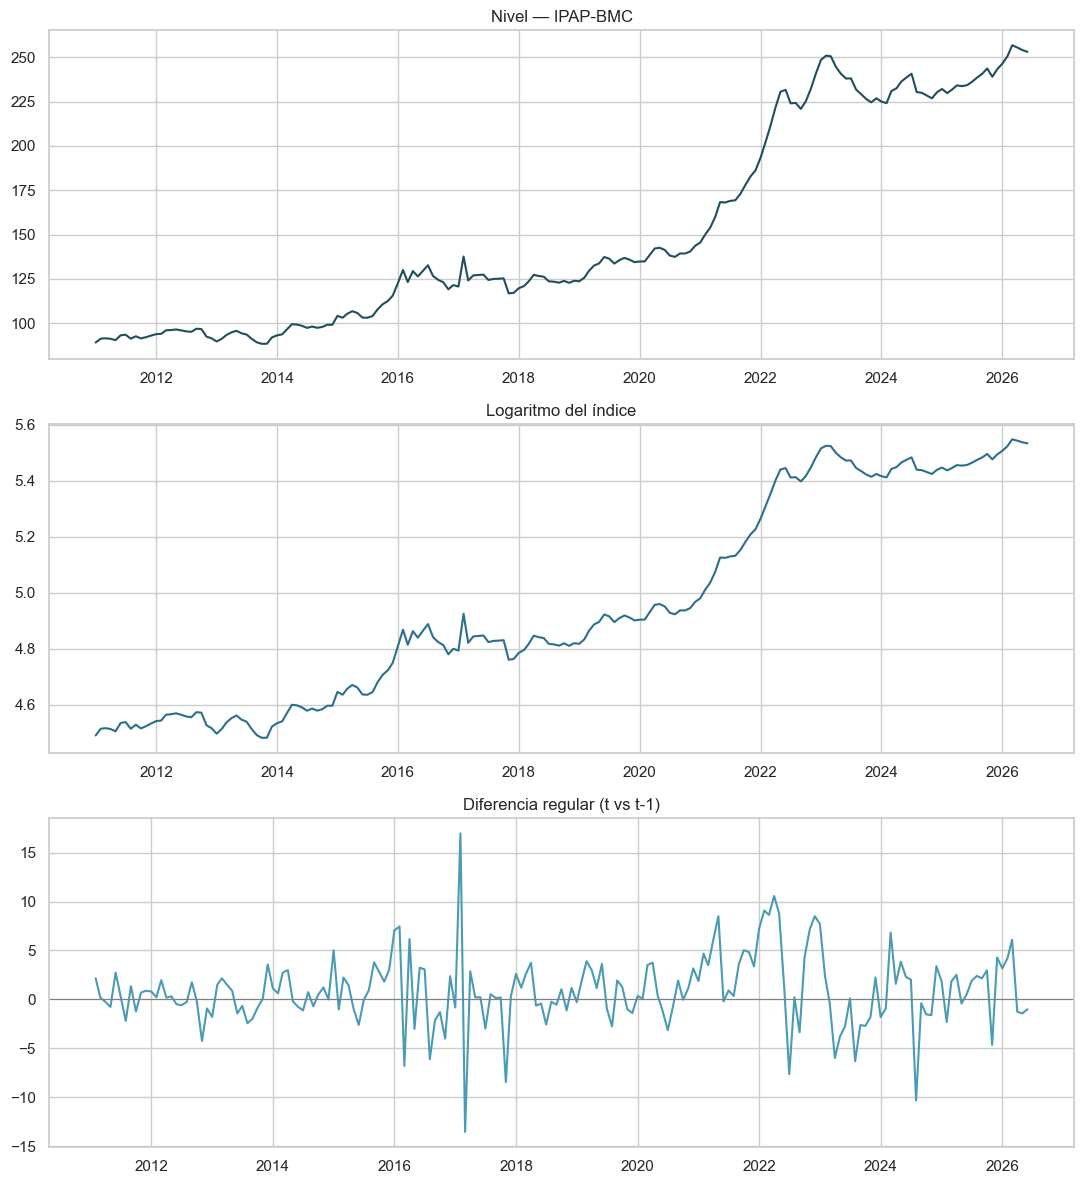

In [56]:
log_serie = np.log(serie)
diff_regular = serie.diff(1)          # diferencia mes a mes
 
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=False)
 
axes[0].plot(serie.index, serie, color="#1f4e5f")
axes[0].set_title("Nivel — IPAP-BMC")
 
axes[1].plot(log_serie.index, log_serie, color="#2a6f8f")
axes[1].set_title("Logaritmo del índice")
 
axes[2].plot(diff_regular.index, diff_regular, color="#4a9bb5")
axes[2].axhline(0, color="grey", linewidth=0.8)
axes[2].set_title("Diferencia regular (t vs t-1)")
 
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
 
plt.tight_layout()
plt.show()

### Estadística descriptiva

count    186.000000
mean     151.574930
std       56.729497
min       88.394000
25%       99.327225
50%      128.404650
75%      224.167725
max      256.720900
Name: Valor, dtype: float64
Número de observaciones: 198
Kurtosis: -1.2127428166265042
Asimetría: 0.6296107450274453


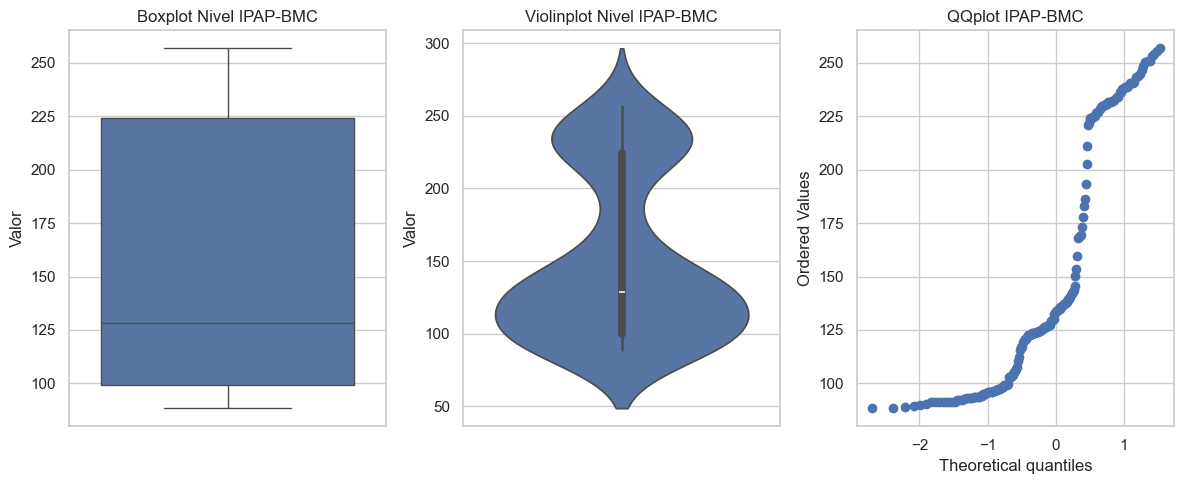

In [57]:
print(serie.describe())
print("Número de observaciones:", len(serie))
print("Kurtosis:", serie.kurt())
print("Asimetría:", serie.skew())

fig, axes = plt.subplots(1, 3, figsize=(12, 5)) 

sns.boxplot(data=serie, ax=axes[0])
axes[0].set_title("Boxplot Nivel IPAP-BMC")

sns.violinplot(data=serie, ax=axes[1])
axes[1].set_title("Violinplot Nivel IPAP-BMC")

stats.probplot(serie, dist="norm", plot=axes[2])
axes[2].set_title("QQplot IPAP-BMC")

plt.tight_layout()
plt.show()

# sns.violinplot(data=serie)

# plt.show()

# stats.probplot(datos, dist="norm", plot=plt)

# plt.title("Gráfico Q-Q con SciPy y Matplotlib")
# plt.grid(True)
# plt.show()

In [58]:
df = pd.read_csv("Data/Datos Tentativos.csv", sep=";", decimal=",") # Cargar la base de datos
df.columns = ["Fecha", "IPAP", "TRM", "IMP", "TEMP", "VOL"] # Cambiar los nombres de las variables
df["Fecha"] = pd.to_datetime(df["Fecha"], format="%YM%m").dt.to_period("M").dt.to_timestamp() # Pasar a formato fecha la columna correspondiente
df = df.sort_values("Fecha").set_index("Fecha") # Corroborar que los datos estén bien ordenados cronológicamente
df = df.asfreq("MS").astype(float) # fuerza frecuencia mensual (inicio de mes) y asegura que tengan decimales

print("Rango de fechas :", df.index.min().date(), "→", df.index.max().date())
print("N° observaciones:", len(df))
print("Valores nulos   :", df.isna().sum().sum())
df.tail()

Rango de fechas : 2011-01-01 → 2026-06-01
N° observaciones: 186
Valores nulos   : 0


,IPAP,TRM,IMP,TEMP,VOL
Fecha,,,,,
2026-02-01,250.6228,3672.62,106.99,20.693514,570.317363
2026-03-01,256.7209,3717.31,108.64,21.467204,645.667243
2026-04-01,255.4715,3613.54,111.46,22.260824,604.140973
2026-05-01,254.0342,3718.27,114.54,23.404377,620.008180
2026-06-01,253.0222,3504.64,116.10,22.603049,627.231433


## 2) Análisis de correlación 

Se evalúa la correlación lineal entre el IPAP-BMC y la TRM, el valor de las importaciones mediante el índice de términos de intercambio, la temperatura media del aire en el país y el volumen de transacciones de los 5 principales mercados que hacen parte del IPAP-BMC. Se aplica la CCF simple y blanqueada removiendo la autocorrelación de la serie IPAP-BMC. Además, se aplica el test de Granger.

Mediante estos tests se comprueba que únicamente el valor de las importaciones mediante el índice de términos de intercambio (IMP) tiene correlación con el IPAP-BMC en los rezagos 6, 12 y 24; lo que parece exhibir un comportamiento estacional. Se utiliza entonces IMP con rezago = 12 como variable exógena en los modelos.

IPAP: d = 1


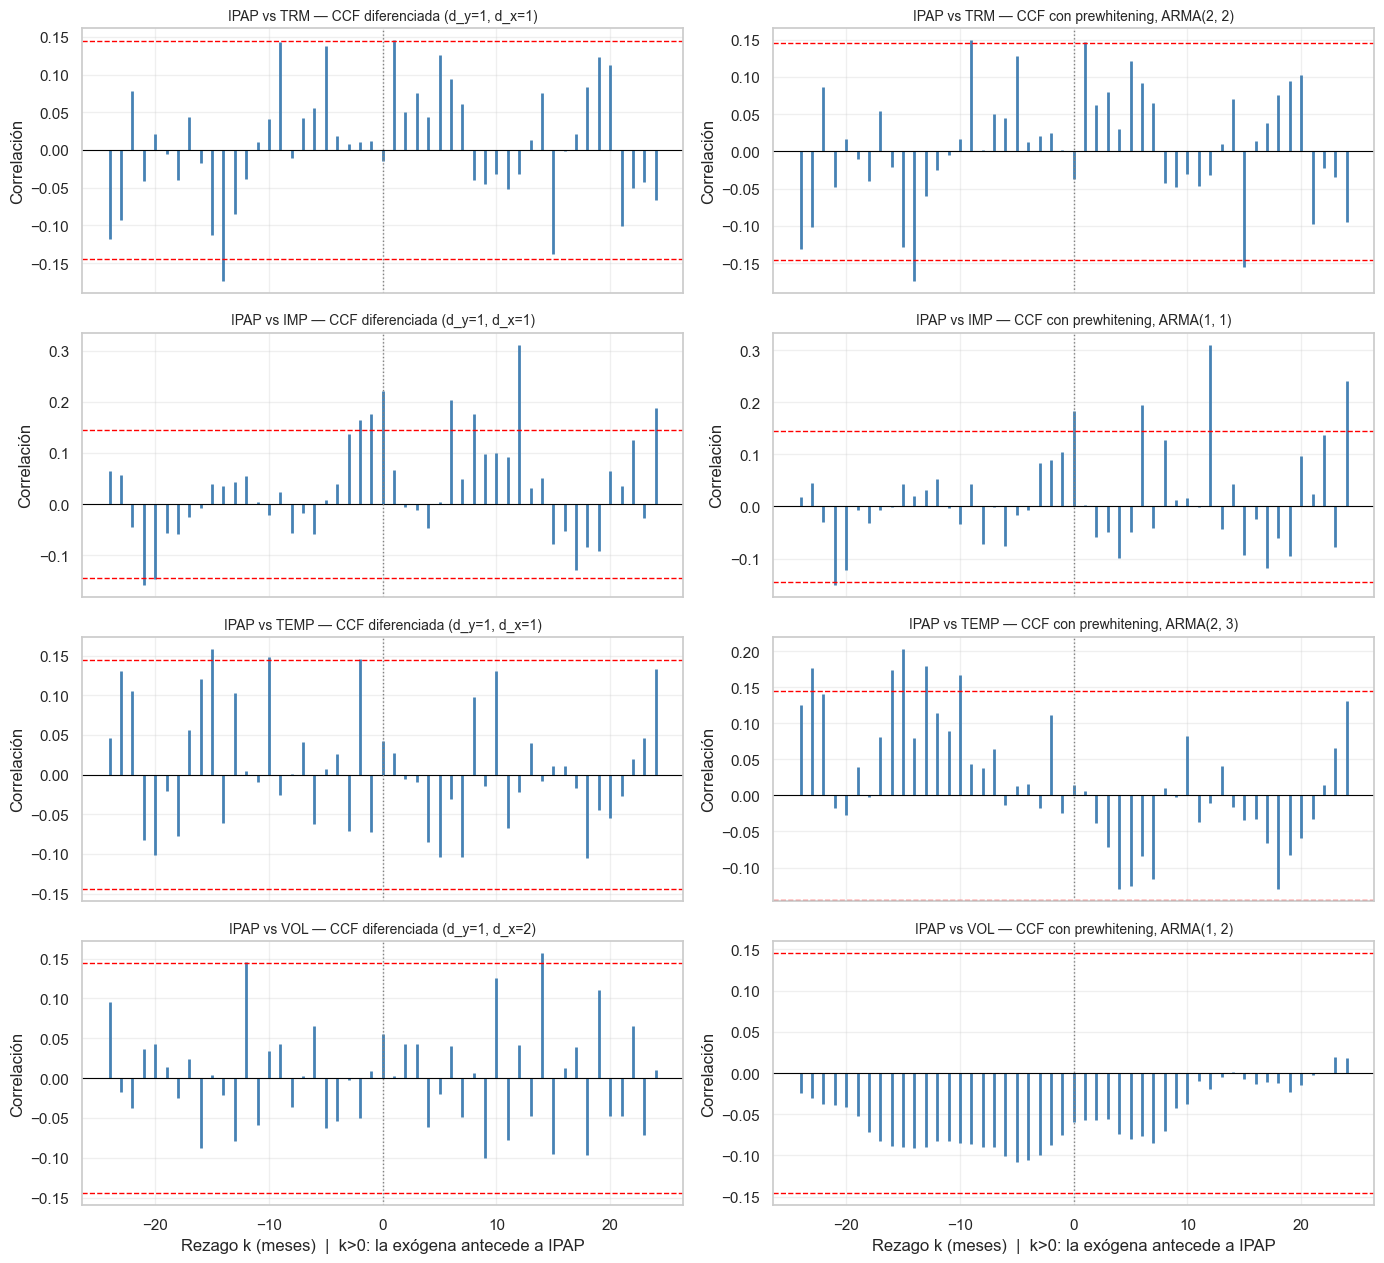


Resumen CCF con prewhitening (k ≥ 0):


,d_x,"ARMA(p,q)",banda ±95%,rezagos sig. (X→IPAP),máx |corr| (k≥0)
TRM,1,"(2, 2)",0.145,"[(1, 0.147), (15, -0.155)]",0.155
IMP,1,"(1, 1)",0.145,"[(0, 0.183), (6, 0.195), (12, 0.311), (24, 0.24)]",0.311
TEMP,1,"(2, 3)",0.146,[],0.131
VOL,2,"(1, 2)",0.146,[],0.085



Test de Granger: ¿la variable ayuda a predecir IPAP? (p-valor mínimo en rezagos 1-12)


,mejor rezago,p-valor
TRM,1.0,0.0414
IMP,12.0,0.0110
TEMP,7.0,0.4240
VOL,9.0,0.1911


In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 0. Parámetros
# ------------------------------------------------------------
TARGET = "IPAP"
EXOG = ["TRM", "IMP", "TEMP", "VOL"]
MAX_LAG = 24          # rezagos a evaluar (meses)
MAX_PQ = 3            # máximo p y q en la búsqueda del modelo de blanqueo

# ------------------------------------------------------------
# 1. Funciones auxiliares
# ------------------------------------------------------------
def hacer_estacionaria(s, max_d=2, alpha=0.05):
    """Diferencia la serie hasta que ADF rechace raíz unitaria."""
    d = 0
    x = s.copy()
    while d < max_d and adfuller(x.dropna())[1] > alpha:
        x = x.diff()
        d += 1
    return x.dropna(), d

def mejor_arma(x, max_pq=3):
    """Elige ARMA(p,q) por AIC sobre la serie ya estacionaria."""
    mejor = (np.inf, None, None)
    for p in range(max_pq + 1):
        for q in range(max_pq + 1):
            try:
                res = ARIMA(x, order=(p, 0, q)).fit()
                if res.aic < mejor[0]:
                    mejor = (res.aic, (p, 0, q), res)
            except Exception:
                continue
    return mejor[1], mejor[2]

def ccf(y, x, max_lag):
    """
    Correlación cruzada corr(y_t, x_{t-k}).
    k > 0  -> x ANTECEDE a y (lo útil para pronosticar)
    k < 0  -> y antecede a x
    """
    y, x = y.align(x, join="inner")
    ks = np.arange(-max_lag, max_lag + 1)
    vals = [y.corr(x.shift(k)) for k in ks]
    return ks, np.array(vals)

# ------------------------------------------------------------
# 2. Estacionariedad
# ------------------------------------------------------------
y_st, d_y = hacer_estacionaria(df[TARGET])
print(f"{TARGET}: d = {d_y}")

# ------------------------------------------------------------
# 3. CCF cruda (diferenciada) y CCF con prewhitening
# ------------------------------------------------------------
resultados = {}
ccf_res = {}   # datos de las CCF (para el tablero)
fig, axes = plt.subplots(len(EXOG), 2, figsize=(14, 3.2 * len(EXOG)), sharex=True)

for i, var in enumerate(EXOG):
    x_st, d_x = hacer_estacionaria(df[var])

    # --- CCF de series diferenciadas (sin blanquear) ---
    ks, c_raw = ccf(y_st, x_st, MAX_LAG)
    n_raw = len(y_st.align(x_st, join="inner")[0])
    band_raw = 1.96 / np.sqrt(n_raw)

    # --- Prewhitening: ajustar ARMA a X, aplicar el mismo filtro a Y ---
    orden, res_x = mejor_arma(x_st, MAX_PQ)
    burn = max(orden[0], orden[2]) + 1
    alpha_x = res_x.resid.iloc[burn:]                       # X blanqueada
    # Y filtrada con el MISMO modelo (parámetros de X)
    y_alineada = y_st.reindex(x_st.index).dropna()
    beta_y = res_x.apply(y_alineada).resid.iloc[burn:]      # Y filtrada

    ks, c_pw = ccf(beta_y, alpha_x, MAX_LAG)
    n_pw = len(beta_y.align(alpha_x, join="inner")[0])
    band_pw = 1.96 / np.sqrt(n_pw)

    # --- Gráficos ---
    for ax, c, band, titulo in [
        (axes[i, 0], c_raw, band_raw, f"{TARGET} vs {var} — CCF diferenciada (d_y={d_y}, d_x={d_x})"),
        (axes[i, 1], c_pw,  band_pw,  f"{TARGET} vs {var} — CCF con prewhitening, ARMA{(orden[0], orden[2])}"),
    ]:
        ax.vlines(ks, 0, c, color="steelblue", lw=2)
        ax.axhline(0, color="black", lw=0.8)
        ax.axhline(band, color="red", ls="--", lw=1)
        ax.axhline(-band, color="red", ls="--", lw=1)
        ax.axvline(0, color="gray", ls=":", lw=1)
        ax.set_title(titulo, fontsize=10)
        ax.set_ylabel("Correlación")
        ax.grid(alpha=0.3)

    # --- Rezagos significativos donde X antecede a Y (k >= 0) ---
    sig = [(int(k), round(float(c), 3)) for k, c in zip(ks, c_pw)
           if k >= 0 and abs(c) > band_pw]
    ccf_res[var] = dict(ks=ks.tolist(), raw=c_raw.tolist(), pw=c_pw.tolist(), band_raw=float(band_raw),
                        band_pw=float(band_pw), d_x=int(d_x), arma=(orden[0], orden[2]))
    resultados[var] = {
        "d_x": d_x,
        "ARMA(p,q)": (orden[0], orden[2]),
        "banda ±95%": round(band_pw, 3),
        "rezagos sig. (X→IPAP)": sig,
        "máx |corr| (k≥0)": round(float(np.max(np.abs(c_pw[ks >= 0]))), 3),
    }

axes[-1, 0].set_xlabel("Rezago k (meses)  |  k>0: la exógena antecede a IPAP")
axes[-1, 1].set_xlabel("Rezago k (meses)  |  k>0: la exógena antecede a IPAP")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Resumen
# ------------------------------------------------------------
resumen = pd.DataFrame(resultados).T
pd.set_option("display.max_colwidth", None)
print("\nResumen CCF con prewhitening (k ≥ 0):")
display(resumen)

# ------------------------------------------------------------
# 5. (Complemento) Test de causalidad de Granger sobre series estacionarias
# ------------------------------------------------------------
print("\nTest de Granger: ¿la variable ayuda a predecir IPAP? (p-valor mínimo en rezagos 1-12)")
granger = {}
for var in EXOG:
    x_st, _ = hacer_estacionaria(df[var])
    datos = pd.concat([y_st, x_st], axis=1, join="inner").dropna()
    datos.columns = [TARGET, var]
    out = grangercausalitytests(datos[[TARGET, var]], maxlag=12)
    pvals = {lag: out[lag][0]["ssr_ftest"][1] for lag in out}
    mejor_lag = min(pvals, key=pvals.get)
    granger[var] = {"mejor rezago": mejor_lag, "p-valor": round(pvals[mejor_lag], 4)}
display(pd.DataFrame(granger).T)

### Análisis de estacionalidad del IPAP

Según la ACF, no se encuentra evidencia de correlación que indique estacionalidad anual (probable al ser datos mensuales), por tanto, se descarta aplicar un modelo estacional

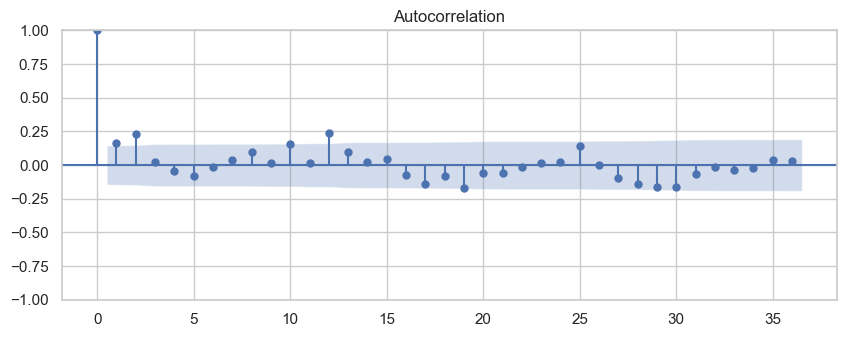

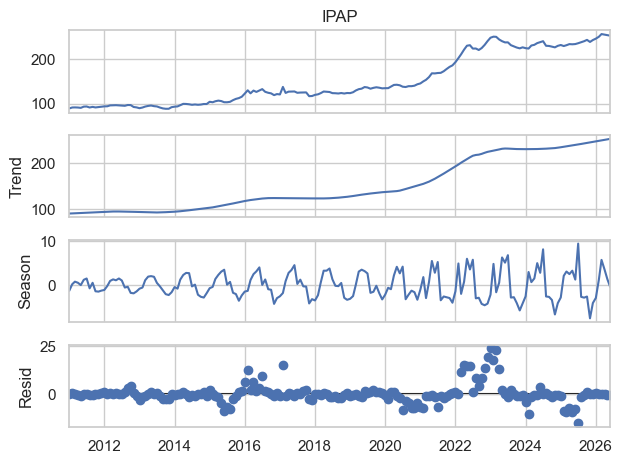

In [60]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

y_diff = df["IPAP"].diff().dropna()

# 1. ACF: busca picos en 12, 24, 36
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(y_diff, lags=36, ax=ax)
plt.show()

# 2. Descomposición STL sobre la serie original
STL(df["IPAP"], period=12, robust=True).fit().plot()
plt.show()

## 3) Modelos Econométricos

### Cargar la base de datos con las dos series

In [61]:
df = pd.read_csv("Data/Datos.csv", sep=";", decimal=",") # Cargar la base de datos
df.columns = ["Fecha", "IPAP", "IMP"] # Cambiar los nombres de las variables
df["Fecha"] = pd.to_datetime(df["Fecha"], format="%YM%m").dt.to_period("M").dt.to_timestamp() # Pasar a formato fecha la columna correspondiente
df = df.sort_values("Fecha") # Corroborar que los datos estén bien ordenados cronológicamente
# df = df.asfreq("MS").astype(float) # fuerza frecuencia mensual (inicio de mes) y asegura que tengan decimales

# print("Rango de fechas :", df.index.min().date(), "→", df.index.max().date())
print("N° observaciones:", len(df))
print("Valores nulos   :", df.isna().sum().sum())
df.head()

N° observaciones: 198
Valores nulos   : 12


,Fecha,IPAP,IMP
0,2010-01-01,NaN,117.12
1,2010-02-01,NaN,116.31
2,2010-03-01,NaN,115.82
3,2010-04-01,NaN,116.24
4,2010-05-01,NaN,116.01


### 3.1) Modelo ARIMAX

El ARIMAX es un modelo ARIMA(p,d,q) al que se le agrega una regresión sobre una variable exógena. Aquí se aplica al logaritmo del IPAP y la exógena es el IMP rezagado 12 meses, el rezago con el que se encontró correlación en la sección 2:

$$\log(IPAP_t) = \delta\,t + \beta\,IMP_{t-12} + \eta_t, \qquad \eta_t \sim ARIMA(p,1,q)$$

* **Logaritmo:** estabiliza la varianza (el índice crece y su variabilidad crece con el nivel) y hace que las diferencias se lean como variaciones porcentuales.
* **Deriva ($\delta$):** como $d=1$, equivale a un crecimiento medio mensual constante del IPAP.
* **Coeficiente $\beta$:** asociación entre el IMP de hace 12 meses y el nivel del IPAP.
* **Ventaja del rezago de 12 meses:** para pronosticar los 12 meses siguientes solo se necesitan valores de IMP ya observados, así que no hace falta proyectar la exógena.
* **Elección del orden:** a diferencia de ETS, Elastic Net y XGBoost, el orden $(p,q)$ se elige con el criterio de información AIC sobre el entrenamiento, sin validación walk-forward. La prueba no interviene en ninguna decisión.
* El modelo entrega además un intervalo de predicción del 90 %, comparable con el de Prophet y ETS.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia evaluación. Las etapas 1 y 2 de la metodología hold-out corresponden a los pasos 3 a 10, y la etapa 3 a los pasos 11 y 12. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos y rezagar el regresor IMP
3. Partición en entrenamiento y prueba
4. Estacionariedad: elección de $d$
5. ACF y PACF de la serie diferenciada
6. Selección de $(p, q)$
7. Estimación y diagnóstico de residuos
8. Predicción en prueba
9. Gráfica de la predicción
10. Métricas de error en prueba (RMSE y MAPE)
11. Pronóstico final con toda la información histórica
12. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (`statsmodels` para el modelo ARIMAX y sus pruebas) y se fijan los parámetros que **no** se optimizan:

* `HORIZONTE`: meses a pronosticar y que se reservan para prueba (12).
* `INTERVALO`: ancho del intervalo de predicción (0.9 = 90 %, igual que en Prophet y ETS).
* `REZAGO_IMP`: rezago en meses del regresor IMP (12).
* `RANGO_PQ`: valores de $p$ y $q$ que se evalúan en la búsqueda (0 a 3).

In [62]:
# Librerías a utilizar
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy.stats as stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
HORIZONTE = 12      # meses a pronosticar (mismo test que en Prophet)
INTERVALO = 0.9     # intervalo de predicción del 90 %
REZAGO_IMP = 12     # rezago (meses) del regresor IMP
RANGO_PQ = range(4) # valores de p y q que se evalúan: 0 a 3

#### 2) Cargar la base de datos y rezagar el regresor IMP

Se cargan los datos y se renombran las columnas como en Prophet: `ds` (fecha), `y` (IPAP) e `IMP`. Se da formato de fecha mensual y se usa la fecha como índice, que es el formato que exige `statsmodels`.

El regresor IMP se rezaga 12 meses: el valor de IMP en $t-12$ se asigna a la fecha $t$ (`IMP_l12`). El rezago se calcula sobre la serie completa de IMP, que empieza en enero de 2010, **antes** de recortar a las fechas con IPAP observado (desde enero de 2011), de modo que no se pierde ninguna observación. También se guarda el logaritmo del IPAP (`log_y`), que es la variable que modela el ARIMAX.

In [63]:
# Serie completa de IMP, sin recortar (empieza en ene-2010, un año antes que el IPAP)
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")
datos = datos.set_index("ds").asfreq("MS")

# Regresor rezagado: el valor de IMP en (t - 12 meses) se asigna a la fecha t
datos["IMP_l12"] = datos["IMP"].shift(REZAGO_IMP)      # se rezaga ANTES de recortar la serie
imp_completa = datos["IMP"].copy()                     # se conserva para el pronóstico final

# Solo fechas con IPAP observado, y su logaritmo
datos = datos.dropna(subset=["y"]).copy()
datos["log_y"] = np.log(datos["y"])

print("Rango de fechas :", datos.index.min().date(), "→", datos.index.max().date())
print("N° observaciones:", len(datos))
print("Faltantes en IMP_l12:", datos["IMP_l12"].isna().sum())
datos.tail()

Rango de fechas : 2011-01-01 → 2026-06-01
N° observaciones: 186
Faltantes en IMP_l12: 0


,y,IMP,IMP_l12,log_y
ds,,,,
2026-02-01,250.6228,106.99,108.66,5.523949
2026-03-01,256.7209,108.64,109.16,5.547990
2026-04-01,255.4715,111.46,109.93,5.543111
2026-05-01,254.0342,114.54,107.96,5.537469
2026-06-01,253.0222,116.10,108.22,5.533477


#### 3) Partición en entrenamiento y prueba

La partición es temporal y sigue la metodología hold-out:

* **Prueba:** los últimos 12 meses (jul-2025 a jun-2026). No intervienen en ninguna decisión del modelo.
* **Entrenamiento:** todo lo anterior (174 observaciones, por encima del mínimo sugerido de 48). Con este conjunto se decide la diferenciación $d$, el orden $(p,q)$ y se estiman los parámetros.

El código verifica que no haya fuga de información: el `IMP_l12` de los meses de prueba usa valores de IMP hasta jun-2025, que ya eran conocidos al momento de pronosticar.

In [64]:
# Últimos 12 meses -> prueba | el resto -> entrenamiento
test = datos.iloc[-HORIZONTE:].copy()
train = datos.iloc[:-HORIZONTE].copy()

# Controles: mínimo de 48 observaciones y sin fuga de información
assert len(train) >= 48
assert test.index[-1] - pd.DateOffset(months=REZAGO_IMP) <= train.index[-1]   # IMP_l12 de la prueba usa solo IMP ya observado

print("Entrenamiento:", len(train), "|", train.index.min().date(), "→", train.index.max().date())
print("Prueba       :", len(test),  "|", test.index.min().date(),  "→", test.index.max().date())

Entrenamiento: 174 | 2011-01-01 → 2025-06-01
Prueba       : 12 | 2025-07-01 → 2026-06-01


#### 4) Estacionariedad: elección de $d$

Un ARIMA requiere una serie estacionaria; el número de diferencias necesarias es el parámetro $d$. Se aplican dos pruebas con hipótesis nulas opuestas, para buscar veredictos coherentes:

* **ADF:** H0 = hay raíz unitaria (no estacionaria). Un p-valor bajo indica estacionariedad.
* **KPSS:** H0 = la serie es estacionaria. Un p-valor bajo indica que no lo es (`statsmodels` lo reporta acotado entre 0.01 y 0.10).

Se evalúan el log del IPAP y el IMP rezagado, en niveles y en diferencias, usando solo el entrenamiento.

In [65]:
def pruebas_raiz_unitaria(nombre, s):
    s = s.dropna()
    print(f"{nombre:12s} ADF p = {adfuller(s)[1]:.3f} | KPSS p = {kpss(s, nlags='auto')[1]:.3f}")

# Solo con el entrenamiento
pruebas_raiz_unitaria("log IPAP", train["log_y"])
pruebas_raiz_unitaria("Δ log IPAP", train["log_y"].diff())
pruebas_raiz_unitaria("Δ² log IPAP", train["log_y"].diff().diff())
pruebas_raiz_unitaria("IMP_l12", train["IMP_l12"])
pruebas_raiz_unitaria("Δ IMP_l12", train["IMP_l12"].diff())

log IPAP     ADF p = 0.787 | KPSS p = 0.010
Δ log IPAP   ADF p = 0.000 | KPSS p = 0.100
Δ² log IPAP  ADF p = 0.000 | KPSS p = 0.042
IMP_l12      ADF p = 0.499 | KPSS p = 0.019
Δ IMP_l12    ADF p = 0.000 | KPSS p = 0.100


**Lectura:** en niveles, el log del IPAP no es estacionario (ADF no rechaza la raíz unitaria, KPSS rechaza la estacionariedad). En primera diferencia ambas pruebas coinciden en que la serie es estacionaria (ADF p < 0.001 y KPSS p ≥ 0.10), por lo que se toma **$d = 1$**. Con una segunda diferencia el KPSS vuelve a rechazar (p ≈ 0.04), señal de que ya no hace falta diferenciar más. Esto coincide con el $d=1$ de la sección 2.

El IMP rezagado también necesita una diferencia. Como el modelo tiene $d=1$, el efecto del IMP se estima sobre la serie diferenciada (regresión con errores ARIMA), lo que evita relaciones espurias entre dos series con tendencia. La serie $\Delta\log IPAP$ se interpreta como la variación porcentual mensual del índice.

#### 5) ACF y PACF de la serie diferenciada

Se grafican la autocorrelación (ACF) y la autocorrelación parcial (PACF) de $\Delta\log IPAP$ con el entrenamiento. Sirven para identificar los órdenes $p$ (AR) y $q$ (MA) candidatos y para revisar si hay patrón estacional en los rezagos 12, 24 y 36.

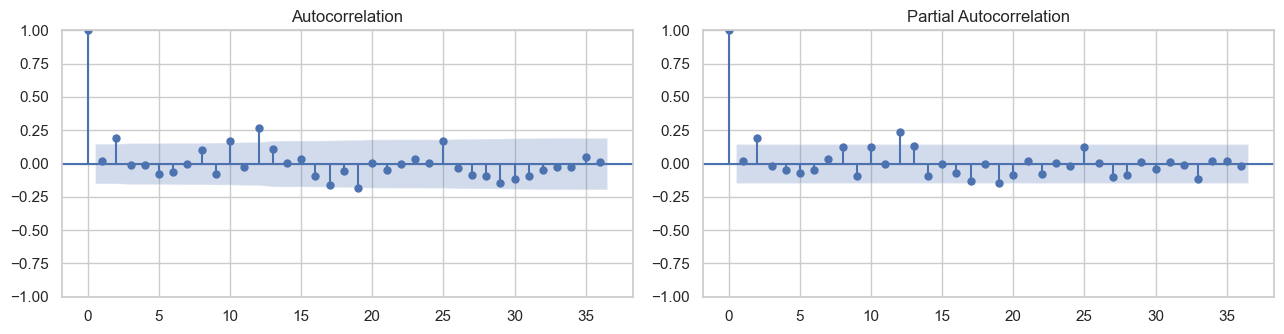

In [66]:
dlog = train["log_y"].diff().dropna()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(dlog, lags=36, ax=ax[0])
plot_pacf(dlog, lags=36, ax=ax[1], method="ywm")
plt.tight_layout()
plt.show()

**Lectura:** la autocorrelación del primer rezago es prácticamente cero y la del rezago 2 es la primera que se sale de la banda (≈ 0.19), lo que sugiere órdenes bajos: candidatos MA(2) o AR(2). En el rezago 12 hay una autocorrelación moderada (≈ 0.27), pero aislada: en los rezagos 24 y 36 es prácticamente cero, de modo que no hay un patrón estacional que se repita año a año. Al probar un término estacional de periodo 12 sobre este mismo modelo, el AIC mejora solo unos 2 puntos, el BIC empeora y el MAPE en prueba no mejora (de 2.84 % a 2.88 % o 3.14 %). Por eso se mantiene un ARIMAX sin componente estacional, en línea con la sección 2.

#### 6) Selección de $(p, q)$

Con $d=1$ fijo, se ajustan todas las combinaciones de $p$ y $q$ entre 0 y 3, **con y sin** IMP rezagado, usando solo el entrenamiento, y se comparan con el AIC y el BIC:

* **AIC:** mide el ajuste penalizando el número de parámetros; es el criterio de selección.
* **BIC:** penaliza más la complejidad y favorece modelos más parsimoniosos; se usa como referencia.

Se incluye una deriva (`trend="t"`): con $d=1$ equivale a una constante en la serie diferenciada, es decir, un crecimiento medio mensual. La especificación seleccionada es la de menor AIC entre las que incluyen IMP.

In [67]:
def ajustar_arimax(y, X, orden):
    # d = 1 con deriva (trend="t"): equivale a un crecimiento medio mensual constante del log-IPAP
    return ARIMA(y, exog=X, order=orden, trend="t").fit()

filas = []
for p, q in itertools.product(RANGO_PQ, RANGO_PQ):
    for con_imp in (True, False):
        try:
            r = ajustar_arimax(train["log_y"], train[["IMP_l12"]] if con_imp else None, (p, 1, q))
            filas.append({"p": p, "q": q, "con IMP": con_imp, "AIC": r.aic, "BIC": r.bic})
        except Exception:
            pass
grilla = pd.DataFrame(filas)

print("Mejores 8 especificaciones por AIC")
display(grilla.sort_values("AIC").head(8).round(1).reset_index(drop=True))
print("Mejores 5 por BIC")
display(grilla.sort_values("BIC").head(5).round(1).reset_index(drop=True))

print("Mejor AIC con IMP:", round(grilla[grilla["con IMP"]]["AIC"].min(), 1),
      "| Mejor AIC sin IMP:", round(grilla[~grilla["con IMP"]]["AIC"].min(), 1))

# Especificación seleccionada: menor AIC entre las que incluyen IMP
mejor = grilla[grilla["con IMP"]].sort_values("AIC").iloc[0]
ORDEN = (int(mejor["p"]), 1, int(mejor["q"]))
print("Especificación seleccionada: ARIMAX", ORDEN, "+ deriva + IMP_l12")

Mejores 8 especificaciones por AIC


,p,q,con IMP,AIC,BIC
0,0,2,True,-800.2,-784.4
1,2,0,True,-799.9,-784.2
2,0,3,True,-798.8,-779.9
3,1,2,True,-798.7,-779.8
4,2,2,True,-798.5,-776.4
5,3,0,True,-798.0,-779.1
6,2,1,True,-798.0,-779.0
7,2,3,True,-797.7,-772.5


Mejores 5 por BIC


,p,q,con IMP,AIC,BIC
0,0,0,True,-797.5,-788.1
1,0,2,True,-800.2,-784.4
2,2,0,True,-799.9,-784.2
3,1,0,True,-795.7,-783.1
4,0,1,True,-795.6,-783.0


Mejor AIC con IMP: -800.2 | Mejor AIC sin IMP: -790.7
Especificación seleccionada: ARIMAX (0, 1, 2) + deriva + IMP_l12


**Lectura:** las 8 mejores especificaciones por AIC incluyen el IMP rezagado, y el mejor AIC con IMP (≈ −800.2) es unos 9.5 puntos menor que el mejor sin IMP (≈ −790.7). ARIMAX(0,1,2) y ARIMAX(2,1,0) quedan prácticamente empatados (diferencia de AIC menor que 0.3). El BIC, que penaliza más la complejidad, prefiere un modelo más simple, el (0,1,0). Se selecciona **ARIMAX(0,1,2)** por tener el menor AIC.

#### 7) Estimación y diagnóstico de residuos

Se estima el ARIMAX seleccionado **solo con el entrenamiento** y se revisan los residuos, que deberían comportarse como ruido blanco:

* **Ljung-Box:** H0 = no hay autocorrelación en los residuos.
* **Jarque-Bera:** H0 = los residuos son normales.
* Gráficos: residuos en el tiempo, su ACF, histograma y Q-Q normal.

Se descarta el primer residuo, que corresponde a la inicialización de la diferencia.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift          0.0057      0.002      2.277      0.023       0.001       0.011
IMP_l12        0.0034      0.001      3.609      0.000       0.002       0.005
ma.L1          0.0083      0.051      0.164      0.870      -0.091       0.108
ma.L2          0.1960      0.090      2.185      0.029       0.020       0.372
sigma2         0.0005   3.34e-05     16.179      0.000       0.000       0.001

Ljung-Box (H0: sin autocorrelación)


,lb_stat,lb_pvalue
6,2.935,0.817
12,15.768,0.202
24,26.360,0.335


Jarque-Bera p-valor: 0.0


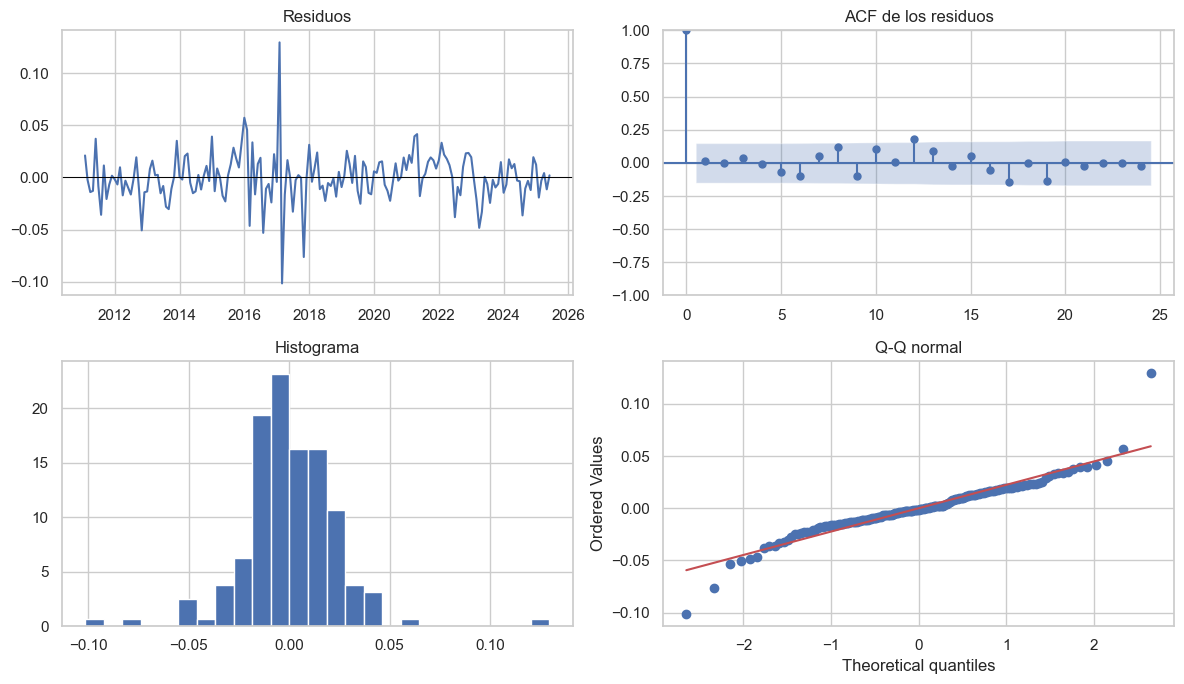

In [68]:
modelo_arimax = ajustar_arimax(train["log_y"], train[["IMP_l12"]], ORDEN)
print(modelo_arimax.summary().tables[1])

resid = modelo_arimax.resid.iloc[1:]      # se descarta el primer residuo (inicialización de la diferencia)
print("\nLjung-Box (H0: sin autocorrelación)")
display(acorr_ljungbox(resid, lags=[6, 12, 24]).round(3))
print("Jarque-Bera p-valor:", round(stats.jarque_bera(resid)[1], 4))

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(resid); ax[0, 0].axhline(0, color="black", lw=0.7); ax[0, 0].set_title("Residuos")
plot_acf(resid, lags=24, ax=ax[0, 1]); ax[0, 1].set_title("ACF de los residuos")
ax[1, 0].hist(resid, bins=25, density=True); ax[1, 0].set_title("Histograma")
stats.probplot(resid, plot=ax[1, 1]); ax[1, 1].set_title("Q-Q normal")
plt.tight_layout()
plt.show()

**Lectura:**

* **IMP_l12** es positivo y significativo ($\hat\beta \approx 0.0034$, p < 0.001): un punto más de IMP doce meses atrás se asocia con un nivel de IPAP ≈ 0.34 % mayor (el coeficiente está sobre el logaritmo). Es una asociación predictiva, no una relación causal.
* **Deriva** ($\hat\delta \approx 0.0057$, p = 0.023): crecimiento tendencial de ≈ 0.57 % mensual.
* **MA:** el término MA(1) no es significativo; el MA(2) sí ($\hat\theta_2 \approx 0.196$, p = 0.029).
* **Ljung-Box:** p-valores de 0.82, 0.20 y 0.34 en los rezagos 6, 12 y 24; no se rechaza la ausencia de autocorrelación, así que el modelo captura la dinámica de la serie.
* **Jarque-Bera:** rechaza la normalidad (colas pesadas, habitual en choques de precios agropecuarios). Los intervalos de predicción son, por tanto, aproximados.

#### 8) Predicción en prueba

Con el modelo ya entrenado (sin volver a ajustarlo) se pronostican los 12 meses de prueba, **sin incorporar sus valores reales**. El único insumo externo es `IMP_l12`, que para esos meses corresponde a IMP de jul-2024 a jun-2025, ya observado.

El modelo trabaja en logaritmos, así que el pronóstico y los límites del intervalo del 90 % se devuelven a la escala del IPAP con la exponencial.

In [69]:
# IMP_l12 de la prueba: son valores de IMP ya observados (jul-2024 a jun-2025)
pr = modelo_arimax.get_forecast(HORIZONTE, exog=test[["IMP_l12"]])
ic = pr.conf_int(alpha=1 - INTERVALO)

# El modelo trabaja en logaritmos: se regresa a la escala del IPAP con la exponencial
pred_arimax = np.exp(pr.predicted_mean.values)

# Tabla real vs. predicho
res_arimax = test[["y"]].reset_index()
res_arimax["yhat"] = pred_arimax
res_arimax["yhat_lower"] = np.exp(ic.iloc[:, 0].values)
res_arimax["yhat_upper"] = np.exp(ic.iloc[:, 1].values)

print("Prueba:")
display(res_arimax.round(2))

Prueba:


,ds,y,yhat,yhat_lower,yhat_upper
0,2025-07-01,236.09,234.33,225.53,243.46
1,2025-08-01,238.49,234.36,221.96,247.44
2,2025-09-01,240.65,235.69,219.48,253.09
3,2025-10-01,243.62,235.97,216.78,256.87
4,2025-11-01,238.98,236.66,214.88,260.65
5,2025-12-01,243.25,237.02,212.97,263.78
6,2026-01-01,246.42,238.43,212.21,267.88
7,2026-02-01,250.62,241.13,212.74,273.31
8,2026-03-01,256.72,242.92,212.57,277.61
9,2026-04-01,255.47,244.95,212.70,282.10


#### 9) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba y su intervalo del 90 %. La zona sombreada indica el periodo de prueba.

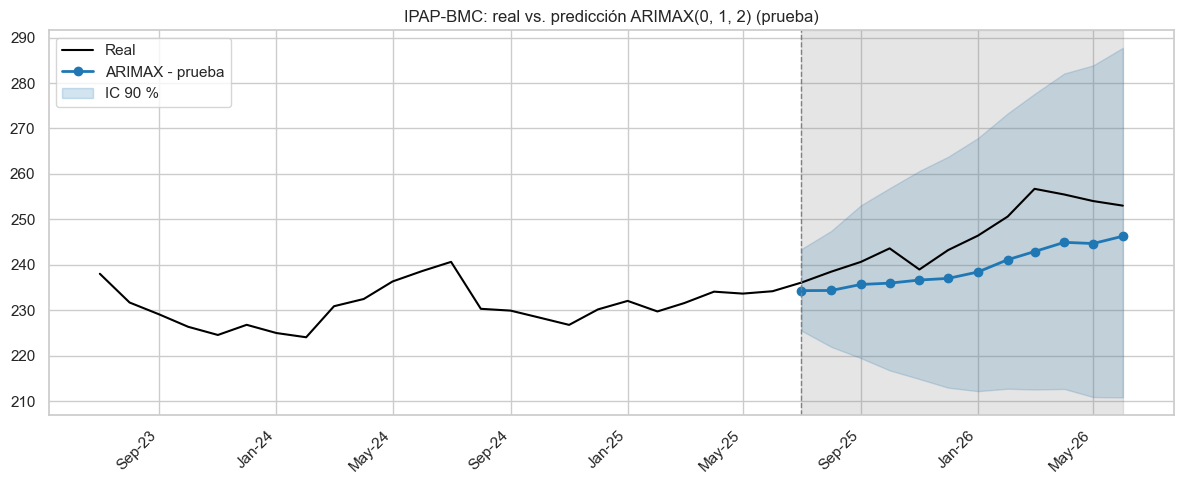

In [70]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos.index[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test.index, pred_arimax, color="#1f78b4", marker="o", lw=2, label="ARIMAX - prueba")
ax.fill_between(test.index, res_arimax["yhat_lower"], res_arimax["yhat_upper"], color="#1f78b4", alpha=0.2, label="IC 90 %")

ax.axvspan(test.index[0], test.index[-1], color="grey", alpha=0.20)
ax.axvline(test.index[0], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: real vs. predicción ARIMAX{ORDEN} (prueba)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 10) Métricas de error en prueba (RMSE y MAPE)

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP (las mismas métricas de Prophet, ETS, Elastic Net, XGBoost, LSTM y GRU). Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

Como referencia se evalúan, sobre la misma prueba, el mismo modelo **sin** IMP y el baseline Naïve (repetir el último valor del entrenamiento).

In [ ]:
# Finalistas del ARIMAX: la misma especificación (p,1,q) elegida por AIC en el paso 6, con y sin IMP rezagado
def rmse_mape(pred):
    """RMSE y MAPE (%) frente a la prueba, en la escala original del IPAP."""
    real = test["y"].values
    pred = np.asarray(pred, dtype=float)
    rmse = np.sqrt(np.mean((real - pred) ** 2))
    mape = np.mean(np.abs(real - pred) / np.abs(real)) * 100
    return rmse, mape

candidatos = {}   # con_imp -> (nombre, orden, X_train, X_test)
filas = []
for con_imp in (True, False):
    X_tr = train[["IMP_l12"]] if con_imp else None
    X_te = test[["IMP_l12"]] if con_imp else None
    nombre = f"ARIMAX{ORDEN} + deriva + IMP_l12" if con_imp else f"ARIMA{ORDEN} + deriva"

    modelo = ajustar_arimax(train["log_y"], X_tr, ORDEN)
    pred = np.exp(modelo.get_forecast(HORIZONTE, exog=X_te).predicted_mean.values)
    rmse, mape = rmse_mape(pred)

    candidatos[con_imp] = (nombre, ORDEN, X_tr, X_te)
    filas.append({"modelo": nombre, "con IMP": con_imp, "RMSE": rmse, "MAPE (%)": mape})

tabla_seleccion = pd.DataFrame(filas).set_index("modelo")
display(tabla_seleccion.round(3))


In [52]:
# Ganador: el de menor MAPE hold-out entre los finalistas (con o sin IMP)
nombre_ganador = tabla_seleccion["MAPE (%)"].idxmin()
CON_IMP = bool(tabla_seleccion.loc[nombre_ganador, "con IMP"])
_, ORDEN, X_tr_g, X_te_g = candidatos[CON_IMP]

# Se reestima el ganador con el entrenamiento y se pronostica la prueba
modelo_arimax = ajustar_arimax(train["log_y"], X_tr_g, ORDEN)
pr = modelo_arimax.get_forecast(HORIZONTE, exog=X_te_g)
ic = pr.conf_int(alpha=1 - INTERVALO)
pred_arimax = np.exp(pr.predicted_mean.values)

# Tabla real vs. predicho del ganador (la usa el tablero)
res_arimax = test[["y"]].reset_index()
res_arimax["yhat"] = pred_arimax
res_arimax["yhat_lower"] = np.exp(ic.iloc[:, 0].values)
res_arimax["yhat_upper"] = np.exp(ic.iloc[:, 1].values)

rmse_arimax, mape_arimax = rmse_mape(pred_arimax)
metricas_arimax = pd.DataFrame({"Prueba": [rmse_arimax, mape_arimax]}, index=["RMSE", "MAPE (%)"])

print(f"Modelo seleccionado (menor MAPE hold-out): {nombre_ganador}")
display(metricas_arimax.round(3))

# Tabla comparativa: finalistas + Naïve, con el ganador marcado
pred_naive = np.repeat(train["y"].iloc[-1], HORIZONTE)
referencias = pd.concat([
    tabla_seleccion[["RMSE", "MAPE (%)"]],
    pd.DataFrame([rmse_mape(pred_naive)], columns=["RMSE", "MAPE (%)"], index=["Naïve"])
])
referencias["Seleccionado"] = ["✔" if i == nombre_ganador else "" for i in referencias.index]
display(referencias.round(3))

# Control: lo reportado debe coincidir con el menor MAPE de la tabla
assert np.isclose(mape_arimax, tabla_seleccion["MAPE (%)"].min())

Modelo seleccionado (menor MAPE hold-out): ARIMA(0, 1, 2) + deriva


,Prueba
RMSE,5.251
MAPE (%),1.738


,RMSE,MAPE (%),Seleccionado
"ARIMAX(0, 1, 2) + deriva + IMP_l12",7.827,2.840,
"ARIMA(0, 1, 2) + deriva",5.251,1.738,✔
Naïve,14.096,4.895,


**Lectura:** el ARIMAX tiene un RMSE de 7.83 y un MAPE de 2.84 % en prueba. Frente al Naïve (MAPE de 4.90 %), reduce el RMSE en ≈ 44 % y el MAPE en ≈ 42 %, así que aporta valor sobre ese baseline. El mismo modelo sin IMP obtiene un MAPE de 1.74 %: en esta ventana de 12 meses, el IMP rezagado no mejora el pronóstico, aunque su coeficiente es significativo en el entrenamiento.

La prueba es una sola ventana en la que el IPAP subió de forma sostenida: el modelo (con y sin IMP) queda por debajo del valor real durante la segunda mitad, porque la deriva estimada con el entrenamiento es menor que el ritmo de alza de esos meses. El intervalo del 90 % contiene los 12 valores observados.

#### 11) Pronóstico final con toda la información histórica

Esta es la etapa 3 de la metodología hold-out. Una vez medido el desempeño en prueba, el modelo se reestima con **toda la serie**, incluidos los 12 meses que antes se reservaron para prueba, y se pronostican los 12 meses siguientes al último dato observado (jul-2026 a jun-2027).

* **Especificación:** es la seleccionada en el paso 6 (`ORDEN`). No se vuelve a escoger, pues la prueba ya hace parte del entrenamiento; solo se reestiman los parámetros con más datos.
* **Regresor futuro:** para pronosticar la fecha $t+h$ se usa el IMP de $t+h-12$, observado hasta jun-2026, por lo que no hay que proyectar el IMP.
* **Intervalo:** se calcula igual que en el paso 8.

El resultado se guarda en `pronostico_arimax` para compararlo con los demás modelos en la sección 5.

In [42]:
# Reentrenamiento con toda la serie (incluidos los 12 meses de prueba), con la misma especificación
modelo_arimax_total = ajustar_arimax(datos["log_y"], datos[["IMP_l12"]] if CON_IMP else None, ORDEN)  # misma especificación que el ganador

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(datos.index[-1] + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

# IMP_l12 futuro: IMP observado 12 meses antes de cada fecha (ya disponible hasta jun-2026)
X_fut = pd.DataFrame({"IMP_l12": imp_completa.reindex(fechas_fut - pd.DateOffset(months=REZAGO_IMP)).values},
                     index=fechas_fut)
assert not X_fut.isna().any().any()

pr_fut = modelo_arimax_total.get_forecast(HORIZONTE, exog=X_fut if CON_IMP else None)
ic_fut = pr_fut.conf_int(alpha=1 - INTERVALO)

pronostico_arimax = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": np.exp(pr_fut.predicted_mean.values),
    "IC 90 % inf": np.exp(ic_fut.iloc[:, 0].values),
    "IC 90 % sup": np.exp(ic_fut.iloc[:, 1].values),
})

print("Entrenamiento:", len(datos), "|", datos.index.min().date(), "→", datos.index.max().date())
print("Pronóstico   :", len(pronostico_arimax), "|", pronostico_arimax["Fecha"].min().date(), "→", pronostico_arimax["Fecha"].max().date())
pronostico_arimax.round(2)

Entrenamiento: 186 | 2011-01-01 → 2026-06-01
Pronóstico   : 12 | 2026-07-01 → 2027-06-01


,Fecha,Pronóstico,IC 90 % inf,IC 90 % sup
0,2026-07-01,252.73,243.49,262.33
1,2026-08-01,252.69,239.62,266.47
2,2026-09-01,254.33,237.14,272.76
3,2026-10-01,256.09,235.25,278.78
4,2026-11-01,259.18,235.09,285.74
5,2026-12-01,259.29,232.57,289.07
6,2027-01-01,260.50,231.30,293.38
7,2027-02-01,262.47,230.89,298.38
8,2027-03-01,265.56,231.58,304.54
9,2027-04-01,269.82,233.37,311.96


**Lectura:** el pronóstico central pasa de ≈ 253.1 en jul-2026 a ≈ 277.9 en jun-2027, con un intervalo del 90 % que se ensancha con el horizonte (≈ 239 a 323 en jun-2027), como corresponde a una serie con una raíz unitaria. El pronóstico supone que la relación estimada con el IMP rezagado se mantiene.

#### 12) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada, paso 8), el pronóstico final y la banda del intervalo del 90 %. La línea vertical marca el último dato observado.

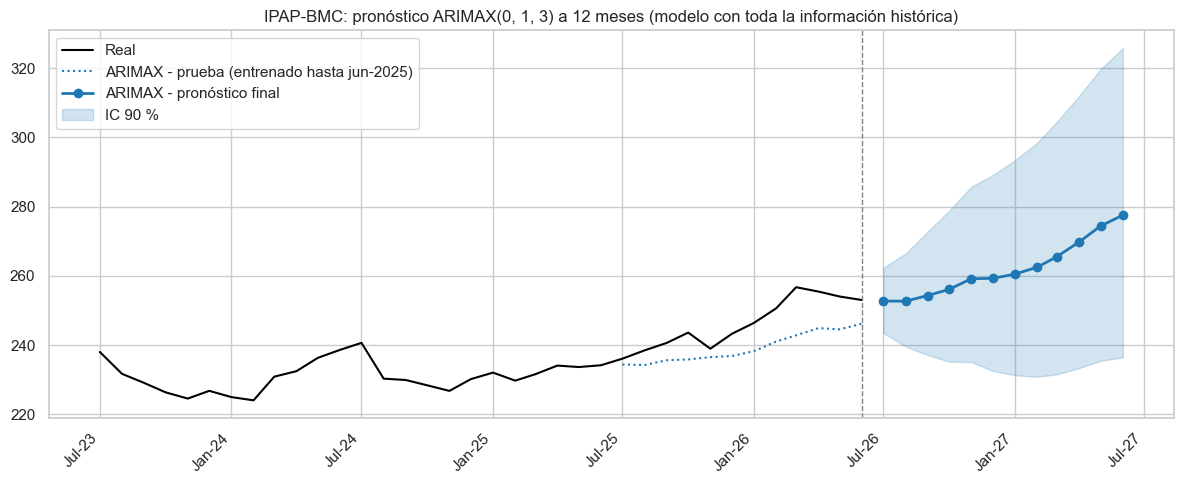

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos.index[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test.index, pred_arimax, color="#1f78b4", ls=":", lw=1.5, label="ARIMAX - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_arimax["Fecha"], pronostico_arimax["Pronóstico"], color="#1f78b4", marker="o", lw=2, label="ARIMAX - pronóstico final")
ax.fill_between(pronostico_arimax["Fecha"], pronostico_arimax["IC 90 % inf"], pronostico_arimax["IC 90 % sup"],
                color="#1f78b4", alpha=0.2, label="IC 90 %")
ax.axvline(datos.index[-1], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: pronóstico ARIMAX{ORDEN} a 12 meses (modelo con toda la información histórica)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2) Modelo ETS

ETS (*Error, Trend, Seasonal*) es la familia de modelos de suavizamiento exponencial en forma de espacio de estados. Cada modelo se define por tres componentes:

* **Error:** aditivo (A) o multiplicativo (M).
* **Tendencia:** ninguna (N), aditiva (A), aditiva amortiguada (Ad), multiplicativa (M) o multiplicativa amortiguada (Md).
* **Estacionalidad:** ninguna (N), aditiva (A) o multiplicativa (M), con periodo 12.

Por ejemplo, ETS(M,Ad,M) tiene error multiplicativo, tendencia amortiguada y estacionalidad multiplicativa. La tendencia amortiguada hace que la pendiente se aplane con el horizonte, lo que evita que el pronóstico se dispare a 12 meses.

En lugar de fijar una especificación de antemano, se evalúan todas las combinaciones con una **validación walk-forward sobre el entrenamiento** y se elige la de menor MAPE. También se evalúa el promedio de las dos mejores, porque combinar pronósticos suele reducir el error. El modelo entrega además un intervalo de predicción del 90 %, comparable con el de Prophet.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia evaluación. Las etapas 1 y 2 de la metodología hold-out corresponden a los pasos 3 a 9, y la etapa 3 a los pasos 10 y 11. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos
3. Partición en entrenamiento y prueba
4. Grilla de especificaciones ETS
5. Validación walk-forward sobre el entrenamiento
6. Selección del modelo
7. Entrenamiento y predicción en prueba
8. Gráfica de la predicción
9. Métricas de error en prueba (RMSE y MAPE)
10. Pronóstico final con toda la información histórica
11. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (`statsmodels` para los modelos ETS) y se fijan los parámetros que **no** se optimizan:

* `HORIZONTE`: meses a pronosticar y que se reservan para prueba (12).
* `N_ORIGENES` y `PASO_ORIGENES`: número de orígenes de la validación walk-forward y meses entre uno y otro. Con 13 orígenes semestrales se cubren seis años de la historia, incluidos periodos estables, el alza de 2021-2022 y la corrección posterior.
* `INTERVALO`: ancho del intervalo de predicción (0.9 = 90 %, igual que en Prophet).
* `SEED`: semilla de la simulación con la que se calculan los intervalos de los modelos multiplicativos.

In [ ]:
# Librerías a utilizar
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
SEED = 13              # reproducibilidad de la simulación de intervalos
HORIZONTE = 12         # meses a pronosticar (mismo test que en Prophet)
N_ORIGENES = 13        # orígenes de la validación walk-forward
PASO_ORIGENES = 6      # meses entre orígenes consecutivos
INTERVALO = 0.9        # intervalo de predicción del 90 %

#### 2) Cargar la base de datos

ETS es un modelo univariado, así que solo se usa el IPAP. Se renombran las columnas como en Prophet (`ds` para la fecha y `y` para el IPAP) y se conservan las fechas con IPAP observado.

In [ ]:
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")
datos = datos.dropna(subset=["y"])[["ds", "y"]].reset_index(drop=True)   # solo fechas con IPAP observado

print("Rango de fechas :", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("N° observaciones:", len(datos))
datos.tail()

#### 3) Partición en entrenamiento y prueba

La partición es temporal y sigue la metodología hold-out:

* **Prueba:** los últimos 12 meses. No se tocan hasta el paso 7.
* **Entrenamiento:** todo lo anterior. Sobre este conjunto se hace la validación walk-forward para elegir la especificación.

`statsmodels` necesita la serie con índice de fechas y frecuencia mensual, así que se arman `serie_train` (entrenamiento) y `serie_total` (toda la historia, para la etapa 3).

Los orígenes de la validación se calculan a partir del final del entrenamiento: el último origen está 12 meses antes, de modo que su pronóstico cae justo en los últimos 12 meses del entrenamiento. Así la validación nunca toca la prueba y las fechas se desplazan solas cuando se agrega un mes nuevo a la base.

In [ ]:
# Últimos 12 meses -> prueba | el resto -> entrenamiento
test = datos.iloc[-HORIZONTE:].copy()
train = datos.iloc[:-HORIZONTE].copy()

# Series mensuales indexadas por fecha (formato que exige statsmodels)
serie_train = train.set_index("ds")["y"].asfreq("MS")
serie_total = datos.set_index("ds")["y"].asfreq("MS")

# Orígenes de la validación walk-forward (todos dentro del entrenamiento)
ORIGENES_CV = pd.date_range(end=train["ds"].max() - pd.DateOffset(months=HORIZONTE),
                            periods=N_ORIGENES, freq=f"{PASO_ORIGENES}MS")

print("Entrenamiento:", len(train), "|", train["ds"].min().date(), "→", train["ds"].max().date())
print("Prueba       :", len(test),  "|", test["ds"].min().date(),  "→", test["ds"].max().date())
print("Orígenes CV  :", len(ORIGENES_CV), "|", ORIGENES_CV.min().date(), "→", ORIGENES_CV.max().date())

#### 4) Grilla de especificaciones ETS

Se combinan error {A, M}, tendencia {N, A, Ad, M, Md} y estacionalidad {N, A, M}. Además, los modelos con todos sus componentes aditivos se estiman también sobre el **logaritmo** del IPAP: en logaritmos un error aditivo equivale a un error relativo, que es justo lo que mide el MAPE.

Se descartan dos combinaciones que no tienen sentido: amortiguar una tendencia que no existe y aplicar logaritmo a un modelo que ya tiene componentes multiplicativos. Quedan 36 especificaciones.

Aunque la ACF no mostró estacionalidad anual clara, las especificaciones estacionales se dejan en la grilla: la validación decide si aportan o no.

In [ ]:
configs = []
for error, tendencia, amortiguada, estacional, log in itertools.product(
        ["add", "mul"], [None, "add", "mul"], [False, True], [None, "add", "mul"], [False, True]):
    if tendencia is None and amortiguada:                                      # amortiguar sin tendencia no aplica
        continue
    if log and (error == "mul" or tendencia == "mul" or estacional == "mul"):  # log solo con componentes aditivos
        continue

    # Nombre del modelo en notación ETS(error, tendencia, estacionalidad)
    letra_t = "N" if tendencia is None else ("A" if tendencia == "add" else "M") + ("d" if amortiguada else "")
    letra_s = "N" if estacional is None else ("A" if estacional == "add" else "M")
    nombre = f"ETS({error[0].upper()},{letra_t},{letra_s})" + (" log" if log else "")
    configs.append({"nombre": nombre, "error": error, "tendencia": tendencia,
                    "amortiguada": amortiguada, "estacional": estacional, "log": log})

print("N° de especificaciones:", len(configs))
pd.DataFrame(configs).head()

#### 5) Validación walk-forward sobre el entrenamiento

Para cada especificación y cada origen de `ORIGENES_CV`:

1. Se estima el modelo con los datos de entrenamiento hasta el origen.
2. Se pronostican los 12 meses siguientes.
3. Se calculan el RMSE y el MAPE frente a los valores reales, que siguen siendo del entrenamiento.

Las métricas de cada especificación son el promedio sobre los orígenes (`rmse_cv`, `mape_cv`), y `std_mape_cv` es su desviación. Los pronósticos se guardan en `pron_cv_ets` para evaluar después la combinación de modelos. Si una especificación no converge en algún origen, ese pronóstico queda como faltante.

La métrica a **minimizar** es el MAPE, que es la métrica del concurso. Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
start_time = time.time()

# Valores reales de cada ventana de validación (los 12 meses posteriores a cada origen)
reales_cv = [serie_train[o + pd.offsets.MonthBegin(1):].iloc[:HORIZONTE].values for o in ORIGENES_CV]

pron_cv_ets = {}   # nombre del modelo -> lista de pronósticos (uno por origen)
filas = []

for k, cfg in enumerate(configs, 1):
    preds, rmses, mapes = [], [], []
    for o, real in zip(ORIGENES_CV, reales_cv):
        y_fit = np.log(serie_train[:o]) if cfg["log"] else serie_train[:o]   # datos hasta el origen
        try:
            modelo = ETSModel(y_fit, error=cfg["error"], trend=cfg["tendencia"],
                              damped_trend=cfg["amortiguada"], seasonal=cfg["estacional"],
                              seasonal_periods=12 if cfg["estacional"] else None,
                              initialization_method="estimated")
            pred = modelo.fit(disp=False, maxiter=2000).forecast(HORIZONTE).values
            pred = np.exp(pred) if cfg["log"] else pred                        # regreso a la escala del IPAP
        except Exception:
            pred = np.full(HORIZONTE, np.nan)
        preds.append(pred)
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))
        mapes.append(np.mean(np.abs(real - pred) / np.abs(real)) * 100)

    pron_cv_ets[cfg["nombre"]] = preds
    filas.append({"modelo": cfg["nombre"], "rmse_cv": np.nanmean(rmses), "mape_cv": np.nanmean(mapes),
                  "std_mape_cv": np.nanstd(mapes)})
    print(f"ETS | walk-forward: {k}/{len(configs)} - MAPE CV = {np.nanmean(mapes):.3f}", end="\r")

# Resultados ordenados por MAPE (menor es mejor)
res_cv_ets = pd.DataFrame(filas).sort_values("mape_cv").reset_index(drop=True)

end_time = time.time()
execution_time = end_time - start_time
print(f"\nExecution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")
res_cv_ets.head(10).round(3)

ETS | walk-forward: 36/36 - MAPE CV = 5.678
Execution time: 0min 38s


,modelo,rmse_cv,mape_cv,std_mape_cv
0,"ETS(M,Ad,M)",13.077,5.431,3.900
1,"ETS(A,Ad,M)",13.200,5.544,4.031
2,"ETS(M,N,M)",12.943,5.589,4.646
3,"ETS(A,N,A) log",12.966,5.617,4.683
4,"ETS(M,N,A)",13.007,5.652,4.625
5,"ETS(M,Md,M)",13.748,5.678,4.379
6,"ETS(A,N,A)",13.093,5.725,4.721
7,"ETS(A,N,M)",13.247,5.755,4.723
8,"ETS(A,Md,M)",13.970,5.783,4.684
9,"ETS(A,Ad,A) log",13.912,5.785,4.425


#### 6) Selección del modelo

Se promedian los pronósticos de las **dos mejores especificaciones** en cada origen y se calcula el MAPE de esa combinación con la misma validación. Luego se elige, entre la mejor especificación individual y la combinación, la de **menor MAPE en validación**. Como referencia se incluye el baseline Naïve (repetir el último valor observado en cada origen).

La prueba no interviene en esta decisión: todo se calcula sobre el entrenamiento.

In [ ]:
top2_ets = res_cv_ets["modelo"].iloc[:2].tolist()
print("Dos mejores especificaciones:", top2_ets)

# RMSE y MAPE de la combinación y del Naïve en cada origen
rmses_comb, mapes_comb, rmses_naive, mapes_naive = [], [], [], []
for i, (o, real) in enumerate(zip(ORIGENES_CV, reales_cv)):
    pred_comb = (pron_cv_ets[top2_ets[0]][i] + pron_cv_ets[top2_ets[1]][i]) / 2
    pred_naive = np.full(HORIZONTE, serie_train[:o].iloc[-1])
    rmses_comb.append(np.sqrt(np.mean((real - pred_comb) ** 2)))
    mapes_comb.append(np.mean(np.abs(real - pred_comb) / np.abs(real)) * 100)
    rmses_naive.append(np.sqrt(np.mean((real - pred_naive) ** 2)))
    mapes_naive.append(np.mean(np.abs(real - pred_naive) / np.abs(real)) * 100)

resumen_cv_ets = pd.DataFrame({
    "RMSE CV": [res_cv_ets["rmse_cv"].iloc[0], np.mean(rmses_comb), np.mean(rmses_naive)],
    "MAPE CV (%)": [res_cv_ets["mape_cv"].iloc[0], np.mean(mapes_comb), np.mean(mapes_naive)]
}, index=[top2_ets[0], "Combinación " + " + ".join(top2_ets), "Naïve"])
display(resumen_cv_ets.round(3))

# Selección: menor MAPE en validación entre el mejor individual y la combinación
usar_combinacion_ets = np.mean(mapes_comb) < res_cv_ets["mape_cv"].iloc[0]
modelos_ets = top2_ets if usar_combinacion_ets else top2_ets[:1]
mape_cv_ets = np.mean(mapes_comb) if usar_combinacion_ets else res_cv_ets["mape_cv"].iloc[0]

print("Modelo seleccionado:", " + ".join(modelos_ets))
print("MAPE en validación walk-forward:", round(mape_cv_ets, 3))

#### 7) Entrenamiento y predicción en prueba

Se estiman las especificaciones seleccionadas **solo con el entrenamiento** y se pronostican los 12 meses de prueba, que el modelo no ha visto. Si se seleccionó la combinación, el pronóstico es el promedio de ambos modelos.

`get_prediction` devuelve, además del pronóstico (`mean`), los límites del intervalo del 90 % (`pi_lower`, `pi_upper`). En los modelos con componentes multiplicativos esos límites se obtienen por simulación, así que pueden variar en algunas décimas entre corridas. En los modelos en logaritmo se devuelven a la escala del IPAP con la exponencial.

In [ ]:
preds, infs, sups = [], [], []
for cfg in configs:
    if cfg["nombre"] in modelos_ets:
        y_fit = np.log(serie_train) if cfg["log"] else serie_train
        modelo = ETSModel(y_fit, error=cfg["error"], trend=cfg["tendencia"],
                          damped_trend=cfg["amortiguada"], seasonal=cfg["estacional"],
                          seasonal_periods=12 if cfg["estacional"] else None,
                          initialization_method="estimated")
        res = modelo.fit(disp=False, maxiter=2000)

        np.random.seed(SEED)
        pr = res.get_prediction(start=len(y_fit), end=len(y_fit) + HORIZONTE - 1,
                                simulate_repetitions=5000).summary_frame(alpha=1 - INTERVALO)
        if cfg["log"]:
            pr = np.exp(pr)                                     # regreso a la escala del IPAP
        preds.append(pr["mean"].values)
        infs.append(pr["pi_lower"].values)
        sups.append(pr["pi_upper"].values)
        print(cfg["nombre"], "| AIC:", round(res.aic, 1))

pred_ets = np.mean(preds, axis=0)   # promedio (si es un solo modelo, queda igual)

# Tabla real vs. predicho
res_ets = test[["ds", "y"]].copy()
res_ets["yhat"] = pred_ets
res_ets["yhat_lower"] = np.mean(infs, axis=0)
res_ets["yhat_upper"] = np.mean(sups, axis=0)

print("Prueba:")
display(res_ets.round(2))

#### 8) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba y su intervalo del 90 %. La zona sombreada indica el periodo de prueba.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_ets, color="#e7298a", marker="o", lw=2, label="ETS - prueba")
ax.fill_between(test["ds"], res_ets["yhat_lower"], res_ets["yhat_upper"], color="#e7298a", alpha=0.2, label="IC 90 %")

ax.axvspan(test["ds"].iloc[0], test["ds"].iloc[-1], color="grey", alpha=0.20)
ax.axvline(test["ds"].iloc[0], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: real vs. predicción ETS (prueba) — {' + '.join(modelos_ets)}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 9) Métricas de error en prueba (RMSE y MAPE)

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP (las mismas métricas de Prophet, LSTM y GRU). Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
y_real_test = test["y"].values
err_test = y_real_test - pred_ets

rmse_ets = np.sqrt(np.mean(err_test ** 2))
mape_ets = np.mean(np.abs(err_test) / np.abs(y_real_test)) * 100

metricas_ets = pd.DataFrame({"Prueba": [rmse_ets, mape_ets]}, index=["RMSE", "MAPE (%)"])

print("Modelo seleccionado (ETS):", " + ".join(modelos_ets))
metricas_ets.round(3)

#### 10) Pronóstico final con toda la información histórica

Esta es la etapa 3 de la metodología hold-out. Una vez medido el desempeño en prueba, las mismas especificaciones se reestiman con **toda la serie**, incluidos los 12 meses que antes se reservaron para prueba, y se pronostican los 12 meses siguientes al último dato observado.

* **Especificación:** es la seleccionada en el paso 6. No se vuelve a escoger, pues la prueba ya hace parte del entrenamiento; solo se reestiman los parámetros con más datos.
* **Intervalo:** se calcula igual que en el paso 7.

El resultado se guarda en `pronostico_ets` para compararlo con los demás modelos en la sección 5.

In [ ]:
preds, infs, sups = [], [], []
for cfg in configs:
    if cfg["nombre"] in modelos_ets:
        y_fit = np.log(serie_total) if cfg["log"] else serie_total
        modelo = ETSModel(y_fit, error=cfg["error"], trend=cfg["tendencia"],
                          damped_trend=cfg["amortiguada"], seasonal=cfg["estacional"],
                          seasonal_periods=12 if cfg["estacional"] else None,
                          initialization_method="estimated")
        res = modelo.fit(disp=False, maxiter=2000)

        np.random.seed(SEED)
        pr = res.get_prediction(start=len(y_fit), end=len(y_fit) + HORIZONTE - 1,
                                simulate_repetitions=5000).summary_frame(alpha=1 - INTERVALO)
        if cfg["log"]:
            pr = np.exp(pr)
        preds.append(pr["mean"].values)
        infs.append(pr["pi_lower"].values)
        sups.append(pr["pi_upper"].values)

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(datos["ds"].iloc[-1] + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

pronostico_ets = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": np.mean(preds, axis=0),
    "IC 90 % inf": np.mean(infs, axis=0),
    "IC 90 % sup": np.mean(sups, axis=0),
})

print("Entrenamiento:", len(datos), "|", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("Pronóstico   :", len(pronostico_ets), "|", pronostico_ets["Fecha"].min().date(), "→", pronostico_ets["Fecha"].max().date())
pronostico_ets.round(2)

#### 11) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada, paso 7), el pronóstico final y la banda del intervalo del 90 %. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_ets, color="#e7298a", ls=":", lw=1.5, label="ETS - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_ets["Fecha"], pronostico_ets["Pronóstico"], color="#e7298a", marker="o", lw=2, label="ETS - pronóstico final")
ax.fill_between(pronostico_ets["Fecha"], pronostico_ets["IC 90 % inf"], pronostico_ets["IC 90 % sup"],
                color="#e7298a", alpha=0.2, label="IC 90 %")
ax.axvline(datos["ds"].iloc[-1], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: pronóstico ETS a 12 meses (modelo con toda la información histórica) — {' + '.join(modelos_ets)}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3) Prophet

Prophet (desarrollado por Meta) es un modelo aditivo de series de tiempo que descompone la serie en una **tendencia** lineal por tramos, con puntos de cambio que se ajustan automáticamente, más componentes opcionales de **estacionalidad**, efectos de festivos y regresores externos:

$$y(t)=g(t)+s(t)+h(t)+\varepsilon_t$$

donde $g(t)$ es la tendencia, $s(t)$ la estacionalidad, $h(t)$ el efecto de festivos y $\varepsilon_t$ el error. Es robusto a datos faltantes y a cambios bruscos de nivel, y entrega intervalos de incertidumbre junto con el pronóstico.

En este caso se pronostican los **12 meses siguientes** del IPAP-BMC con un intervalo del 90 %. Según el análisis de la ACF no hay evidencia de estacionalidad anual, por lo que se desactiva ese componente y el modelo se concentra en la tendencia y sus puntos de cambio. La variable IMP rezagada 12 meses se probó como regresor, pero el modelo tiene mejor desempeño sin ella, usando únicamente la historia de la propia serie.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia evaluación. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos y rezagar el regresor IMP
3. Partición en entrenamiento y prueba
4. Especificación y entrenamiento del modelo
5. Predicción a 12 meses con intervalos del 90 %
6. Gráfica de la predicción
7. Métricas de error en prueba (RMSE y MAPE)
8. Validación cruzada nativa de Prophet (backtest)
9. Métricas del backtest frente al baseline Naïve
10. Gráfica del backtest
11. Pronóstico final con toda la información histórica
12. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (Prophet y sus herramientas de diagnóstico) y se fijan los parámetros del modelo y de la evaluación en un solo lugar:

* `HORIZONTE`: meses a pronosticar y que se reservan para prueba (12).
* `N_CHANGEPOINTS`: número de puntos de cambio candidatos de la tendencia.
* `CHANGEPOINT_RANGE`: proporción inicial de la serie en la que se ubican esos puntos (0.8 significa el primer 80 %, de modo que la tendencia de los últimos meses no se extrapola con un cambio de pendiente reciente).
* `CHANGEPOINT_PRIOR`: flexibilidad de la tendencia. Un valor menor la vuelve más rígida y uno mayor permite más cambios de pendiente (0.05 es el valor por defecto de Prophet).
* `INTERVALO`: ancho del intervalo de incertidumbre (0.9 = 90 %).
* `CV_INITIAL`, `CV_HORIZON` y `CV_PERIOD`: ventana inicial de entrenamiento, horizonte de pronóstico y separación entre puntos de corte de la validación cruzada nativa de Prophet (pasos 8 a 10).

In [ ]:
# Librerías a utilizar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot
from prophet.diagnostics import cross_validation, performance_metrics
import warnings
warnings.filterwarnings("ignore")

# Parámetros del modelo
HORIZONTE = 12             # meses a pronosticar (y a reservar para prueba)
N_CHANGEPOINTS = 25        # puntos de cambio candidatos de la tendencia
CHANGEPOINT_RANGE = 0.8    # los puntos de cambio se ubican en el primer 80 % de la serie
CHANGEPOINT_PRIOR = 0.05   # flexibilidad de la tendencia
INTERVALO = 0.9            # intervalo de incertidumbre del 90 %

# Parámetros de la validación cruzada nativa de Prophet
CV_INITIAL = "5220 days"   # ventana inicial de entrenamiento
CV_HORIZON = "365 days"    # horizonte de pronóstico de cada corte
CV_PERIOD = "180 days"     # separación entre puntos de corte

#### 2) Cargar la base de datos y rezagar el regresor IMP

Se cargan los datos desde la ubicación local y se renombran las columnas con los nombres que exige Prophet: `ds` (fecha) para el tiempo y `y` para la variable a pronosticar (el IPAP); IMP se conserva como regresor candidato. Se da formato de fecha mensual.

El regresor IMP se rezaga 12 meses: el valor de IMP en $t-12$ se asigna a la fecha $t$ (`IMP_l12`). Para ello se usa la serie completa de IMP, sin recortar, y luego se unen los datos con IPAP observado. Los primeros 12 meses quedan sin `IMP_l12` por falta de rezago, lo que no afecta al modelo sin regresor, que usa solo `ds` y `y`.

In [ ]:
# Serie completa de IMP, sin recortar
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")

# Regresor rezagado: el valor de IMP en (t - 12 meses) se asigna a la fecha t
imp_l12 = datos[["ds", "IMP"]].copy()
imp_l12["ds"] = imp_l12["ds"] + pd.DateOffset(months=12)
imp_l12 = imp_l12.rename(columns={"IMP": "IMP_l12"})   # ahora cubre 12 meses más allá de la serie

# Solo fechas con IPAP observado, más el regresor rezagado
datos = datos.dropna(subset=["y"])[["ds", "y"]].merge(imp_l12, on="ds", how="left")

print("Rango de fechas :", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("N° observaciones:", len(datos))
datos.tail()

#### 3) Partición en entrenamiento y prueba

La partición es temporal y reserva los **últimos 12 meses exclusivamente para medir el desempeño predictivo**: el modelo no los ve durante el entrenamiento. El resto de la serie es el conjunto de entrenamiento.

In [ ]:
# Últimos 12 meses -> prueba | el resto -> entrenamiento
test = datos.iloc[-HORIZONTE:].copy()
train = datos.iloc[:-HORIZONTE].copy()

print("Entrenamiento:", len(train), "|", train["ds"].min().date(), "→", train["ds"].max().date())
print("Prueba       :", len(test),  "|", test["ds"].min().date(),  "→", test["ds"].max().date())

# Ventana inicial de la validación cruzada = todo el entrenamiento (un solo punto de corte; se ajusta sola al agregar datos)
CV_INITIAL = f"{(train['ds'].max() - train['ds'].min()).days} days"
print("CV_INITIAL:", CV_INITIAL)


#### 4) Especificación y entrenamiento del modelo

Se especifica Prophet con los parámetros definidos en el paso 1 y se entrena **solo con el conjunto de entrenamiento**:

* `yearly_seasonality=False`: se desactiva la estacionalidad anual porque la ACF no muestra evidencia de ella. Las estacionalidades semanal y diaria no aplican con datos mensuales.
* `n_changepoints`, `changepoint_range` y `changepoint_prior_scale`: controlan cuántos cambios de pendiente puede tener la tendencia, dónde y qué tan flexibles son.
* `interval_width`: ancho del intervalo de incertidumbre.
* El regresor IMP rezagado queda comentado: al comparar el modelo con y sin él, el desempeño fue mejor sin regresor, trabajando solo con la historia de la propia serie.

**Nota:** estos parámetros se escogieron por tanteo, según el desempeño predictivo medido con el MAPE de los últimos 12 meses. Como esos meses intervinieron en la elección, el error de prueba puede resultar algo optimista.

In [ ]:
modelo_prophet = Prophet(yearly_seasonality=False, n_changepoints=N_CHANGEPOINTS,
                         changepoint_range=CHANGEPOINT_RANGE,
                         changepoint_prior_scale=CHANGEPOINT_PRIOR,
                         interval_width=INTERVALO)
# modelo_prophet.add_regressor("IMP_l12")    # versión con regresor (peor desempeño)
modelo_prophet.fit(train)

#### 5) Predicción a 12 meses con intervalos del 90 %

Con el modelo ya entrenado (sin volver a ajustarlo) se pronostican los 12 meses siguientes al entrenamiento, que coinciden con el periodo de prueba. `make_future_dataframe` extiende las fechas del entrenamiento 12 meses hacia adelante (con frecuencia mensual, inicio de mes) y `predict` devuelve para cada fecha el pronóstico `yhat` y los límites del intervalo, `yhat_lower` y `yhat_upper`.

In [ ]:
future = modelo_prophet.make_future_dataframe(periods=HORIZONTE, freq="MS")
# future = future.merge(imp_l12, on="ds", how="left")    # solo si se usa el regresor

forecast = modelo_prophet.predict(future)
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(HORIZONTE).round(2)

#### 6) Gráfica de la predicción

Se grafica la tendencia estimada sobre las observaciones de entrenamiento, el pronóstico y la banda del intervalo del 90 %. Sobre ese gráfico se superponen en rojo los últimos 12 valores reales, para comparar visualmente lo predicho con lo que efectivamente ocurrió.

In [ ]:
fig = modelo_prophet.plot(forecast, include_legend=True)
ax = fig.gca()

ax.plot(test["ds"], test["y"], color="red", marker="o", linewidth=2, label="Últimos 12 reales")

ax.legend()
plt.show()

#### 7) Métricas de error en prueba (RMSE y MAPE)

Se cruzan los valores reales de prueba con las predicciones por fecha (`ds`) y se calculan el RMSE y el MAPE en la escala original del IPAP. Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

El MAPE es la métrica con la que se escogieron los parámetros del modelo y el RMSE permite compararlo con los modelos de machine learning (LSTM y GRU).

In [ ]:
# Tabla real vs. predicho en el periodo de prueba
res_prophet = test[["ds", "y"]].merge(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]], on="ds", how="left")
print("Prueba:")
display(res_prophet.round(2))

# Métricas
err_test = res_prophet["y"] - res_prophet["yhat"]
rmse_prophet = np.sqrt((err_test ** 2).mean())
mape_prophet = (np.abs(err_test) / np.abs(res_prophet["y"])).mean() * 100

metricas_prophet = pd.DataFrame({"Prueba": [rmse_prophet, mape_prophet]}, index=["RMSE", "MAPE (%)"])
metricas_prophet.round(3)

#### 8) Validación cruzada nativa de Prophet (backtest)

Aquí se mide el desempeño predictivo con las funciones nativas del paquete. Primero se entrena un modelo con la **serie completa** y luego `cross_validation` lo reentrena internamente con ventanas crecientes y pronostica el horizonte indicado desde cada punto de corte:

* `initial`: tamaño de la ventana inicial de entrenamiento.
* `horizon`: horizonte de cada pronóstico (365 días, es decir, 12 meses).
* `period`: separación entre puntos de corte.

Con estos parámetros solo queda un punto de corte, de modo que el backtest se hace sobre los mismos 12 meses de prueba y debería reproducir las métricas del paso 7. Se verifica con el número de puntos de corte.

Antes de la validación se grafica la tendencia del modelo entrenado con toda la serie junto con sus puntos de cambio significativos (los de cambio de pendiente apreciable, con magnitud de al menos 0.01), junto con el pronóstico de los 12 meses siguientes.

In [ ]:
# Modelo con la serie completa (mismos parámetros del paso 4)
modelo_prophet_total = Prophet(yearly_seasonality=False, n_changepoints=N_CHANGEPOINTS,
                               changepoint_range=CHANGEPOINT_RANGE,
                               changepoint_prior_scale=CHANGEPOINT_PRIOR,
                               interval_width=INTERVALO)
# modelo_prophet_total.add_regressor("IMP_l12")
modelo_prophet_total.fit(datos)

In [ ]:
# Pronóstico del modelo completo y puntos de cambio de la tendencia
future_total = modelo_prophet_total.make_future_dataframe(periods=HORIZONTE, freq="MS")
forecast_total = modelo_prophet_total.predict(future_total)

n_cambios = int((np.abs(modelo_prophet_total.params["delta"].mean(axis=0)) >= 0.01).sum())

fig = modelo_prophet_total.plot(forecast_total)
add_changepoints_to_plot(fig.gca(), modelo_prophet_total, forecast_total)
plt.title(f"Prophet con la serie completa: {n_cambios} puntos de cambio significativos")
plt.show()

In [ ]:
# Validación cruzada: reentrena y pronostica desde cada punto de corte
df_cv = cross_validation(modelo_prophet_total, initial=CV_INITIAL, horizon=CV_HORIZON, period=CV_PERIOD)

print("Puntos de corte:", df_cv["cutoff"].nunique(), "| Fecha de corte:", df_cv["cutoff"].iloc[0].date())
df_cv.round(2)

#### 9) Métricas del backtest frente al baseline Naïve

Se calculan las métricas del backtest y se comparan con un **baseline Naïve**: repetir durante todo el horizonte el último valor observado antes del punto de corte. Prophet aporta valor solo si supera a ese baseline.

* **RMSE** y **MAPE (%)**, calculados sobre todos los pronósticos del backtest.
* **Cobertura:** porcentaje de valores reales que caen dentro del intervalo del 90 % de Prophet. Una cobertura cercana al 90 % indica que el intervalo está bien calibrado.

Se muestra además la tabla nativa de `performance_metrics`, que reporta el error por horizonte de pronóstico.

In [ ]:
# Métricas nativas de Prophet por horizonte
df_p = performance_metrics(df_cv, metrics=["rmse", "mape"])
display(df_p)

# Predicción Naïve: último valor observado antes o en la fecha de corte
cutoff = df_cv["cutoff"].iloc[0]
ultimo_valor_real = datos.loc[datos["ds"] <= cutoff, "y"].iloc[-1]
y_naive = np.full(len(df_cv), ultimo_valor_real)

# Métricas del backtest para Prophet
rmse_bt = np.sqrt(((df_cv["y"] - df_cv["yhat"]) ** 2).mean())
mape_bt = (np.abs(df_cv["y"] - df_cv["yhat"]) / df_cv["y"]).mean() * 100
cobertura_bt = ((df_cv["y"] >= df_cv["yhat_lower"]) & (df_cv["y"] <= df_cv["yhat_upper"])).mean() * 100

# Métricas del backtest para Naïve
rmse_naive_bt = np.sqrt(((df_cv["y"] - y_naive) ** 2).mean())
mape_naive_bt = (np.abs(df_cv["y"] - y_naive) / df_cv["y"]).mean() * 100

comparacion_bt = pd.DataFrame({
    "RMSE": [rmse_bt, rmse_naive_bt],
    "MAPE (%)": [mape_bt, mape_naive_bt],
    "Cobertura IC 90 % (%)": [cobertura_bt, np.nan]
}, index=["Prophet", "Naïve"])
comparacion_bt.round(2)

#### 10) Gráfica del backtest

Se muestran dos paneles:

* **Izquierda:** la serie completa real junto con las predicciones de Prophet (con su intervalo del 90 %) y del baseline Naïve. La línea vertical marca el punto de corte.
* **Derecha:** un acercamiento al periodo de validación, con el MAPE de cada método en el título.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

# Panel izquierdo: serie completa real vs. predicciones
ax = axes[0]
ax.plot(datos["ds"], datos["y"], color="black", lw=1.5, label="Real")
ax.plot(df_cv["ds"], df_cv["yhat"], color="#d95f02", lw=2, label="Prophet")
ax.plot(df_cv["ds"], y_naive, color="#7570b3", lw=1.5, ls="--", label="Naïve")
ax.fill_between(df_cv["ds"], df_cv["yhat_lower"], df_cv["yhat_upper"],
                color="#d95f02", alpha=0.2, label="IC 90 % Prophet")
ax.axvline(cutoff, color="grey", ls="--", lw=1)
ax.set_title("IPAP-BMC: real vs. predicciones")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()

# Panel derecho: acercamiento al periodo de validación
ax = axes[1]
ax.plot(df_cv["ds"], df_cv["y"], color="black", marker="o", label="Real")
ax.plot(df_cv["ds"], df_cv["yhat"], color="#d95f02", marker="o", label="Prophet")
ax.plot(df_cv["ds"], y_naive, color="#7570b3", ls="--", marker="s", label="Naïve")
ax.fill_between(df_cv["ds"], df_cv["yhat_lower"], df_cv["yhat_upper"], color="#d95f02", alpha=0.2)
ax.set_title(f"Validación {df_cv['ds'].min():%b-%y} a {df_cv['ds'].max():%b-%y}\n"
             f"Prophet (MAPE {mape_bt:.1f} %) vs Naïve (MAPE {mape_naive_bt:.1f} %)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()

plt.tight_layout()
plt.show()

#### 11) Pronóstico final con toda la información histórica

Esta es la etapa 3 de la metodología hold-out. Una vez medido el desempeño en prueba (pasos 7 y 9), se usa el modelo `modelo_prophet_total` del paso 8, que ya fue **reentrenado con toda la serie**, incluidos los 12 meses que antes se reservaron para prueba.

* **Parámetros:** son los mismos del paso 4. No se vuelven a escoger, pues la prueba ya hace parte del entrenamiento.
* **Horizonte:** `make_future_dataframe` extiende las fechas 12 meses después del último dato observado, y `predict` devuelve el pronóstico `yhat` con su intervalo del 90 %.
* **Interpretación:** como ya no quedan datos fuera de muestra, no se puede medir el error de este pronóstico. Su desempeño esperado se aproxima con el MAPE en prueba del paso 7.

El resultado se guarda en `pronostico_prophet` para compararlo con los demás modelos en la sección 5.

In [ ]:
# Modelo entrenado con la serie completa (paso 8): pronóstico de los 12 meses siguientes al último dato
future_total = modelo_prophet_total.make_future_dataframe(periods=HORIZONTE, freq="MS")
forecast_total = modelo_prophet_total.predict(future_total)

pronostico_prophet = (forecast_total[["ds", "yhat", "yhat_lower", "yhat_upper"]]
                      .tail(HORIZONTE).reset_index(drop=True)
                      .rename(columns={"ds": "Fecha", "yhat": "Pronóstico",
                                       "yhat_lower": "IC 90 % inf", "yhat_upper": "IC 90 % sup"}))

print("Entrenamiento:", len(datos), "|", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("Pronóstico   :", len(pronostico_prophet), "|", pronostico_prophet["Fecha"].min().date(), "→", pronostico_prophet["Fecha"].max().date())
pronostico_prophet.round(2)

#### 12) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, el pronóstico de los 12 meses siguientes y la banda del intervalo del 90 %. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(pronostico_prophet["Fecha"], pronostico_prophet["Pronóstico"], color="#d95f02", marker="o", lw=2, label="Prophet - pronóstico")
ax.fill_between(pronostico_prophet["Fecha"], pronostico_prophet["IC 90 % inf"], pronostico_prophet["IC 90 % sup"],
                color="#d95f02", alpha=0.2, label="IC 90 %")
ax.axvline(datos["ds"].iloc[-1], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: pronóstico Prophet a 12 meses (modelo con toda la información histórica)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

## 4) Modelos de Machine Learning

### 4.1) Elastic Net

Elastic Net es una regresión lineal con penalización. Combina la de Ridge (L2), que encoge los coeficientes, y la de Lasso (L1), que puede dejarlos exactamente en cero y así selecciona variables:

$$\min_{\beta}\ \frac{1}{2n}\sum_{t}(y_t - x_t'\beta)^2 + \alpha\left[\rho\,\lVert\beta\rVert_1 + \frac{1-\rho}{2}\lVert\beta\rVert_2^2\right]$$

donde $\alpha$ controla la intensidad de la penalización y $\rho$ (`l1_ratio`) la mezcla entre L1 y L2. Ambos se eligen por validación cruzada.

**Estrategia directa multi-horizonte.** Elastic Net no es un modelo de series de tiempo, así que se estima **un modelo distinto para cada horizonte** $h = 1, \dots, 12$:

$$\log y_{t+h} - \log y_t = x_t'\beta_h + \varepsilon_{t+h}$$

La variable objetivo es la variación logarítmica entre $t$ y $t+h$, y las variables $x_t$ solo usan información disponible en $t$. Esto tiene tres ventajas: no acumula error de un mes al siguiente (no es recursivo), no exige pronosticar el IMP, y como el error en logaritmos es un error relativo, el modelo se alinea con el MAPE. El nivel se recupera como $\hat y_{t+h} = y_t \exp(x_t'\hat\beta_h)$.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia evaluación. Las etapas 1 y 2 de la metodología hold-out corresponden a los pasos 4 a 9, y la etapa 3 a los pasos 10 y 11. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos
3. Variables explicativas
4. Partición en entrenamiento y prueba
5. Validación walk-forward sobre el entrenamiento (elección de variables)
6. Entrenamiento y predicción en prueba
7. Variables seleccionadas por el modelo
8. Gráfica de la predicción
9. Métricas de error en prueba (RMSE y MAPE)
10. Pronóstico final con toda la información histórica
11. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (scikit-learn para el modelo, el escalado y la validación cruzada) y se fijan los parámetros que **no** se optimizan:

* `HORIZONTE`: meses a pronosticar (12).
* `N_ORIGENES` y `PASO_ORIGENES`: los mismos de la validación walk-forward de ETS (13 orígenes semestrales).
* `INTERVALO`: cobertura de la banda empírica del pronóstico (0.9 = 90 %).
* `L1_RATIOS` y `N_ALPHAS`: valores de $\rho$ y número de valores de $\alpha$ que prueba `ElasticNetCV`.

In [ ]:
# Librerías a utilizar
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
HORIZONTE = 12                          # meses a pronosticar (mismo test que en Prophet)
N_ORIGENES = 13                         # orígenes de la validación walk-forward
PASO_ORIGENES = 6                       # meses entre orígenes consecutivos
INTERVALO = 0.9                         # cobertura de la banda empírica
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]   # mezcla L1/L2 (1 = Lasso)
N_ALPHAS = 50                           # valores de alpha a probar

#### 2) Cargar la base de datos

Se carga la base completa (IPAP + IMP) con los nombres de columnas de Prophet. El IMP tiene datos desde enero de 2010, un año antes que el IPAP, así que se conservan todas las filas para poder calcular sus variaciones desde el inicio del IPAP.

Para construir las variables se usa `base`, la misma información indexada por fecha con frecuencia mensual, y se trabaja con el logaritmo de ambas series.

In [ ]:
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")

base = datos.set_index("ds").asfreq("MS")     # serie mensual indexada por fecha (incluye 2010, solo IMP)
log_y = np.log(base["y"])                     # logaritmo del IPAP
log_imp = np.log(base["IMP"])                 # logaritmo del IMP
ultima_fecha = base["y"].dropna().index.max()

print("IPAP:", base["y"].dropna().index.min().date(), "→", ultima_fecha.date())
print("IMP :", base["IMP"].index.min().date(), "→", base["IMP"].index.max().date())

#### 3) Variables explicativas

Todas las variables en $t$ usan solo datos hasta $t$:

* `dIPAP_rez1` a `dIPAP_rez12`: variación mensual del log-IPAP y sus 11 rezagos.
* `gIPAP_3m`, `gIPAP_6m`, `gIPAP_12m`: variación acumulada a 3, 6 y 12 meses.
* `brecha_IPAP_ma12`: distancia del log-IPAP a su media móvil de 12 meses (captura reversión a la media).
* Variables análogas para el IMP: `dIMP_rez1` a `dIMP_rez6`, `gIMP_1m` a `gIMP_12m` y `brecha_IMP_ma12`.
* `mes_2` a `mes_12`: dummies del mes. Como cada horizonte tiene su propio modelo, el mes de origen determina el mes de destino, así que capturan la estacionalidad.

Con unas 70 a 160 observaciones de entrenamiento, el número de variables pesa. Por eso se comparan **cuatro especificaciones**: completa o compacta, con o sin IMP. Las variaciones del IMP en $t$ ya son conocidas en el origen del pronóstico, así que no hace falta rezagarlo 12 meses como en Prophet.

Los objetivos se guardan en `objetivos`: la columna `h` es $\log y_{t+h} - \log y_t$.

In [ ]:
X_todas = pd.DataFrame(index=base.index)

# Variables del IPAP
for k in range(1, 13):
    X_todas[f"dIPAP_rez{k}"] = log_y.diff().shift(k - 1)       # variación mensual y sus rezagos
for k in [3, 6, 12]:
    X_todas[f"gIPAP_{k}m"] = log_y.diff(k)                     # variación acumulada a k meses
X_todas["brecha_IPAP_ma12"] = log_y - log_y.rolling(12).mean()

# Variables del IMP
for k in range(1, 7):
    X_todas[f"dIMP_rez{k}"] = log_imp.diff().shift(k - 1)
for k in [1, 3, 6, 12]:
    X_todas[f"gIMP_{k}m"] = log_imp.diff(k)
X_todas["brecha_IMP_ma12"] = log_imp - log_imp.rolling(12).mean()

# Dummies de mes (enero es la categoría base)
for m in range(2, 13):
    X_todas[f"mes_{m}"] = (base.index.month == m).astype(float)

# Objetivos: variación logarítmica entre t y t+h
objetivos = pd.DataFrame({h: log_y.shift(-h) - log_y for h in range(1, HORIZONTE + 1)})

# Cuatro especificaciones (listas de columnas)
meses = [f"mes_{m}" for m in range(2, 13)]
ipap_completo = [f"dIPAP_rez{k}" for k in range(1, 13)] + ["gIPAP_3m", "gIPAP_6m", "gIPAP_12m", "brecha_IPAP_ma12"]
ipap_compacto = ["dIPAP_rez1", "gIPAP_3m", "gIPAP_6m", "gIPAP_12m", "brecha_IPAP_ma12"]   # dIPAP_rez1 = variación a 1 mes
imp_completo = [f"dIMP_rez{k}" for k in range(1, 7)] + ["gIMP_3m", "gIMP_6m", "gIMP_12m", "brecha_IMP_ma12"]
imp_compacto = ["gIMP_1m", "gIMP_3m", "gIMP_6m", "gIMP_12m"]

especificaciones_en = {
    "completo sin IMP": ipap_completo + meses,
    "completo con IMP": ipap_completo + imp_completo + meses,
    "compacto sin IMP": ipap_compacto + meses,
    "compacto con IMP": ipap_compacto + imp_compacto + meses,
}
for nombre, cols in especificaciones_en.items():
    print(f"{nombre}: {len(cols)} variables")

#### 4) Partición en entrenamiento y prueba

En la estrategia directa, la partición se define con el **origen del pronóstico**:

* **Prueba:** se pronostica desde el último mes del entrenamiento (`origen_test`, junio de 2025) hacia los 12 meses de prueba, los mismos de los demás modelos.
* **Entrenamiento:** para el horizonte $h$, solo entran las fechas $t \le$ `origen_test` $- h$, porque son las únicas cuyo objetivo $y_{t+h}$ ya se conocía en el origen. Si se usaran fechas posteriores, el objetivo caería dentro de la prueba.

Los orígenes de la validación walk-forward se calculan igual que en ETS, a partir del final del entrenamiento.

In [ ]:
origen_test = ultima_fecha - pd.DateOffset(months=HORIZONTE)     # último mes del entrenamiento
fechas_test = pd.date_range(origen_test + pd.offsets.MonthBegin(1), periods=HORIZONTE, freq="MS")
test = datos[datos["ds"].isin(fechas_test)][["ds", "y"]].reset_index(drop=True)

# Orígenes de la validación walk-forward (todos dentro del entrenamiento)
ORIGENES_CV = pd.date_range(end=origen_test - pd.DateOffset(months=HORIZONTE),
                            periods=N_ORIGENES, freq=f"{PASO_ORIGENES}MS")

print("Origen del pronóstico de prueba:", origen_test.date())
print("Prueba    :", len(test), "|", test["ds"].min().date(), "→", test["ds"].max().date())
print("Orígenes CV:", len(ORIGENES_CV), "|", ORIGENES_CV.min().date(), "→", ORIGENES_CV.max().date())

#### 5) Validación walk-forward sobre el entrenamiento (elección de variables)

Para cada especificación, cada origen de `ORIGENES_CV` y cada horizonte $h$:

1. Se arman los datos de entrenamiento con las fechas $t \le$ origen $- h$.
2. `ElasticNetCV` elige $\alpha$ y $\rho$ con una validación cruzada interna (`TimeSeriesSplit`). El hueco (`gap`) de $h-1$ meses evita que los objetivos de entrenamiento y validación se traslapen. Cuando hay pocos datos se usan menos pliegues.
3. Las variables se estandarizan (`StandardScaler`) para que la penalización las trate por igual.
4. Se pronostica $y_{\text{origen}+h}$.

Con los 12 horizontes se arma el pronóstico de cada origen y se calculan el RMSE y el MAPE. Se elige la especificación con **menor MAPE promedio**.

Además se guardan los **errores relativos** de cada origen y horizonte ($y/\hat y - 1$) en `errores_rel_en`. Con ellos se construye en el paso 6 una banda empírica del 90 % para el pronóstico, porque Elastic Net no entrega intervalos de predicción por sí solo.

Toma unos 2 minutos.

In [ ]:
start_time = time.time()

filas = []
errores_rel_en = {}   # especificación -> errores relativos (orígenes x horizontes)
for nombre, cols in especificaciones_en.items():
    rmses, mapes, rel = [], [], []
    for o in ORIGENES_CV:
        pred = []
        for h in range(1, HORIZONTE + 1):
            # Datos de entrenamiento: objetivos ya conocidos en el origen
            d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
            d = d.loc[:o - pd.DateOffset(months=h)].dropna()

            n_splits = max(2, min(5, (len(d) - (h - 1) - 24) // 6))
            modelo = make_pipeline(StandardScaler(),
                                   ElasticNetCV(l1_ratio=L1_RATIOS, n_alphas=N_ALPHAS, max_iter=20000,
                                                cv=TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)))
            modelo.fit(d[cols], d["obj"])
            pred.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))   # nivel del IPAP

        real = base["y"][o + pd.offsets.MonthBegin(1):].iloc[:HORIZONTE].values
        pred = np.array(pred)
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))
        mapes.append(np.mean(np.abs(real - pred) / np.abs(real)) * 100)
        rel.append(real / pred - 1)

    errores_rel_en[nombre] = np.array(rel)
    filas.append({"especificación": nombre, "rmse_cv": np.mean(rmses), "mape_cv": np.mean(mapes),
                  "std_mape_cv": np.std(mapes)})
    print(f"Elastic Net | {nombre}: MAPE CV = {np.mean(mapes):.3f}")

# Resultados ordenados por MAPE (menor es mejor)
res_cv_en = pd.DataFrame(filas).sort_values("mape_cv").reset_index(drop=True)
espec_en = res_cv_en["especificación"].iloc[0]
cols_en = especificaciones_en[espec_en]
mape_cv_en = res_cv_en["mape_cv"].iloc[0]

end_time = time.time()
execution_time = end_time - start_time
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")
print("Especificación seleccionada:", espec_en)
res_cv_en.round(3)

Elastic Net | compacto sin IMP: MAPE CV = 5.918


Elastic Net | compacto con IMP: MAPE CV = 6.680
Execution time: 1min 48s
Especificación seleccionada: compacto sin IMP


,especificación,rmse_cv,mape_cv,std_mape_cv
0,compacto sin IMP,14.137,5.918,3.702
1,completo sin IMP,14.401,6.039,3.723
2,compacto con IMP,15.557,6.680,4.652
3,completo con IMP,16.032,6.861,5.006


#### 6) Entrenamiento y predicción en prueba

Con la especificación seleccionada se estiman los 12 modelos desde `origen_test`, **solo con datos de entrenamiento**, y se pronostican los 12 meses de prueba. Se guardan los modelos de cada horizonte en `modelos_en` para revisar después qué variables usaron.

**Banda empírica del 90 %.** Para cada horizonte se toman los percentiles 5 y 95 de los errores relativos de la validación walk-forward de la especificación elegida, y se aplican al pronóstico: $\hat y\,(1 + q_{5})$ y $\hat y\,(1 + q_{95})$. Con 13 orígenes por horizonte, la banda es una aproximación; describe cuánto se equivocó el modelo en el pasado, no una distribución teórica.

Se verifica además que el procedimiento hold-out se cumpla: al menos 48 observaciones por horizonte y ningún objetivo de la prueba dentro del entrenamiento.

In [ ]:
# Percentiles de los errores relativos de la validación (banda empírica)
q_inf_en = np.percentile(errores_rel_en[espec_en], 100 * (1 - INTERVALO) / 2, axis=0)
q_sup_en = np.percentile(errores_rel_en[espec_en], 100 * (1 + INTERVALO) / 2, axis=0)

modelos_en = []
pred_en = []
n_obs, ultimo_obj = [], []   # para verificar el procedimiento hold-out
cols = cols_en
o = origen_test
for h in range(1, HORIZONTE + 1):
    d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
    d = d.loc[:o - pd.DateOffset(months=h)].dropna()
    n_obs.append(len(d))                                           # observaciones de entrenamiento
    ultimo_obj.append(d.index.max() + pd.DateOffset(months=h))     # fecha del último objetivo usado

    n_splits = max(2, min(5, (len(d) - (h - 1) - 24) // 6))
    modelo = make_pipeline(StandardScaler(),
                           ElasticNetCV(l1_ratio=L1_RATIOS, n_alphas=N_ALPHAS, max_iter=20000,
                                        cv=TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)))
    modelo.fit(d[cols], d["obj"])
    modelos_en.append(modelo)
    pred_en.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))

pred_en = np.array(pred_en)

# Verificaciones del procedimiento hold-out
print("Observaciones de entrenamiento por horizonte:", n_obs)
print("¿Todos los horizontes con al menos 48 observaciones?:", min(n_obs) >= 48)
print("¿Ningún valor de la prueba entra al entrenamiento?:", max(ultimo_obj) < test["ds"].min())

# Tabla real vs. predicho
res_en = test[["ds", "y"]].copy()
res_en["yhat"] = pred_en
res_en["yhat_lower"] = pred_en * (1 + q_inf_en)
res_en["yhat_upper"] = pred_en * (1 + q_sup_en)

print("Prueba:")
display(res_en.round(2))

#### 7) Variables seleccionadas por el modelo

Para cada horizonte se muestran el $\alpha$ y el $\rho$ elegidos y cuántas variables quedaron con coeficiente distinto de cero. Luego, los coeficientes de los horizontes 1, 6 y 12 (en escala estandarizada, así que su tamaño es comparable entre variables). Las variables con coeficiente cero en los tres horizontes no se muestran.

In [ ]:
hiper_en = pd.DataFrame({
    f"h={h}": [modelos_en[h - 1][-1].alpha_, modelos_en[h - 1][-1].l1_ratio_, int((modelos_en[h - 1][-1].coef_ != 0).sum())]
    for h in range(1, HORIZONTE + 1)
}, index=["alpha", "l1_ratio", "variables activas"])
display(hiper_en.round(4))

coefs_en = pd.DataFrame({f"h={h}": modelos_en[h - 1][-1].coef_ for h in [1, 6, 12]}, index=cols_en)
coefs_en[(coefs_en != 0).any(axis=1)].round(4)

#### 8) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba y su banda empírica del 90 %. La zona sombreada indica el periodo de prueba.

In [ ]:
serie_real = datos.dropna(subset=["y"])

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(serie_real["ds"].iloc[-36:], serie_real["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_en, color="#e6ab02", marker="o", lw=2, label="Elastic Net - prueba")
ax.fill_between(test["ds"], res_en["yhat_lower"], res_en["yhat_upper"], color="#e6ab02", alpha=0.2, label="Banda empírica 90 %")

ax.axvspan(test["ds"].iloc[0], test["ds"].iloc[-1], color="grey", alpha=0.20)
ax.axvline(test["ds"].iloc[0], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: real vs. predicción Elastic Net (prueba) — {espec_en}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 9) Métricas de error en prueba (RMSE y MAPE)

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP. Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
y_real_test = test["y"].values
err_test = y_real_test - pred_en

rmse_en = np.sqrt(np.mean(err_test ** 2))
mape_en = np.mean(np.abs(err_test) / np.abs(y_real_test)) * 100

metricas_en = pd.DataFrame({"Prueba": [rmse_en, mape_en]}, index=["RMSE", "MAPE (%)"])

print("Especificación seleccionada (Elastic Net):", espec_en)
metricas_en.round(3)

#### 10) Pronóstico final con toda la información histórica

Esta es la etapa 3 de la metodología hold-out. Se repite el paso 6 tomando como origen el último dato observado (junio de 2026). Así cada horizonte se entrena con todos los objetivos conocidos hasta esa fecha, **incluidos los 12 meses de prueba**.

* **Especificación:** son las seleccionadas antes. No se vuelven a escoger, pues la prueba ya hace parte del entrenamiento; $\alpha$ y $\rho$ se recalculan con la validación interna, igual que en todo el procedimiento.
* **Banda:** la misma banda empírica del 90 % del paso 6.

El resultado se guarda en `pronostico_en` para compararlo con los demás modelos en la sección 5.

In [ ]:
pred_fut = []
n_obs, ultimo_obj = [], []
cols = cols_en
o = ultima_fecha
for h in range(1, HORIZONTE + 1):
    d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
    d = d.loc[:o - pd.DateOffset(months=h)].dropna()
    n_obs.append(len(d))
    ultimo_obj.append(d.index.max() + pd.DateOffset(months=h))

    n_splits = max(2, min(5, (len(d) - (h - 1) - 24) // 6))
    modelo = make_pipeline(StandardScaler(),
                           ElasticNetCV(l1_ratio=L1_RATIOS, n_alphas=N_ALPHAS, max_iter=20000,
                                        cv=TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)))
    modelo.fit(d[cols], d["obj"])
    pred_fut.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))

pred_fut = np.array(pred_fut)

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(ultima_fecha + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

pronostico_en = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": pred_fut,
    "IC 90 % inf": pred_fut * (1 + q_inf_en),
    "IC 90 % sup": pred_fut * (1 + q_sup_en),
})

print("Observaciones de entrenamiento por horizonte:", n_obs)
print("Último objetivo usado:", max(ultimo_obj).date(), "(incluye los 12 meses de prueba)")
print("Pronóstico:", len(pronostico_en), "|", pronostico_en["Fecha"].min().date(), "→", pronostico_en["Fecha"].max().date())
pronostico_en.round(2)

#### 11) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada), el pronóstico final y su banda empírica del 90 %. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(serie_real["ds"].iloc[-36:], serie_real["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_en, color="#e6ab02", ls=":", lw=1.5, label="Elastic Net - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_en["Fecha"], pronostico_en["Pronóstico"], color="#e6ab02", marker="o", lw=2, label="Elastic Net - pronóstico final")
ax.fill_between(pronostico_en["Fecha"], pronostico_en["IC 90 % inf"], pronostico_en["IC 90 % sup"],
                color="#e6ab02", alpha=0.2, label="Banda empírica 90 %")
ax.axvline(ultima_fecha, color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: pronóstico Elastic Net a 12 meses (modelo con toda la información histórica) — {espec_en}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2) XGBoost

XGBoost (*eXtreme Gradient Boosting*) construye una secuencia de árboles de decisión pequeños, donde cada árbol corrige los errores que dejaron los anteriores. El pronóstico es la suma de todos los árboles, cada uno multiplicado por una tasa de aprendizaje.

**Por qué el objetivo es la variación y no el nivel.** Un árbol predice promedios de los datos que caen en cada hoja, así que nunca pronostica un valor fuera del rango visto en entrenamiento. Si se entrenara sobre el nivel del IPAP, en una serie con tendencia el pronóstico quedaría pegado al máximo histórico. Por eso se usa la misma estrategia directa multi-horizonte de Elastic Net: un modelo por horizonte $h$ que pronostica $\log y_{t+h} - \log y_t$. Las variaciones sí caen dentro del rango histórico.

**Función de pérdida.** Se entrena con error absoluto (`reg:absoluteerror`). Sobre variaciones logarítmicas, $|\log y - \log \hat y| \approx |y - \hat y|/y$, de modo que minimizarlo equivale aproximadamente a minimizar el MAPE.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia evaluación. Las etapas 1 y 2 de la metodología hold-out corresponden a los pasos 4 a 10, y la etapa 3 a los pasos 11 y 12. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos
3. Variables explicativas
4. Partición en entrenamiento y prueba
5. Grilla de hiperparámetros
6. Validación walk-forward sobre el entrenamiento (elección de variables)
7. Entrenamiento y predicción en prueba
8. Importancia de las variables
9. Gráfica de la predicción
10. Métricas de error en prueba (RMSE y MAPE)
11. Pronóstico final con toda la información histórica
12. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

* `HORIZONTE`, `N_ORIGENES`, `PASO_ORIGENES` e `INTERVALO`: los mismos de ETS y Elastic Net.
* `SEED`: semilla para que el submuestreo de XGBoost sea reproducible.

In [ ]:
# Librerías a utilizar
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
SEED = 13              # reproducibilidad
HORIZONTE = 12         # meses a pronosticar (mismo test que en Prophet)
N_ORIGENES = 13        # orígenes de la validación walk-forward
PASO_ORIGENES = 6      # meses entre orígenes consecutivos
INTERVALO = 0.9        # cobertura de la banda empírica

#### 2) Cargar la base de datos

Igual que en Elastic Net: base completa (el IMP desde 2010), `base` indexada por fecha y logaritmos de ambas series.

In [ ]:
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")

base = datos.set_index("ds").asfreq("MS")     # serie mensual indexada por fecha (incluye 2010, solo IMP)
log_y = np.log(base["y"])                     # logaritmo del IPAP
log_imp = np.log(base["IMP"])                 # logaritmo del IMP
ultima_fecha = base["y"].dropna().index.max()

print("IPAP:", base["y"].dropna().index.min().date(), "→", ultima_fecha.date())
print("IMP :", base["IMP"].index.min().date(), "→", base["IMP"].index.max().date())

#### 3) Variables explicativas

Son las mismas variables y las mismas cuatro especificaciones de Elastic Net, con una diferencia: el mes entra como **una sola variable numérica** (1 a 12) en lugar de 11 dummies, porque los árboles pueden partirla en los cortes que necesiten.

In [ ]:
X_todas = pd.DataFrame(index=base.index)

# Variables del IPAP
for k in range(1, 13):
    X_todas[f"dIPAP_rez{k}"] = log_y.diff().shift(k - 1)       # variación mensual y sus rezagos
for k in [3, 6, 12]:
    X_todas[f"gIPAP_{k}m"] = log_y.diff(k)                     # variación acumulada a k meses
X_todas["brecha_IPAP_ma12"] = log_y - log_y.rolling(12).mean()

# Variables del IMP
for k in range(1, 7):
    X_todas[f"dIMP_rez{k}"] = log_imp.diff().shift(k - 1)
for k in [1, 3, 6, 12]:
    X_todas[f"gIMP_{k}m"] = log_imp.diff(k)
X_todas["brecha_IMP_ma12"] = log_imp - log_imp.rolling(12).mean()

# Mes como variable numérica
X_todas["mes"] = base.index.month.astype(float)

# Objetivos: variación logarítmica entre t y t+h
objetivos = pd.DataFrame({h: log_y.shift(-h) - log_y for h in range(1, HORIZONTE + 1)})

# Cuatro especificaciones (listas de columnas)
meses = ["mes"]
ipap_completo = [f"dIPAP_rez{k}" for k in range(1, 13)] + ["gIPAP_3m", "gIPAP_6m", "gIPAP_12m", "brecha_IPAP_ma12"]
ipap_compacto = ["dIPAP_rez1", "gIPAP_3m", "gIPAP_6m", "gIPAP_12m", "brecha_IPAP_ma12"]   # dIPAP_rez1 = variación a 1 mes
imp_completo = [f"dIMP_rez{k}" for k in range(1, 7)] + ["gIMP_3m", "gIMP_6m", "gIMP_12m", "brecha_IMP_ma12"]
imp_compacto = ["gIMP_1m", "gIMP_3m", "gIMP_6m", "gIMP_12m"]

especificaciones_xgb = {
    "completo sin IMP": ipap_completo + meses,
    "completo con IMP": ipap_completo + imp_completo + meses,
    "compacto sin IMP": ipap_compacto + meses,
    "compacto con IMP": ipap_compacto + imp_compacto + meses,
}
for nombre, cols in especificaciones_xgb.items():
    print(f"{nombre}: {len(cols)} variables")

#### 4) Partición en entrenamiento y prueba

La misma de Elastic Net: se pronostica desde `origen_test` (junio de 2025) hacia los 12 meses de prueba, y para el horizonte $h$ solo entran al entrenamiento las fechas $t \le$ `origen_test` $- h$.

In [ ]:
origen_test = ultima_fecha - pd.DateOffset(months=HORIZONTE)     # último mes del entrenamiento
fechas_test = pd.date_range(origen_test + pd.offsets.MonthBegin(1), periods=HORIZONTE, freq="MS")
test = datos[datos["ds"].isin(fechas_test)][["ds", "y"]].reset_index(drop=True)

# Orígenes de la validación walk-forward (todos dentro del entrenamiento)
ORIGENES_CV = pd.date_range(end=origen_test - pd.DateOffset(months=HORIZONTE),
                            periods=N_ORIGENES, freq=f"{PASO_ORIGENES}MS")

print("Origen del pronóstico de prueba:", origen_test.date())
print("Prueba    :", len(test), "|", test["ds"].min().date(), "→", test["ds"].max().date())
print("Orígenes CV:", len(ORIGENES_CV), "|", ORIGENES_CV.min().date(), "→", ORIGENES_CV.max().date())

#### 5) Grilla de hiperparámetros

Con tan pocas observaciones, el riesgo principal de XGBoost es el sobreajuste. Por eso la grilla es deliberadamente conservadora:

* `max_depth`: profundidad de cada árbol (1 a 3). Con profundidad 1 cada árbol es un solo corte.
* `n_estimators`: número de árboles.
* Fijos: `learning_rate = 0.05` (aprendizaje lento), `min_child_weight = 5` (al menos 5 observaciones por hoja), y `subsample` y `colsample_bytree = 0.8` (cada árbol ve el 80 % de las filas y de las variables).

Para cada origen y horizonte, la combinación se elige con una validación cruzada interna (`TimeSeriesSplit` con hueco de $h-1$ meses) que minimiza el error absoluto medio sobre la variación logarítmica.

In [ ]:
param_grid_xgb = [
    {"max_depth": 1, "n_estimators": 100},
    {"max_depth": 1, "n_estimators": 300},
    {"max_depth": 2, "n_estimators": 100},
    {"max_depth": 2, "n_estimators": 300},
    {"max_depth": 3, "n_estimators": 150},
]
params_fijos_xgb = {"objective": "reg:absoluteerror", "learning_rate": 0.05, "min_child_weight": 5,
                    "subsample": 0.8, "colsample_bytree": 0.8, "random_state": SEED, "n_jobs": 1}

pd.DataFrame(param_grid_xgb)

#### 6) Validación walk-forward sobre el entrenamiento (elección de variables)

Para cada especificación, cada origen de `ORIGENES_CV` y cada horizonte $h$:

1. Se arman los datos de entrenamiento con las fechas $t \le$ origen $- h$.
2. Se elige la combinación de la grilla con la validación cruzada interna.
3. Se reentrena con todos los datos de ese entrenamiento y se pronostica $y_{\text{origen}+h}$.

Con los 12 horizontes se arma el pronóstico de cada origen y se calculan el RMSE y el MAPE. Se elige la especificación con **menor MAPE promedio**.

Además se guardan los **errores relativos** de cada origen y horizonte ($y/\hat y - 1$) en `errores_rel_xgb`. Con ellos se construye en el paso 7 una banda empírica del 90 % para el pronóstico, porque XGBoost no entrega intervalos de predicción por sí solo.

Es la parte más pesada: toma entre 5 y 10 minutos según el computador.

In [ ]:
start_time = time.time()

filas = []
errores_rel_xgb = {}   # especificación -> errores relativos (orígenes x horizontes)
for nombre, cols in especificaciones_xgb.items():
    rmses, mapes, rel = [], [], []
    for o in ORIGENES_CV:
        pred = []
        for h in range(1, HORIZONTE + 1):
            # Datos de entrenamiento: objetivos ya conocidos en el origen
            d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
            d = d.loc[:o - pd.DateOffset(months=h)].dropna()

            X_tr, y_tr = d[cols], d["obj"]

            # Validación cruzada interna para elegir hiperparámetros
            n_splits = max(2, min(4, (len(d) - (h - 1) - 36) // 6))
            cv_interna = TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)
            errores_grilla = []
            for params in param_grid_xgb:
                errores_fold = []
                for idx_tr, idx_va in cv_interna.split(X_tr):
                    m = XGBRegressor(**params, **params_fijos_xgb).fit(X_tr.iloc[idx_tr], y_tr.iloc[idx_tr])
                    errores_fold.append(np.mean(np.abs(m.predict(X_tr.iloc[idx_va]) - y_tr.iloc[idx_va])))
                errores_grilla.append(np.mean(errores_fold))
            mejores_params = param_grid_xgb[int(np.argmin(errores_grilla))]

            # Modelo con los mejores hiperparámetros
            modelo = XGBRegressor(**mejores_params, **params_fijos_xgb).fit(X_tr, y_tr)
            pred.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))   # nivel del IPAP

        real = base["y"][o + pd.offsets.MonthBegin(1):].iloc[:HORIZONTE].values
        pred = np.array(pred)
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))
        mapes.append(np.mean(np.abs(real - pred) / np.abs(real)) * 100)
        rel.append(real / pred - 1)

    errores_rel_xgb[nombre] = np.array(rel)
    filas.append({"especificación": nombre, "rmse_cv": np.mean(rmses), "mape_cv": np.mean(mapes),
                  "std_mape_cv": np.std(mapes)})
    print(f"XGBoost | {nombre}: MAPE CV = {np.mean(mapes):.3f}")

# Resultados ordenados por MAPE (menor es mejor)
res_cv_xgb = pd.DataFrame(filas).sort_values("mape_cv").reset_index(drop=True)
espec_xgb = res_cv_xgb["especificación"].iloc[0]
cols_xgb = especificaciones_xgb[espec_xgb]
mape_cv_xgb = res_cv_xgb["mape_cv"].iloc[0]

end_time = time.time()
execution_time = end_time - start_time
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")
print("Especificación seleccionada:", espec_xgb)
res_cv_xgb.round(3)

XGBoost | compacto sin IMP: MAPE CV = 6.279


XGBoost | compacto con IMP: MAPE CV = 6.778
Execution time: 6min 28s
Especificación seleccionada: completo sin IMP


,especificación,rmse_cv,mape_cv,std_mape_cv
0,completo sin IMP,14.382,6.050,3.979
1,compacto sin IMP,14.828,6.279,4.019
2,compacto con IMP,15.918,6.778,4.442
3,completo con IMP,16.138,6.855,4.386


#### 7) Entrenamiento y predicción en prueba

Con la especificación seleccionada se estiman los 12 modelos desde `origen_test`, **solo con datos de entrenamiento**, y se pronostican los 12 meses de prueba. Para cada horizonte se eligen los hiperparámetros con la validación interna; los modelos y los hiperparámetros se guardan en `modelos_xgb` y `params_xgb`.

**Banda empírica del 90 %.** Para cada horizonte se toman los percentiles 5 y 95 de los errores relativos de la validación walk-forward de la especificación elegida, y se aplican al pronóstico: $\hat y\,(1 + q_{5})$ y $\hat y\,(1 + q_{95})$. Con 13 orígenes por horizonte, la banda es una aproximación; describe cuánto se equivocó el modelo en el pasado, no una distribución teórica.

Se verifica además que el procedimiento hold-out se cumpla: al menos 48 observaciones por horizonte y ningún objetivo de la prueba dentro del entrenamiento.

In [ ]:
# Percentiles de los errores relativos de la validación (banda empírica)
q_inf_xgb = np.percentile(errores_rel_xgb[espec_xgb], 100 * (1 - INTERVALO) / 2, axis=0)
q_sup_xgb = np.percentile(errores_rel_xgb[espec_xgb], 100 * (1 + INTERVALO) / 2, axis=0)

modelos_xgb, params_xgb = [], []
pred_xgb = []
n_obs, ultimo_obj = [], []   # para verificar el procedimiento hold-out
cols = cols_xgb
o = origen_test
for h in range(1, HORIZONTE + 1):
    d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
    d = d.loc[:o - pd.DateOffset(months=h)].dropna()
    n_obs.append(len(d))                                           # observaciones de entrenamiento
    ultimo_obj.append(d.index.max() + pd.DateOffset(months=h))     # fecha del último objetivo usado

    X_tr, y_tr = d[cols], d["obj"]

    # Validación cruzada interna para elegir hiperparámetros
    n_splits = max(2, min(4, (len(d) - (h - 1) - 36) // 6))
    cv_interna = TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)
    errores_grilla = []
    for params in param_grid_xgb:
        errores_fold = []
        for idx_tr, idx_va in cv_interna.split(X_tr):
            m = XGBRegressor(**params, **params_fijos_xgb).fit(X_tr.iloc[idx_tr], y_tr.iloc[idx_tr])
            errores_fold.append(np.mean(np.abs(m.predict(X_tr.iloc[idx_va]) - y_tr.iloc[idx_va])))
        errores_grilla.append(np.mean(errores_fold))
    mejores_params = param_grid_xgb[int(np.argmin(errores_grilla))]

    # Modelo con los mejores hiperparámetros
    modelo = XGBRegressor(**mejores_params, **params_fijos_xgb).fit(X_tr, y_tr)
    modelos_xgb.append(modelo)
    params_xgb.append(mejores_params)
    pred_xgb.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))

pred_xgb = np.array(pred_xgb)

# Verificaciones del procedimiento hold-out
print("Observaciones de entrenamiento por horizonte:", n_obs)
print("¿Todos los horizontes con al menos 48 observaciones?:", min(n_obs) >= 48)
print("¿Ningún valor de la prueba entra al entrenamiento?:", max(ultimo_obj) < test["ds"].min())
display(pd.DataFrame(params_xgb, index=[f"h={h}" for h in range(1, HORIZONTE + 1)]).T)

# Tabla real vs. predicho
res_xgb = test[["ds", "y"]].copy()
res_xgb["yhat"] = pred_xgb
res_xgb["yhat_lower"] = pred_xgb * (1 + q_inf_xgb)
res_xgb["yhat_upper"] = pred_xgb * (1 + q_sup_xgb)

print("Prueba:")
display(res_xgb.round(2))

#### 8) Importancia de las variables

La importancia por ganancia (*gain*) mide cuánto reduce la pérdida cada variable cuando se usa en un corte. Se expresa como proporción del total en cada horizonte. Sirve para ver qué usa el modelo, no para hacer inferencia causal.

In [ ]:
importancia_xgb = pd.DataFrame({
    f"h={h}": pd.Series(modelos_xgb[h - 1].get_booster().get_score(importance_type="gain"))
    for h in [1, 6, 12]
}).reindex(cols_xgb).fillna(0)
importancia_xgb = importancia_xgb / importancia_xgb.sum()     # participación en la ganancia total

importancia_xgb.sort_values("h=12").plot.barh(figsize=(9, 6), title="XGBoost: importancia relativa por ganancia")
plt.tight_layout()
plt.show()

#### 9) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba y su banda empírica del 90 %. La zona sombreada indica el periodo de prueba.

In [ ]:
serie_real = datos.dropna(subset=["y"])

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(serie_real["ds"].iloc[-36:], serie_real["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_xgb, color="#66a61e", marker="o", lw=2, label="XGBoost - prueba")
ax.fill_between(test["ds"], res_xgb["yhat_lower"], res_xgb["yhat_upper"], color="#66a61e", alpha=0.2, label="Banda empírica 90 %")

ax.axvspan(test["ds"].iloc[0], test["ds"].iloc[-1], color="grey", alpha=0.20)
ax.axvline(test["ds"].iloc[0], color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: real vs. predicción XGBoost (prueba) — {espec_xgb}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 10) Métricas de error en prueba (RMSE y MAPE)

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP. Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
y_real_test = test["y"].values
err_test = y_real_test - pred_xgb

rmse_xgb = np.sqrt(np.mean(err_test ** 2))
mape_xgb = np.mean(np.abs(err_test) / np.abs(y_real_test)) * 100

metricas_xgb = pd.DataFrame({"Prueba": [rmse_xgb, mape_xgb]}, index=["RMSE", "MAPE (%)"])

print("Especificación seleccionada (XGBoost):", espec_xgb)
metricas_xgb.round(3)

#### 11) Pronóstico final con toda la información histórica

Esta es la etapa 3 de la metodología hold-out. Se repite el paso 7 tomando como origen el último dato observado (junio de 2026). Así cada horizonte se entrena con todos los objetivos conocidos hasta esa fecha, **incluidos los 12 meses de prueba**.

* **Especificación y grilla:** son las seleccionadas antes. No se vuelven a escoger, pues la prueba ya hace parte del entrenamiento; los hiperparámetros de cada horizonte se eligen con la validación interna, igual que en todo el procedimiento.
* **Banda:** la misma banda empírica del 90 % del paso 7.

El resultado se guarda en `pronostico_xgb` para compararlo con los demás modelos en la sección 5.

In [ ]:
pred_fut = []
n_obs, ultimo_obj = [], []
cols = cols_xgb
o = ultima_fecha
for h in range(1, HORIZONTE + 1):
    d = pd.concat([objetivos[h].rename("obj"), X_todas[cols]], axis=1)
    d = d.loc[:o - pd.DateOffset(months=h)].dropna()
    n_obs.append(len(d))
    ultimo_obj.append(d.index.max() + pd.DateOffset(months=h))

    X_tr, y_tr = d[cols], d["obj"]

    # Validación cruzada interna para elegir hiperparámetros
    n_splits = max(2, min(4, (len(d) - (h - 1) - 36) // 6))
    cv_interna = TimeSeriesSplit(n_splits=n_splits, test_size=6, gap=h - 1)
    errores_grilla = []
    for params in param_grid_xgb:
        errores_fold = []
        for idx_tr, idx_va in cv_interna.split(X_tr):
            m = XGBRegressor(**params, **params_fijos_xgb).fit(X_tr.iloc[idx_tr], y_tr.iloc[idx_tr])
            errores_fold.append(np.mean(np.abs(m.predict(X_tr.iloc[idx_va]) - y_tr.iloc[idx_va])))
        errores_grilla.append(np.mean(errores_fold))
    mejores_params = param_grid_xgb[int(np.argmin(errores_grilla))]

    # Modelo con los mejores hiperparámetros
    modelo = XGBRegressor(**mejores_params, **params_fijos_xgb).fit(X_tr, y_tr)
    pred_fut.append(np.exp(log_y[o] + modelo.predict(X_todas.loc[[o], cols])[0]))

pred_fut = np.array(pred_fut)

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(ultima_fecha + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

pronostico_xgb = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": pred_fut,
    "IC 90 % inf": pred_fut * (1 + q_inf_xgb),
    "IC 90 % sup": pred_fut * (1 + q_sup_xgb),
})

print("Observaciones de entrenamiento por horizonte:", n_obs)
print("Último objetivo usado:", max(ultimo_obj).date(), "(incluye los 12 meses de prueba)")
print("Pronóstico:", len(pronostico_xgb), "|", pronostico_xgb["Fecha"].min().date(), "→", pronostico_xgb["Fecha"].max().date())
pronostico_xgb.round(2)

#### 12) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada), el pronóstico final y su banda empírica del 90 %. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(serie_real["ds"].iloc[-36:], serie_real["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_xgb, color="#66a61e", ls=":", lw=1.5, label="XGBoost - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_xgb["Fecha"], pronostico_xgb["Pronóstico"], color="#66a61e", marker="o", lw=2, label="XGBoost - pronóstico final")
ax.fill_between(pronostico_xgb["Fecha"], pronostico_xgb["IC 90 % inf"], pronostico_xgb["IC 90 % sup"],
                color="#66a61e", alpha=0.2, label="Banda empírica 90 %")
ax.axvline(ultima_fecha, color="grey", ls="--", lw=1)

ax.set_title(f"IPAP-BMC: pronóstico XGBoost a 12 meses (modelo con toda la información histórica) — {espec_xgb}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3) LSTM

La LSTM (*Long Short-Term Memory*) es una red recurrente con una celda de memoria y tres compuertas (entrada, olvido y salida) que le permiten recordar o descartar información de los meses anteriores.

La red recibe los últimos `lookback` meses de historia y entrega los **12 meses siguientes de una sola vez** (salida directa multi-paso), por lo que no se pronostica de forma recursiva.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia validación cruzada. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos
3. Partición en entrenamiento y prueba
4. Escalado
5. Ventanas deslizantes
6. Validación cruzada sobre el entrenamiento: estrategia y métrica (RMSE)
7. Búsqueda 1: grilla gruesa
8. Búsqueda 2: grilla fina
9. Búsqueda 3: búsqueda aleatoria
10. Resultados de la validación cruzada y selección de hiperparámetros
11. Entrenamiento del modelo con los hiperparámetros seleccionados
12. Predicción en prueba
13. Gráfica de la predicción
14. Métricas de error del modelo seleccionado
15. Reentrenamiento con toda la información histórica (ensamble de semillas)
16. Pronóstico a 12 meses con toda la información histórica
17. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (TensorFlow/Keras para la red y scikit-learn para el escalado y la validación cruzada) y se fijan los parámetros que **no** se optimizan:

* `HORIZONTE`: meses a pronosticar (12).
* `N_SPLITS`: número de folds de la validación cruzada temporal.
* `EPOCAS_CV` y `PACIENCIA_CV`: épocas máximas y paciencia del *early stopping* durante la validación cruzada (más cortas para que la búsqueda sea viable).
* `EPOCAS` y `PACIENCIA`: lo mismo, pero para el entrenamiento final.
* `N_ITER_RANDOM`: combinaciones que se muestrean en la búsqueda aleatoria.
* `N_SEMILLAS`: número de redes entrenadas con semillas distintas en el pronóstico final (pasos 15 a 17); se reporta la mediana.
* `LOOKBACK`: solo se usa para ilustrar cómo se arman las ventanas; el valor definitivo sale de la validación cruzada.

In [ ]:
# Librerías a utilizar
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
SEED = 13              # reproducibilidad
HORIZONTE = 12         # meses a pronosticar (mismo test que en Prophet)
LOOKBACK = 12          # meses de historia (solo para ilustrar las ventanas)
N_SPLITS = 5           # folds de la validación cruzada temporal
EPOCAS_CV = 150        # máximo de épocas dentro de la validación cruzada
PACIENCIA_CV = 15      # paciencia del EarlyStopping dentro de la validación cruzada
N_ITER_RANDOM = 30     # combinaciones muestreadas en la búsqueda aleatoria
EPOCAS = 300           # máximo de épocas del entrenamiento final
PACIENCIA = 30         # paciencia del EarlyStopping del entrenamiento final
N_SEMILLAS = 10        # redes con semillas distintas en el pronóstico final (ensamble)

np.random.seed(SEED)
tf.random.set_seed(SEED)

#### 2) Cargar la base de datos

Se carga la misma base usada en Prophet (IPAP + IMP), se renombran las columnas y se da formato de fecha. El regresor IMP se rezaga 12 meses (el valor de IMP en $t-12$ se asigna a la fecha $t$). Solo se conservan las fechas con IPAP observado y con rezago disponible (se pierden los primeros 12 meses).

In [ ]:
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")

# Regresor rezagado: el valor de IMP en (t - 12 meses) se asigna a la fecha t
imp_l12 = datos[["ds", "IMP"]].copy()
imp_l12["ds"] = imp_l12["ds"] + pd.DateOffset(months=12)
imp_l12 = imp_l12.rename(columns={"IMP": "IMP_l12"})

# Solo fechas con IPAP observado (se eliminan las filas sin IMP_l12)
datos = datos.dropna(subset=["y"])[["ds", "y"]].merge(imp_l12, on="ds", how="left")
datos = datos.dropna().reset_index(drop=True)

print("Rango de fechas :", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("N° observaciones:", len(datos))
datos.tail()

#### 3) Partición en entrenamiento y prueba

La partición es temporal (no se mezclan los datos) y tiene solo dos conjuntos:

* **Prueba:** los últimos 12 meses. No se toca hasta el final.
* **Entrenamiento:** todo lo anterior. Sobre este conjunto se hace la validación cruzada para elegir los hiperparámetros y, una vez elegidos, se entrena el modelo final.

Por defecto la red usa solo el IPAP como variable de entrada; la versión con la exógena IMP rezagada queda comentada.

In [ ]:
# Últimos 12 meses -> prueba | el resto -> entrenamiento
test  = datos.iloc[-HORIZONTE:].copy()
train = datos.iloc[:-HORIZONTE].copy()

cols = ["y"]                    # variables de entrada
# cols = ["y", "IMP_l12"]       # con la exógena IMP rezagada 12 meses
n_feat = len(cols)

print("Entrenamiento:", len(train), "|", train["ds"].min().date(), "→", train["ds"].max().date())
print("Prueba       :", len(test),  "|", test["ds"].min().date(),  "→", test["ds"].max().date())

#### 4) Escalado

Las redes recurrentes trabajan mejor con datos en una escala pequeña, así que se aplica un `MinMaxScaler` al rango $[0,1]$. Los escaladores se **ajustan solo con el entrenamiento** para no filtrar información de la prueba:

* `scaler_X`: para las variables de entrada.
* `scaler_y`: solo para el IPAP, para poder volver a la escala original al calcular errores.

**Nota:** el escalador se ajusta una vez con todo el entrenamiento y se reutiliza dentro de los folds de la validación cruzada. Es un procedimiento habitual, aunque implica que el rango de cada fold de validación ya fue visto por el escalador (no así la prueba).

In [ ]:
scaler_X = MinMaxScaler().fit(train[cols])
scaler_y = MinMaxScaler().fit(train[["y"]])

X_train_sc = scaler_X.transform(train[cols])               # (T_train, n_feat)
y_train_sc = scaler_y.transform(train[["y"]]).ravel()      # (T_train,)

print("X_train_sc:", X_train_sc.shape, "| y_train_sc:", y_train_sc.shape)

#### 5) Ventanas deslizantes

Para entrenar la red, la serie se convierte en pares (entrada, salida):

* **Entrada:** los `lookback` meses previos, con forma $(N,\ \text{lookback},\ p)$, donde $p$ es el número de variables de entrada.
* **Salida:** los siguientes 12 meses, con forma $(N,\ 12)$.

Como `lookback` es un hiperparámetro, las ventanas se reconstruyen dentro de cada búsqueda con el valor que corresponda. Aquí se muestra un ejemplo con `LOOKBACK = 12`.

In [ ]:
X_w, Y_w = [], []
for i in range(LOOKBACK, len(X_train_sc) - HORIZONTE + 1):
    X_w.append(X_train_sc[i - LOOKBACK:i])       # LOOKBACK meses de historia
    Y_w.append(y_train_sc[i:i + HORIZONTE])      # los 12 meses siguientes
X_w, Y_w = np.array(X_w), np.array(Y_w)

print("X_w:", X_w.shape, "| Y_w:", Y_w.shape)

#### 6) Validación cruzada sobre el entrenamiento: estrategia y métrica

La validación cruzada se hace **únicamente sobre las ventanas del conjunto de entrenamiento**; la prueba no interviene. Se usa `TimeSeriesSplit` con 5 folds: en cada fold se entrena con el pasado y se valida con el futuro, nunca al revés. El parámetro `gap = 12` deja un hueco de 12 ventanas entre entrenamiento y validación para que los 12 meses a pronosticar de una ventana no se traslapen con los datos de entrenamiento del fold.

La métrica a **minimizar** es el RMSE calculado en la escala original del IPAP:

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}$$

Para cada combinación de hiperparámetros se calcula el RMSE en cada fold (con todos los meses pronosticados de las ventanas de validación) y se promedia (`rmse_cv`); también se guarda su desviación (`std_cv`). Dentro de cada fold, el 20 % final de los datos de entrenamiento del fold se reserva para el *early stopping*.

La búsqueda usa un bucle explícito (las ventanas dependen de `lookback`): grilla gruesa (equivalente a `GridSearchCV`), grilla fina centrada en la mejor combinación, y búsqueda aleatoria (equivalente a `RandomizedSearchCV`).

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

cv_strategy = TimeSeriesSplit(n_splits=N_SPLITS, gap=HORIZONTE)

# Tamaño de cada fold (con las ventanas de ejemplo, solo datos de entrenamiento)
for k, (idx_tr, idx_va) in enumerate(cv_strategy.split(X_w), 1):
    print(f"Fold {k}: entrenamiento = {len(idx_tr)} ventanas | validación = {len(idx_va)} ventanas")

#### 7) Búsqueda 1: grilla gruesa

Se evalúan **todas** las combinaciones de una grilla amplia de hiperparámetros, con validación cruzada sobre el entrenamiento:

* `unidades`: neuronas de la capa LSTM.
* `dropout`: regularización.
* `lr`: tasa de aprendizaje de Adam.
* `lookback`: meses de historia que ve la red.
* `batch`: tamaño del lote.

In [ ]:
from sklearn.model_selection import ParameterGrid

# param_grid_coarse_lstm = {
#     'unidades': [8, 32, 64],
#     'dropout':  [0.0, 0.2],
#     'lr':       [0.001, 0.01],
#     'lookback': [6, 12, 18],
#     'batch':    [16]
# }

param_grid_coarse_lstm = {
    'unidades': [64, 96, 128],
    'dropout':  [0.0, 0.2],
    'lr':       [0.0005, 0.001],
    'lookback': [9, 12, 15],
    'batch':    [16]
}   # 3×2×2×3 = 36 combinaciones

start_time = time.time()

candidatos = list(ParameterGrid(param_grid_coarse_lstm))
filas = []

for k, params in enumerate(candidatos, 1):
    # Ventanas con el lookback de esta combinación (solo datos de entrenamiento)
    lookback = params["lookback"]
    X_w, Y_w = [], []
    for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
        X_w.append(X_train_sc[i - lookback:i])
        Y_w.append(y_train_sc[i:i + HORIZONTE])
    X_w, Y_w = np.array(X_w), np.array(Y_w)

    # RMSE en cada fold de la validación cruzada (sobre el entrenamiento)
    rmses = []
    for idx_tr, idx_va in cv_strategy.split(X_w):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        modelo = models.Sequential([
            layers.Input(shape=(lookback, n_feat)),
            layers.LSTM(int(params["unidades"])),
            layers.Dropout(float(params["dropout"])),
            layers.Dense(HORIZONTE)
        ])
        modelo.compile(optimizer=tf.keras.optimizers.Adam(float(params["lr"])), loss="mse")
        parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA_CV, restore_best_weights=True)
        modelo.fit(X_w[idx_tr], Y_w[idx_tr], validation_split=0.2, epochs=EPOCAS_CV,
                   batch_size=int(params["batch"]), callbacks=[parada], verbose=0)

        # Predicción del fold y regreso a la escala original
        pred_sc = modelo.predict(X_w[idx_va], verbose=0)
        pred = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
        real = scaler_y.inverse_transform(Y_w[idx_va].reshape(-1, 1)).ravel()
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))

    filas.append({**params, "rmse_cv": np.mean(rmses), "std_cv": np.std(rmses)})
    print(f"LSTM | grilla gruesa: {k}/{len(candidatos)} - RMSE CV = {np.mean(rmses):.3f}", end="\r")

# Resultados ordenados por RMSE (menor es mejor)
res_coarse_lstm = pd.DataFrame(filas).sort_values("rmse_cv").reset_index(drop=True)
mejor = res_coarse_lstm.iloc[0]
best_coarse_lstm = {"lookback": int(mejor["lookback"]), "unidades": int(mejor["unidades"]), "batch": int(mejor["batch"]),
                   "dropout": float(mejor["dropout"]), "lr": float(mejor["lr"])}
score_coarse_lstm = float(mejor["rmse_cv"])

end_time = time.time()
execution_time = end_time - start_time
print(f"\nMejor combinación (grilla gruesa, LSTM): {best_coarse_lstm}")
print("Mejor RMSE (CV):", round(score_coarse_lstm, 3))
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

res_coarse_lstm.head(10)

#### 8) Búsqueda 2: grilla fina

Se construye una grilla estrecha **centrada en la mejor combinación de la grilla gruesa**, evaluada con la misma validación cruzada sobre el entrenamiento:

* `unidades`: la mejor multiplicada por 0.75, 1 y 1.5.
* `dropout`: la mejor más $-0.05$, $0$ y $+0.05$ (acotado entre 0 y 0.5).
* `lr`: la mejor multiplicada por $10^{-0.25}$, $10^{0}$ y $10^{0.25}$ (paso logarítmico).
* `lookback` y `batch`: se fijan en los valores ganadores.

In [ ]:
param_grid_fine_lstm = {
    "unidades": sorted({max(4, int(round(best_coarse_lstm["unidades"] * f))) for f in (0.75, 1.0, 1.5)}),
    "dropout":  sorted({round(min(0.5, max(0.0, best_coarse_lstm["dropout"] + d)), 3) for d in (-0.05, 0.0, 0.05)}),
    "lr":       [float(best_coarse_lstm["lr"] * 10 ** e) for e in (-0.25, 0.0, 0.25)],
    "lookback": [best_coarse_lstm["lookback"]],
    "batch":    [best_coarse_lstm["batch"]]
}
print("Grilla fina:", param_grid_fine_lstm)

start_time = time.time()

candidatos = list(ParameterGrid(param_grid_fine_lstm))
filas = []

for k, params in enumerate(candidatos, 1):
    # Ventanas con el lookback de esta combinación (solo datos de entrenamiento)
    lookback = params["lookback"]
    X_w, Y_w = [], []
    for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
        X_w.append(X_train_sc[i - lookback:i])
        Y_w.append(y_train_sc[i:i + HORIZONTE])
    X_w, Y_w = np.array(X_w), np.array(Y_w)

    # RMSE en cada fold de la validación cruzada (sobre el entrenamiento)
    rmses = []
    for idx_tr, idx_va in cv_strategy.split(X_w):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        modelo = models.Sequential([
            layers.Input(shape=(lookback, n_feat)),
            layers.LSTM(int(params["unidades"])),
            layers.Dropout(float(params["dropout"])),
            layers.Dense(HORIZONTE)
        ])
        modelo.compile(optimizer=tf.keras.optimizers.Adam(float(params["lr"])), loss="mse")
        parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA_CV, restore_best_weights=True)
        modelo.fit(X_w[idx_tr], Y_w[idx_tr], validation_split=0.2, epochs=EPOCAS_CV,
                   batch_size=int(params["batch"]), callbacks=[parada], verbose=0)

        # Predicción del fold y regreso a la escala original
        pred_sc = modelo.predict(X_w[idx_va], verbose=0)
        pred = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
        real = scaler_y.inverse_transform(Y_w[idx_va].reshape(-1, 1)).ravel()
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))

    filas.append({**params, "rmse_cv": np.mean(rmses), "std_cv": np.std(rmses)})
    print(f"LSTM | grilla fina: {k}/{len(candidatos)} - RMSE CV = {np.mean(rmses):.3f}", end="\r")

# Resultados ordenados por RMSE (menor es mejor)
res_fine_lstm = pd.DataFrame(filas).sort_values("rmse_cv").reset_index(drop=True)
mejor = res_fine_lstm.iloc[0]
best_fine_lstm = {"lookback": int(mejor["lookback"]), "unidades": int(mejor["unidades"]), "batch": int(mejor["batch"]),
                   "dropout": float(mejor["dropout"]), "lr": float(mejor["lr"])}
score_fine_lstm = float(mejor["rmse_cv"])

end_time = time.time()
execution_time = end_time - start_time
print(f"\nMejor combinación (grilla fina, LSTM): {best_fine_lstm}")
print("Mejor RMSE (CV):", round(score_fine_lstm, 3))
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

res_fine_lstm.head(10)

#### 10) Resultados de la validación cruzada y selección de hiperparámetros

Se comparan los tres procedimientos y se selecciona la combinación con el **menor RMSE medio en validación cruzada** (calculado sobre el conjunto de entrenamiento). También se muestran las 10 mejores combinaciones de todas las evaluadas.

In [ ]:
# nombres = ["grilla gruesa", "grilla fina", "random search"]
# params_candidatos = [best_coarse_lstm, best_fine_lstm, best_random_lstm]
# rmses_candidatos  = [score_coarse_lstm, score_fine_lstm, score_random_lstm]

nombres = ["grilla gruesa", "grilla fina"]
params_candidatos = [best_coarse_lstm, best_fine_lstm]
rmses_candidatos  = [score_coarse_lstm, score_fine_lstm]

resumen_cv_lstm = pd.DataFrame({
    "Procedimiento": nombres,
    "RMSE CV": np.round(rmses_candidatos, 3),
    "Hiperparámetros": [str(p) for p in params_candidatos]
})
display(resumen_cv_lstm)

# Selección: menor RMSE en validación cruzada
i_mejor = int(np.argmin(rmses_candidatos))
origen_lstm = nombres[i_mejor]
mejores_params_lstm = params_candidatos[i_mejor]

print("Procedimiento ganador:", origen_lstm)
print("Hiperparámetros seleccionados para LSTM:", mejores_params_lstm)
print("RMSE en CV:", round(rmses_candidatos[i_mejor], 3))

# Las 10 mejores combinaciones de las tres búsquedas
res_todas_lstm = pd.concat([
    res_coarse_lstm.assign(procedimiento="grilla gruesa"),
    res_fine_lstm.assign(procedimiento="grilla fina"),
    # res_random_lstm.assign(procedimiento="random search")
]).sort_values("rmse_cv").reset_index(drop=True)
res_todas_lstm.head(10)

#### 11) Entrenamiento del modelo con los hiperparámetros seleccionados

Se entrena **una sola vez** la red con los hiperparámetros ganadores sobre **todas las ventanas del conjunto de entrenamiento**:

* Como ya no hay conjunto de validación aparte, el *early stopping* usa el 20 % final de las ventanas de entrenamiento (`validation_split=0.2`), igual que dentro de la validación cruzada. Con `restore_best_weights=True` se conservan los pesos de la mejor época.
* La pérdida de entrenamiento es el MSE sobre los datos escalados; el RMSE solo se usa para **elegir** los hiperparámetros en la validación cruzada.

Se grafica la curva de pérdida para revisar el ajuste.

In [ ]:
# Hiperparámetros seleccionados
lookback = mejores_params_lstm["lookback"]

# Ventanas de entrenamiento con el lookback seleccionado
X_tr, Y_tr = [], []
for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
    X_tr.append(X_train_sc[i - lookback:i])
    Y_tr.append(y_train_sc[i:i + HORIZONTE])
X_tr, Y_tr = np.array(X_tr), np.array(Y_tr)

# Modelo
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

modelo_lstm = models.Sequential([
    layers.Input(shape=(lookback, n_feat)),
    layers.LSTM(mejores_params_lstm["unidades"]),
    layers.Dropout(mejores_params_lstm["dropout"]),
    layers.Dense(HORIZONTE)
], name="LSTM")
modelo_lstm.compile(optimizer=tf.keras.optimizers.Adam(mejores_params_lstm["lr"]), loss="mse")

# Entrenamiento con early stopping sobre el 20 % final de las ventanas de entrenamiento
parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
hist_lstm = modelo_lstm.fit(X_tr, Y_tr, validation_split=0.2, epochs=EPOCAS,
                          batch_size=mejores_params_lstm["batch"], callbacks=[parada], verbose=0)

modelo_lstm.summary()
print("Épocas entrenadas:", len(hist_lstm.history["loss"]))

# Curva de pérdida
plt.figure(figsize=(7, 4))
plt.plot(hist_lstm.history["loss"], label="Entrenamiento")
plt.plot(hist_lstm.history["val_loss"], label="Early stopping (20 % final)")
plt.title("LSTM: curva de pérdida (MSE)")
plt.xlabel("Época")
plt.legend()
plt.show()

#### 12) Predicción en prueba

Con el modelo ya entrenado (sin volver a ajustarlo) se pronostican los 12 meses de prueba. La entrada es la información disponible justo antes de esos 12 meses: los últimos `lookback` meses del entrenamiento.

La predicción se devuelve a la escala original del IPAP. Los datos de prueba no se habían usado hasta este punto.

In [ ]:
# Predicción de prueba (entrada: últimos `lookback` meses de entrenamiento)
X_test_in = X_train_sc[-lookback:].reshape(1, lookback, n_feat)
pred_test_sc = modelo_lstm.predict(X_test_in, verbose=0)                       # (1, 12) en escala [0,1]
pred_lstm = scaler_y.inverse_transform(pred_test_sc.reshape(-1, 1)).ravel()    # escala del IPAP

# Tabla real vs. predicho
res_lstm = test[["ds", "y"]].copy()
res_lstm["yhat"] = pred_lstm

print("Prueba:")
display(res_lstm.round(2))

#### 13) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba. La zona sombreada indica el periodo de prueba.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_lstm, color="#d95f02", marker="o", lw=2, label="LSTM - prueba")

ax.axvspan(test["ds"].iloc[0], test["ds"].iloc[-1], color="grey", alpha=0.20)
ax.axvline(test["ds"].iloc[0], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: real vs. predicción LSTM (prueba)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 14) Métricas de error del modelo seleccionado

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP (las mismas métricas del backtest de Prophet). Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
y_real_test = test["y"].values
err_test = y_real_test - pred_lstm

rmse_lstm = np.sqrt(np.mean(err_test ** 2))
mape_lstm = np.mean(np.abs(err_test) / np.abs(y_real_test)) * 100

metricas_lstm = pd.DataFrame({"Prueba": [rmse_lstm, mape_lstm]}, index=["RMSE", "MAPE (%)"])

print("Hiperparámetros seleccionados (LSTM):", mejores_params_lstm)
metricas_lstm.round(3)

#### 15) Reentrenamiento con toda la información histórica (ensamble de semillas)

Esta es la etapa 3 de la metodología hold-out. Una vez medido el desempeño en prueba, la red se reentrena con **toda la serie disponible**, incluidos los 12 meses que antes se reservaron para prueba, de modo que el pronóstico final aproveche la información más reciente.

* **Hiperparámetros:** son los seleccionados en la validación cruzada (`mejores_params_lstm`). No se repite la búsqueda, pues la prueba ya hace parte del entrenamiento.
* **Escalado:** los escaladores se ajustan de nuevo, esta vez con toda la serie. Se guardan como `scaler_X_full` y `scaler_y_full` para no sobrescribir los del modelo de prueba.
* **Ventanas:** se construyen igual que en el paso 11, con el `lookback` seleccionado, sobre todas las ventanas disponibles.
* **Ensamble de semillas:** una red recurrente entrenada una sola vez depende de la inicialización de los pesos y del orden de los lotes, por lo que su pronóstico puede cambiar entre corridas, equipos o versiones de TensorFlow aunque la semilla esté fija. Para reducir ese ruido se entrenan `N_SEMILLAS` redes con la **misma arquitectura e hiperparámetros** y semillas distintas (`SEED`, `SEED + 1`, ...). Cada red usa *early stopping* sobre el 20 % final de las ventanas con `restore_best_weights=True`, como antes.


In [ ]:
# Hiperparámetros seleccionados en la validación cruzada (no se vuelven a buscar)
lookback = mejores_params_lstm["lookback"]

# Escalado ajustado con TODA la serie
scaler_X_full = MinMaxScaler().fit(datos[cols])
scaler_y_full = MinMaxScaler().fit(datos[["y"]])

X_full_sc = scaler_X_full.transform(datos[cols])               # (T_total, n_feat)
y_full_sc = scaler_y_full.transform(datos[["y"]]).ravel()      # (T_total,)

# Ventanas deslizantes con toda la serie
X_tr_full, Y_tr_full = [], []
for i in range(lookback, len(X_full_sc) - HORIZONTE + 1):
    X_tr_full.append(X_full_sc[i - lookback:i])
    Y_tr_full.append(y_full_sc[i:i + HORIZONTE])
X_tr_full, Y_tr_full = np.array(X_tr_full), np.array(Y_tr_full)
print("Observaciones:", len(datos), "|", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("X_tr_full:", X_tr_full.shape, "| Y_tr_full:", Y_tr_full.shape)

# Ensamble: misma arquitectura e hiperparámetros, una red por semilla
modelos_lstm_full, hist_lstm_full = [], []
start_time = time.time()

for s in range(N_SEMILLAS):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + s)

    modelo = models.Sequential([
        layers.Input(shape=(lookback, n_feat)),
        layers.LSTM(mejores_params_lstm["unidades"]),
        layers.Dropout(mejores_params_lstm["dropout"]),
        layers.Dense(HORIZONTE)
    ], name=f"LSTM_final_{s + 1}")
    modelo.compile(optimizer=tf.keras.optimizers.Adam(mejores_params_lstm["lr"]), loss="mse")

    # Entrenamiento con early stopping sobre el 20 % final de las ventanas
    parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
    hist = modelo.fit(X_tr_full, Y_tr_full, validation_split=0.2, epochs=EPOCAS,
                      batch_size=mejores_params_lstm["batch"], callbacks=[parada], verbose=0)

    modelos_lstm_full.append(modelo)
    hist_lstm_full.append(hist)
    print(f"LSTM final | semilla {s + 1}/{N_SEMILLAS} - épocas = {len(hist.history['loss'])}", end="\r")

end_time = time.time()
execution_time = end_time - start_time
print(f"\nRedes entrenadas: {len(modelos_lstm_full)}")
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

# Curvas de pérdida de todas las semillas
plt.figure(figsize=(7, 4))
for k, h in enumerate(hist_lstm_full):
    plt.plot(h.history["loss"], color="C0", alpha=0.4, label="Entrenamiento" if k == 0 else None)
    plt.plot(h.history["val_loss"], color="C1", alpha=0.4, label="Early stopping (20 % final)" if k == 0 else None)
plt.title("LSTM con toda la serie: curvas de pérdida (MSE), {} semillas".format(N_SEMILLAS))
plt.xlabel("Época")
plt.legend()
plt.show()

#### 16) Pronóstico a 12 meses con toda la información histórica

Cada red del ensamble pronostica los 12 meses siguientes al último dato observado. La entrada es la información disponible hoy: los últimos `lookback` meses de la serie completa. Como la red entrega los 12 meses de una sola vez (salida directa multi-paso), no hay pronóstico recursivo.

Las predicciones se devuelven a la escala original del IPAP con `scaler_y_full` y se combinan por mes:

* **Pronóstico:** la **mediana** de las `N_SEMILLAS` predicciones, que es menos sensible a una semilla atípica que el promedio.
* **P5 semillas** y **P95 semillas:** los percentiles 5 y 95 de las predicciones. Muestran cuánto cambia el pronóstico según la semilla. **No es un intervalo de predicción**: no recoge la incertidumbre del futuro, solo la del entrenamiento, así que no es comparable con el intervalo del 90 % de Prophet.
* **Desv. semillas:** desviación estándar entre semillas.

El resultado se guarda en `pronostico_lstm` para compararlo con los demás modelos en la sección 5.

In [ ]:
# Entrada: últimos `lookback` meses de la serie completa
X_fut_in = X_full_sc[-lookback:].reshape(1, lookback, n_feat)

# Pronóstico de cada red, en la escala del IPAP
preds_lstm_fut = np.array([
    scaler_y_full.inverse_transform(m.predict(X_fut_in, verbose=0).reshape(-1, 1)).ravel()
    for m in modelos_lstm_full
])                                                        # (N_SEMILLAS, 12)

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(datos["ds"].iloc[-1] + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

pronostico_lstm = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": np.median(preds_lstm_fut, axis=0),
    "P5 semillas": np.percentile(preds_lstm_fut, 5, axis=0),
    "P95 semillas": np.percentile(preds_lstm_fut, 95, axis=0),
    "Desv. semillas": preds_lstm_fut.std(axis=0),
})

print("Pronóstico:", len(pronostico_lstm), "|", fechas_fut.min().date(), "→", fechas_fut.max().date())
print("Dispersión media entre semillas:", round((pronostico_lstm["Desv. semillas"] / pronostico_lstm["Pronóstico"]).mean() * 100, 2), "% del pronóstico")
pronostico_lstm.round(2)

#### 17) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada, paso 12, una sola corrida), el pronóstico final (mediana del ensamble) y la banda entre los percentiles 5 y 95 de las semillas. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_lstm, color="#d95f02", ls=":", lw=1.5, label="LSTM - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_lstm["Fecha"], pronostico_lstm["Pronóstico"], color="#d95f02", marker="o", lw=2,
        label="LSTM - pronóstico final (mediana)")
ax.fill_between(pronostico_lstm["Fecha"], pronostico_lstm["P5 semillas"], pronostico_lstm["P95 semillas"],
                color="#d95f02", alpha=0.2, label="P5-P95 entre semillas")
ax.axvline(datos["ds"].iloc[-1], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: pronóstico LSTM a 12 meses (ensamble de {} semillas)".format(N_SEMILLAS))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 4.4) GRU

La GRU (*Gated Recurrent Unit*) es una variante más simple de la LSTM: usa dos compuertas (actualización y reinicio) y no tiene celda de memoria separada, por lo que tiene menos parámetros y suele entrenar más rápido.

La red recibe los últimos `lookback` meses de historia y entrega los **12 meses siguientes de una sola vez** (salida directa multi-paso), por lo que no se pronostica de forma recursiva.

Este proceso es independiente: carga sus propios datos, hace su propia partición y su propia validación cruzada. Los pasos son:

1. Librerías y parámetros generales
2. Cargar la base de datos
3. Partición en entrenamiento y prueba
4. Escalado
5. Ventanas deslizantes
6. Validación cruzada sobre el entrenamiento: estrategia y métrica (RMSE)
7. Búsqueda 1: grilla gruesa
8. Búsqueda 2: grilla fina
9. Búsqueda 3: búsqueda aleatoria
10. Resultados de la validación cruzada y selección de hiperparámetros
11. Entrenamiento del modelo con los hiperparámetros seleccionados
12. Predicción en prueba
13. Gráfica de la predicción
14. Métricas de error del modelo seleccionado
15. Reentrenamiento con toda la información histórica (ensamble de semillas)
16. Pronóstico a 12 meses con toda la información histórica
17. Gráfica del pronóstico final

#### 1) Librerías y parámetros generales

Se importan las librerías (TensorFlow/Keras para la red y scikit-learn para el escalado y la validación cruzada) y se fijan los parámetros que **no** se optimizan:

* `HORIZONTE`: meses a pronosticar (12).
* `N_SPLITS`: número de folds de la validación cruzada temporal.
* `EPOCAS_CV` y `PACIENCIA_CV`: épocas máximas y paciencia del *early stopping* durante la validación cruzada (más cortas para que la búsqueda sea viable).
* `EPOCAS` y `PACIENCIA`: lo mismo, pero para el entrenamiento final.
* `N_ITER_RANDOM`: combinaciones que se muestrean en la búsqueda aleatoria.
* `N_SEMILLAS`: número de redes entrenadas con semillas distintas en el pronóstico final (pasos 15 a 17); se reporta la mediana.
* `LOOKBACK`: solo se usa para ilustrar cómo se arman las ventanas; el valor definitivo sale de la validación cruzada.

In [ ]:
# Librerías a utilizar
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings("ignore")

# Parámetros generales (no se optimizan)
SEED = 13              # reproducibilidad
HORIZONTE = 12         # meses a pronosticar (mismo test que en Prophet)
LOOKBACK = 12          # meses de historia (solo para ilustrar las ventanas)
N_SPLITS = 5           # folds de la validación cruzada temporal
EPOCAS_CV = 150        # máximo de épocas dentro de la validación cruzada
PACIENCIA_CV = 15      # paciencia del EarlyStopping dentro de la validación cruzada
N_ITER_RANDOM = 30     # combinaciones muestreadas en la búsqueda aleatoria
EPOCAS = 300           # máximo de épocas del entrenamiento final
PACIENCIA = 30         # paciencia del EarlyStopping del entrenamiento final
N_SEMILLAS = 10        # redes con semillas distintas en el pronóstico final (ensamble)

np.random.seed(SEED)
tf.random.set_seed(SEED)

#### 2) Cargar la base de datos

Se carga la misma base usada en Prophet (IPAP + IMP), se renombran las columnas y se da formato de fecha. El regresor IMP se rezaga 12 meses (el valor de IMP en $t-12$ se asigna a la fecha $t$). Solo se conservan las fechas con IPAP observado y con rezago disponible (se pierden los primeros 12 meses).

In [ ]:
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos = pd.read_csv("Data/Datos.csv", sep=";", decimal=",")
datos.columns = ["ds", "y", "IMP"]
datos["ds"] = pd.to_datetime(datos["ds"], format="%YM%m")

# Regresor rezagado: el valor de IMP en (t - 12 meses) se asigna a la fecha t
imp_l12 = datos[["ds", "IMP"]].copy()
imp_l12["ds"] = imp_l12["ds"] + pd.DateOffset(months=12)
imp_l12 = imp_l12.rename(columns={"IMP": "IMP_l12"})

# Solo fechas con IPAP observado (se eliminan las filas sin IMP_l12)
datos = datos.dropna(subset=["y"])[["ds", "y"]].merge(imp_l12, on="ds", how="left")
datos = datos.dropna().reset_index(drop=True)

print("Rango de fechas :", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("N° observaciones:", len(datos))
datos.tail()

#### 3) Partición en entrenamiento y prueba

La partición es temporal (no se mezclan los datos) y tiene solo dos conjuntos:

* **Prueba:** los últimos 12 meses. No se toca hasta el final.
* **Entrenamiento:** todo lo anterior. Sobre este conjunto se hace la validación cruzada para elegir los hiperparámetros y, una vez elegidos, se entrena el modelo final.

Por defecto la red usa solo el IPAP como variable de entrada; la versión con la exógena IMP rezagada queda comentada.

In [ ]:
# Últimos 12 meses -> prueba | el resto -> entrenamiento
test  = datos.iloc[-HORIZONTE:].copy()
train = datos.iloc[:-HORIZONTE].copy()

cols = ["y"]                    # variables de entrada
# cols = ["y", "IMP_l12"]       # con la exógena IMP rezagada 12 meses
n_feat = len(cols)

print("Entrenamiento:", len(train), "|", train["ds"].min().date(), "→", train["ds"].max().date())
print("Prueba       :", len(test),  "|", test["ds"].min().date(),  "→", test["ds"].max().date())

#### 4) Escalado

Las redes recurrentes trabajan mejor con datos en una escala pequeña, así que se aplica un `MinMaxScaler` al rango $[0,1]$. Los escaladores se **ajustan solo con el entrenamiento** para no filtrar información de la prueba:

* `scaler_X`: para las variables de entrada.
* `scaler_y`: solo para el IPAP, para poder volver a la escala original al calcular errores.

**Nota:** el escalador se ajusta una vez con todo el entrenamiento y se reutiliza dentro de los folds de la validación cruzada. Es un procedimiento habitual, aunque implica que el rango de cada fold de validación ya fue visto por el escalador (no así la prueba).

In [ ]:
scaler_X = MinMaxScaler().fit(train[cols])
scaler_y = MinMaxScaler().fit(train[["y"]])

X_train_sc = scaler_X.transform(train[cols])               # (T_train, n_feat)
y_train_sc = scaler_y.transform(train[["y"]]).ravel()      # (T_train,)

print("X_train_sc:", X_train_sc.shape, "| y_train_sc:", y_train_sc.shape)

#### 5) Ventanas deslizantes

Para entrenar la red, la serie se convierte en pares (entrada, salida):

* **Entrada:** los `lookback` meses previos, con forma $(N,\ \text{lookback},\ p)$, donde $p$ es el número de variables de entrada.
* **Salida:** los siguientes 12 meses, con forma $(N,\ 12)$.

Como `lookback` es un hiperparámetro, las ventanas se reconstruyen dentro de cada búsqueda con el valor que corresponda. Aquí se muestra un ejemplo con `LOOKBACK = 12`.

In [ ]:
X_w, Y_w = [], []
for i in range(LOOKBACK, len(X_train_sc) - HORIZONTE + 1):
    X_w.append(X_train_sc[i - LOOKBACK:i])       # LOOKBACK meses de historia
    Y_w.append(y_train_sc[i:i + HORIZONTE])      # los 12 meses siguientes
X_w, Y_w = np.array(X_w), np.array(Y_w)

print("X_w:", X_w.shape, "| Y_w:", Y_w.shape)

#### 6) Validación cruzada sobre el entrenamiento: estrategia y métrica

La validación cruzada se hace **únicamente sobre las ventanas del conjunto de entrenamiento**; la prueba no interviene. Se usa `TimeSeriesSplit` con 5 folds: en cada fold se entrena con el pasado y se valida con el futuro, nunca al revés. El parámetro `gap = 12` deja un hueco de 12 ventanas entre entrenamiento y validación para que los 12 meses a pronosticar de una ventana no se traslapen con los datos de entrenamiento del fold.

La métrica a **minimizar** es el RMSE calculado en la escala original del IPAP:

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}$$

Para cada combinación de hiperparámetros se calcula el RMSE en cada fold (con todos los meses pronosticados de las ventanas de validación) y se promedia (`rmse_cv`); también se guarda su desviación (`std_cv`). Dentro de cada fold, el 20 % final de los datos de entrenamiento del fold se reserva para el *early stopping*.

La búsqueda usa un bucle explícito (las ventanas dependen de `lookback`): grilla gruesa (equivalente a `GridSearchCV`), grilla fina centrada en la mejor combinación, y búsqueda aleatoria (equivalente a `RandomizedSearchCV`).

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

cv_strategy = TimeSeriesSplit(n_splits=N_SPLITS, gap=HORIZONTE)

# Tamaño de cada fold (con las ventanas de ejemplo, solo datos de entrenamiento)
for k, (idx_tr, idx_va) in enumerate(cv_strategy.split(X_w), 1):
    print(f"Fold {k}: entrenamiento = {len(idx_tr)} ventanas | validación = {len(idx_va)} ventanas")

#### 7) Búsqueda 1: grilla gruesa

Se evalúan **todas** las combinaciones de una grilla amplia de hiperparámetros, con validación cruzada sobre el entrenamiento:

* `unidades`: neuronas de la capa LSTM.
* `dropout`: regularización.
* `lr`: tasa de aprendizaje de Adam.
* `lookback`: meses de historia que ve la red.
* `batch`: tamaño del lote.

In [ ]:
from sklearn.model_selection import ParameterGrid

param_grid_coarse_gru = {
    'unidades': [8, 32, 64],
    'dropout':  [0.0, 0.2],
    'lr':       [0.001, 0.01],
    'lookback': [6, 12, 18],
    'batch':    [16]
}   # 3×2×2×3 = 36 combinaciones

start_time = time.time()

candidatos = list(ParameterGrid(param_grid_coarse_gru))
filas = []

for k, params in enumerate(candidatos, 1):
    # Ventanas con el lookback de esta combinación (solo datos de entrenamiento)
    lookback = params["lookback"]
    X_w, Y_w = [], []
    for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
        X_w.append(X_train_sc[i - lookback:i])
        Y_w.append(y_train_sc[i:i + HORIZONTE])
    X_w, Y_w = np.array(X_w), np.array(Y_w)

    # RMSE en cada fold de la validación cruzada (sobre el entrenamiento)
    rmses = []
    for idx_tr, idx_va in cv_strategy.split(X_w):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        modelo = models.Sequential([
            layers.Input(shape=(lookback, n_feat)),
            layers.GRU(int(params["unidades"])),
            layers.Dropout(float(params["dropout"])),
            layers.Dense(HORIZONTE)
        ])
        modelo.compile(optimizer=tf.keras.optimizers.Adam(float(params["lr"])), loss="mse")
        parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA_CV, restore_best_weights=True)
        modelo.fit(X_w[idx_tr], Y_w[idx_tr], validation_split=0.2, epochs=EPOCAS_CV,
                   batch_size=int(params["batch"]), callbacks=[parada], verbose=0)

        # Predicción del fold y regreso a la escala original
        pred_sc = modelo.predict(X_w[idx_va], verbose=0)
        pred = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
        real = scaler_y.inverse_transform(Y_w[idx_va].reshape(-1, 1)).ravel()
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))

    filas.append({**params, "rmse_cv": np.mean(rmses), "std_cv": np.std(rmses)})
    print(f"GRU | grilla gruesa: {k}/{len(candidatos)} - RMSE CV = {np.mean(rmses):.3f}", end="\r")

# Resultados ordenados por RMSE (menor es mejor)
res_coarse_gru = pd.DataFrame(filas).sort_values("rmse_cv").reset_index(drop=True)
mejor = res_coarse_gru.iloc[0]
best_coarse_gru = {"lookback": int(mejor["lookback"]), "unidades": int(mejor["unidades"]), "batch": int(mejor["batch"]),
                   "dropout": float(mejor["dropout"]), "lr": float(mejor["lr"])}
score_coarse_gru = float(mejor["rmse_cv"])

end_time = time.time()
execution_time = end_time - start_time
print(f"\nMejor combinación (grilla gruesa, GRU): {best_coarse_gru}")
print("Mejor RMSE (CV):", round(score_coarse_gru, 3))
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

res_coarse_gru.head(10)

#### 8) Búsqueda 2: grilla fina

Se construye una grilla estrecha **centrada en la mejor combinación de la grilla gruesa**, evaluada con la misma validación cruzada sobre el entrenamiento:

* `unidades`: la mejor multiplicada por 0.75, 1 y 1.5.
* `dropout`: la mejor más $-0.05$, $0$ y $+0.05$ (acotado entre 0 y 0.5).
* `lr`: la mejor multiplicada por $10^{-0.25}$, $10^{0}$ y $10^{0.25}$ (paso logarítmico).
* `lookback` y `batch`: se fijan en los valores ganadores.

In [ ]:
param_grid_fine_gru = {
    "unidades": sorted({max(4, int(round(best_coarse_gru["unidades"] * f))) for f in (0.75, 1.0, 1.5)}),
    "dropout":  sorted({round(min(0.5, max(0.0, best_coarse_gru["dropout"] + d)), 3) for d in (-0.05, 0.0, 0.05)}),
    "lr":       [float(best_coarse_gru["lr"] * 10 ** e) for e in (-0.25, 0.0, 0.25)],
    "lookback": [best_coarse_gru["lookback"]],
    "batch":    [best_coarse_gru["batch"]]
}
print("Grilla fina:", param_grid_fine_gru)

start_time = time.time()

candidatos = list(ParameterGrid(param_grid_fine_gru))
filas = []

for k, params in enumerate(candidatos, 1):
    # Ventanas con el lookback de esta combinación (solo datos de entrenamiento)
    lookback = params["lookback"]
    X_w, Y_w = [], []
    for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
        X_w.append(X_train_sc[i - lookback:i])
        Y_w.append(y_train_sc[i:i + HORIZONTE])
    X_w, Y_w = np.array(X_w), np.array(Y_w)

    # RMSE en cada fold de la validación cruzada (sobre el entrenamiento)
    rmses = []
    for idx_tr, idx_va in cv_strategy.split(X_w):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        modelo = models.Sequential([
            layers.Input(shape=(lookback, n_feat)),
            layers.GRU(int(params["unidades"])),
            layers.Dropout(float(params["dropout"])),
            layers.Dense(HORIZONTE)
        ])
        modelo.compile(optimizer=tf.keras.optimizers.Adam(float(params["lr"])), loss="mse")
        parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA_CV, restore_best_weights=True)
        modelo.fit(X_w[idx_tr], Y_w[idx_tr], validation_split=0.2, epochs=EPOCAS_CV,
                   batch_size=int(params["batch"]), callbacks=[parada], verbose=0)

        # Predicción del fold y regreso a la escala original
        pred_sc = modelo.predict(X_w[idx_va], verbose=0)
        pred = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
        real = scaler_y.inverse_transform(Y_w[idx_va].reshape(-1, 1)).ravel()
        rmses.append(np.sqrt(np.mean((real - pred) ** 2)))

    filas.append({**params, "rmse_cv": np.mean(rmses), "std_cv": np.std(rmses)})
    print(f"GRU | grilla fina: {k}/{len(candidatos)} - RMSE CV = {np.mean(rmses):.3f}", end="\r")

# Resultados ordenados por RMSE (menor es mejor)
res_fine_gru = pd.DataFrame(filas).sort_values("rmse_cv").reset_index(drop=True)
mejor = res_fine_gru.iloc[0]
best_fine_gru = {"lookback": int(mejor["lookback"]), "unidades": int(mejor["unidades"]), "batch": int(mejor["batch"]),
                   "dropout": float(mejor["dropout"]), "lr": float(mejor["lr"])}
score_fine_gru = float(mejor["rmse_cv"])

end_time = time.time()
execution_time = end_time - start_time
print(f"\nMejor combinación (grilla fina, GRU): {best_fine_gru}")
print("Mejor RMSE (CV):", round(score_fine_gru, 3))
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

res_fine_gru.head(10)

#### 10) Resultados de la validación cruzada y selección de hiperparámetros

Se comparan los tres procedimientos y se selecciona la combinación con el **menor RMSE medio en validación cruzada** (calculado sobre el conjunto de entrenamiento). También se muestran las 10 mejores combinaciones de todas las evaluadas.

In [ ]:
# nombres = ["grilla gruesa", "grilla fina", "random search"]
# params_candidatos = [best_coarse_gru, best_fine_gru, best_random_gru]
# rmses_candidatos  = [score_coarse_gru, score_fine_gru, score_random_gru]

nombres = ["grilla gruesa", "grilla fina"]
params_candidatos = [best_coarse_gru, best_fine_gru]
rmses_candidatos  = [score_coarse_gru, score_fine_gru]

resumen_cv_gru = pd.DataFrame({
    "Procedimiento": nombres,
    "RMSE CV": np.round(rmses_candidatos, 3),
    "Hiperparámetros": [str(p) for p in params_candidatos]
})
display(resumen_cv_gru)

# Selección: menor RMSE en validación cruzada
i_mejor = int(np.argmin(rmses_candidatos))
origen_gru = nombres[i_mejor]
mejores_params_gru = params_candidatos[i_mejor]

print("Procedimiento ganador:", origen_gru)
print("Hiperparámetros seleccionados para GRU:", mejores_params_gru)
print("RMSE en CV:", round(rmses_candidatos[i_mejor], 3))

# Las 10 mejores combinaciones de las tres búsquedas
res_todas_gru = pd.concat([
    res_coarse_gru.assign(procedimiento="grilla gruesa"),
    res_fine_gru.assign(procedimiento="grilla fina"),
    # res_random_gru.assign(procedimiento="random search")
]).sort_values("rmse_cv").reset_index(drop=True)
res_todas_gru.head(10)

#### 11) Entrenamiento del modelo con los hiperparámetros seleccionados

Se entrena **una sola vez** la red con los hiperparámetros ganadores sobre **todas las ventanas del conjunto de entrenamiento**:

* Como ya no hay conjunto de validación aparte, el *early stopping* usa el 20 % final de las ventanas de entrenamiento (`validation_split=0.2`), igual que dentro de la validación cruzada. Con `restore_best_weights=True` se conservan los pesos de la mejor época.
* La pérdida de entrenamiento es el MSE sobre los datos escalados; el RMSE solo se usa para **elegir** los hiperparámetros en la validación cruzada.

Se grafica la curva de pérdida para revisar el ajuste.

In [ ]:
# Hiperparámetros seleccionados
lookback = mejores_params_gru["lookback"]

# Ventanas de entrenamiento con el lookback seleccionado
X_tr, Y_tr = [], []
for i in range(lookback, len(X_train_sc) - HORIZONTE + 1):
    X_tr.append(X_train_sc[i - lookback:i])
    Y_tr.append(y_train_sc[i:i + HORIZONTE])
X_tr, Y_tr = np.array(X_tr), np.array(Y_tr)

# Modelo
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

modelo_gru = models.Sequential([
    layers.Input(shape=(lookback, n_feat)),
    layers.GRU(mejores_params_gru["unidades"]),
    layers.Dropout(mejores_params_gru["dropout"]),
    layers.Dense(HORIZONTE)
], name="GRU")
modelo_gru.compile(optimizer=tf.keras.optimizers.Adam(mejores_params_gru["lr"]), loss="mse")

# Entrenamiento con early stopping sobre el 20 % final de las ventanas de entrenamiento
parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
hist_gru = modelo_gru.fit(X_tr, Y_tr, validation_split=0.2, epochs=EPOCAS,
                          batch_size=mejores_params_gru["batch"], callbacks=[parada], verbose=0)

modelo_gru.summary()
print("Épocas entrenadas:", len(hist_gru.history["loss"]))

# Curva de pérdida
plt.figure(figsize=(7, 4))
plt.plot(hist_gru.history["loss"], label="Entrenamiento")
plt.plot(hist_gru.history["val_loss"], label="Early stopping (20 % final)")
plt.title("GRU: curva de pérdida (MSE)")
plt.xlabel("Época")
plt.legend()
plt.show()

#### 12) Predicción en prueba

Con el modelo ya entrenado (sin volver a ajustarlo) se pronostican los 12 meses de prueba. La entrada es la información disponible justo antes de esos 12 meses: los últimos `lookback` meses del entrenamiento.

La predicción se devuelve a la escala original del IPAP. Los datos de prueba no se habían usado hasta este punto.

In [ ]:
# Predicción de prueba (entrada: últimos `lookback` meses de entrenamiento)
X_test_in = X_train_sc[-lookback:].reshape(1, lookback, n_feat)
pred_test_sc = modelo_gru.predict(X_test_in, verbose=0)                       # (1, 12) en escala [0,1]
pred_gru = scaler_y.inverse_transform(pred_test_sc.reshape(-1, 1)).ravel()    # escala del IPAP

# Tabla real vs. predicho
res_gru = test[["ds", "y"]].copy()
res_gru["yhat"] = pred_gru

print("Prueba:")
display(res_gru.round(2))

#### 13) Gráfica de la predicción

Se muestra la serie real de los últimos 36 meses junto con la predicción sobre el periodo de prueba. La zona sombreada indica el periodo de prueba.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_gru, color="#1b9e77", marker="o", lw=2, label="GRU - prueba")

ax.axvspan(test["ds"].iloc[0], test["ds"].iloc[-1], color="grey", alpha=0.20)
ax.axvline(test["ds"].iloc[0], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: real vs. predicción GRU (prueba)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

#### 14) Métricas de error del modelo seleccionado

Se calculan el RMSE y el MAPE en el conjunto de prueba, ambos en la escala original del IPAP (las mismas métricas del backtest de Prophet). Con $e_t=y_t-\hat{y}_t$:

* **RMSE:** $\sqrt{\frac{1}{n}\sum e_t^2}$
* **MAPE (%):** $\frac{100}{n}\sum\frac{|e_t|}{|y_t|}$

In [ ]:
y_real_test = test["y"].values
err_test = y_real_test - pred_gru

rmse_gru = np.sqrt(np.mean(err_test ** 2))
mape_gru = np.mean(np.abs(err_test) / np.abs(y_real_test)) * 100

metricas_gru = pd.DataFrame({"Prueba": [rmse_gru, mape_gru]}, index=["RMSE", "MAPE (%)"])

print("Hiperparámetros seleccionados (GRU):", mejores_params_gru)
metricas_gru.round(3)

#### 15) Reentrenamiento con toda la información histórica (ensamble de semillas)

Esta es la etapa 3 de la metodología hold-out. Una vez medido el desempeño en prueba, la red se reentrena con **toda la serie disponible**, incluidos los 12 meses que antes se reservaron para prueba, de modo que el pronóstico final aproveche la información más reciente.

* **Hiperparámetros:** son los seleccionados en la validación cruzada (`mejores_params_gru`). No se repite la búsqueda, pues la prueba ya hace parte del entrenamiento.
* **Escalado:** los escaladores se ajustan de nuevo, esta vez con toda la serie. Se guardan como `scaler_X_full` y `scaler_y_full` para no sobrescribir los del modelo de prueba.
* **Ventanas:** se construyen igual que en el paso 11, con el `lookback` seleccionado, sobre todas las ventanas disponibles.
* **Ensamble de semillas:** una red recurrente entrenada una sola vez depende de la inicialización de los pesos y del orden de los lotes, por lo que su pronóstico puede cambiar entre corridas, equipos o versiones de TensorFlow aunque la semilla esté fija. Para reducir ese ruido se entrenan `N_SEMILLAS` redes con la **misma arquitectura e hiperparámetros** y semillas distintas (`SEED`, `SEED + 1`, ...). Cada red usa *early stopping* sobre el 20 % final de las ventanas con `restore_best_weights=True`, como antes.

Solo se repiten estos ajustes finales, no la validación cruzada, que es la parte costosa. Las redes se guardan en `modelos_gru_full` y sus historias en `hist_gru_full`. Se grafican las curvas de pérdida de todas las semillas para revisar el ajuste.

In [ ]:
# Hiperparámetros seleccionados en la validación cruzada (no se vuelven a buscar)
lookback = mejores_params_gru["lookback"]

# Escalado ajustado con TODA la serie
scaler_X_full = MinMaxScaler().fit(datos[cols])
scaler_y_full = MinMaxScaler().fit(datos[["y"]])

X_full_sc = scaler_X_full.transform(datos[cols])               # (T_total, n_feat)
y_full_sc = scaler_y_full.transform(datos[["y"]]).ravel()      # (T_total,)

# Ventanas deslizantes con toda la serie
X_tr_full, Y_tr_full = [], []
for i in range(lookback, len(X_full_sc) - HORIZONTE + 1):
    X_tr_full.append(X_full_sc[i - lookback:i])
    Y_tr_full.append(y_full_sc[i:i + HORIZONTE])
X_tr_full, Y_tr_full = np.array(X_tr_full), np.array(Y_tr_full)
print("Observaciones:", len(datos), "|", datos["ds"].min().date(), "→", datos["ds"].max().date())
print("X_tr_full:", X_tr_full.shape, "| Y_tr_full:", Y_tr_full.shape)

# Ensamble: misma arquitectura e hiperparámetros, una red por semilla
modelos_gru_full, hist_gru_full = [], []
start_time = time.time()

for s in range(N_SEMILLAS):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + s)

    modelo = models.Sequential([
        layers.Input(shape=(lookback, n_feat)),
        layers.GRU(mejores_params_gru["unidades"]),
        layers.Dropout(mejores_params_gru["dropout"]),
        layers.Dense(HORIZONTE)
    ], name=f"GRU_final_{s + 1}")
    modelo.compile(optimizer=tf.keras.optimizers.Adam(mejores_params_gru["lr"]), loss="mse")

    # Entrenamiento con early stopping sobre el 20 % final de las ventanas
    parada = callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
    hist = modelo.fit(X_tr_full, Y_tr_full, validation_split=0.2, epochs=EPOCAS,
                      batch_size=mejores_params_gru["batch"], callbacks=[parada], verbose=0)

    modelos_gru_full.append(modelo)
    hist_gru_full.append(hist)
    print(f"GRU final | semilla {s + 1}/{N_SEMILLAS} - épocas = {len(hist.history['loss'])}", end="\r")

end_time = time.time()
execution_time = end_time - start_time
print(f"\nRedes entrenadas: {len(modelos_gru_full)}")
print(f"Execution time: {int(execution_time // 60)}min {int(execution_time % 60)}s")

# Curvas de pérdida de todas las semillas
plt.figure(figsize=(7, 4))
for k, h in enumerate(hist_gru_full):
    plt.plot(h.history["loss"], color="C0", alpha=0.4, label="Entrenamiento" if k == 0 else None)
    plt.plot(h.history["val_loss"], color="C1", alpha=0.4, label="Early stopping (20 % final)" if k == 0 else None)
plt.title("GRU con toda la serie: curvas de pérdida (MSE), {} semillas".format(N_SEMILLAS))
plt.xlabel("Época")
plt.legend()
plt.show()

#### 16) Pronóstico a 12 meses con toda la información histórica

Cada red del ensamble pronostica los 12 meses siguientes al último dato observado. La entrada es la información disponible hoy: los últimos `lookback` meses de la serie completa. Como la red entrega los 12 meses de una sola vez (salida directa multi-paso), no hay pronóstico recursivo.

Las predicciones se devuelven a la escala original del IPAP con `scaler_y_full` y se combinan por mes:

* **Pronóstico:** la **mediana** de las `N_SEMILLAS` predicciones, que es menos sensible a una semilla atípica que el promedio.
* **P5 semillas** y **P95 semillas:** los percentiles 5 y 95 de las predicciones. Muestran cuánto cambia el pronóstico según la semilla. **No es un intervalo de predicción**: no recoge la incertidumbre del futuro, solo la del entrenamiento, así que no es comparable con el intervalo del 90 % de Prophet.
* **Desv. semillas:** desviación estándar entre semillas.

El resultado se guarda en `pronostico_gru` para compararlo con los demás modelos en la sección 5.

In [ ]:
# Entrada: últimos `lookback` meses de la serie completa
X_fut_in = X_full_sc[-lookback:].reshape(1, lookback, n_feat)

# Pronóstico de cada red, en la escala del IPAP
preds_gru_fut = np.array([
    scaler_y_full.inverse_transform(m.predict(X_fut_in, verbose=0).reshape(-1, 1)).ravel()
    for m in modelos_gru_full
])                                                        # (N_SEMILLAS, 12)

# Fechas futuras: los 12 meses siguientes al último dato observado
fechas_fut = pd.date_range(datos["ds"].iloc[-1] + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS")

pronostico_gru = pd.DataFrame({
    "Fecha": fechas_fut,
    "Pronóstico": np.median(preds_gru_fut, axis=0),
    "P5 semillas": np.percentile(preds_gru_fut, 5, axis=0),
    "P95 semillas": np.percentile(preds_gru_fut, 95, axis=0),
    "Desv. semillas": preds_gru_fut.std(axis=0),
})

print("Pronóstico:", len(pronostico_gru), "|", fechas_fut.min().date(), "→", fechas_fut.max().date())
print("Dispersión media entre semillas:", round((pronostico_gru["Desv. semillas"] / pronostico_gru["Pronóstico"]).mean() * 100, 2), "% del pronóstico")
pronostico_gru.round(2)

#### 17) Gráfica del pronóstico final

Se muestran los últimos 36 meses reales, la predicción que había hecho el modelo sobre el periodo de prueba (línea punteada, paso 12, una sola corrida), el pronóstico final (mediana del ensamble) y la banda entre los percentiles 5 y 95 de las semillas. La línea vertical marca el último dato observado.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")
ax.plot(test["ds"], pred_gru, color="#1b9e77", ls=":", lw=1.5, label="GRU - prueba (entrenado hasta jun-2025)")
ax.plot(pronostico_gru["Fecha"], pronostico_gru["Pronóstico"], color="#1b9e77", marker="o", lw=2,
        label="GRU - pronóstico final (mediana)")
ax.fill_between(pronostico_gru["Fecha"], pronostico_gru["P5 semillas"], pronostico_gru["P95 semillas"],
                color="#1b9e77", alpha=0.2, label="P5-P95 entre semillas")
ax.axvline(datos["ds"].iloc[-1], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: pronóstico GRU a 12 meses (ensamble de {} semillas)".format(N_SEMILLAS))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

## 5) Comparación de modelos y pronóstico final

Esta sección reúne los resultados de la metodología hold-out para los modelos implementados (Prophet, ETS, Elastic Net, XGBoost, LSTM y GRU):

* **Desempeño en prueba:** RMSE y MAPE de los 12 meses de prueba (jul-2025 a jun-2026), con el modelo entrenado **sin** esos meses. Se incluye el baseline Naïve del backtest de Prophet (repetir el último valor observado) como referencia: un modelo solo aporta valor si lo supera.
* **MAPE walk-forward:** para ETS, Elastic Net y XGBoost se agrega el MAPE promedio de la validación walk-forward (13 orígenes dentro del entrenamiento), con el que se eligió cada modelo. Es complementario: muestra qué tan estable es el desempeño en distintos periodos, no solo en los 12 meses de prueba.
* **Pronóstico final:** los 12 meses siguientes al último dato (jul-2026 a jun-2027), con los modelos reentrenados con toda la información histórica.

Aclaraciones para leer los resultados:

* El RMSE y el MAPE en prueba de LSTM y GRU provienen de **una sola corrida** (paso 12), mientras que su pronóstico final es la mediana de un ensamble de semillas.
* Las bandas no son todas iguales. Prophet y ETS entregan un intervalo de predicción del 90 % del propio modelo. Elastic Net y XGBoost tienen una banda empírica del 90 %, construida con sus errores de la validación walk-forward. La banda de las redes (percentiles 5 y 95 entre semillas) mide la variación por el entrenamiento, no la incertidumbre del futuro.
* La prueba es una sola ventana de 12 meses en la que el IPAP subió de forma sostenida, así que favorece a los modelos que proyectan crecimiento. Por eso conviene leerla junto con el MAPE walk-forward.

Los modelos con mejor MAPE en prueba son los candidatos naturales para el pronóstico final. El modelo que se implemente en la sección vacía (ARIMAX) se puede agregar a los diccionarios `metricas_prueba`, `mape_walk_forward` y `pronosticos`.

In [ ]:
# Desempeño en prueba (modelos entrenados sin los últimos 12 meses)
metricas_prueba = {
    "Prophet":     (rmse_prophet,  mape_prophet),
    "ETS":         (rmse_ets,      mape_ets),
    "Elastic Net": (rmse_en,       mape_en),
    "XGBoost":     (rmse_xgb,      mape_xgb),
    "LSTM":        (rmse_lstm,     mape_lstm),
    "GRU":         (rmse_gru,      mape_gru),
    "Naïve":       (rmse_naive_bt, mape_naive_bt),
}

# MAPE de la validación walk-forward (solo modelos seleccionados con ese procedimiento)
mape_walk_forward = {
    "ETS":         mape_cv_ets,
    "Elastic Net": mape_cv_en,
    "XGBoost":     mape_cv_xgb,
}

tabla_metricas = pd.DataFrame(metricas_prueba, index=["RMSE", "MAPE (%)"]).T
tabla_metricas["MAPE walk-forward (%)"] = pd.Series(mape_walk_forward)
tabla_metricas = tabla_metricas.sort_values("MAPE (%)")
display(tabla_metricas.round(3))

# Pronóstico final (modelos reentrenados con toda la información histórica)
pronosticos = {
    "Prophet":     pronostico_prophet,
    "ETS":         pronostico_ets,
    "Elastic Net": pronostico_en,
    "XGBoost":     pronostico_xgb,
    "LSTM":        pronostico_lstm,
    "GRU":         pronostico_gru,
}
tabla_pronostico = pd.concat(
    {nombre: p.set_index("Fecha")["Pronóstico"] for nombre, p in pronosticos.items()}, axis=1)
tabla_pronostico.index = tabla_pronostico.index.strftime("%Y-%m")
tabla_pronostico.round(2)

#### Gráfica comparativa del pronóstico final

Se superponen los pronósticos a 12 meses de todos los modelos sobre los últimos 36 meses reales, cada uno con su banda: intervalo del 90 % (Prophet y ETS), banda empírica del 90 % (Elastic Net y XGBoost) o banda P5-P95 entre semillas (LSTM y GRU). La línea vertical marca el último dato observado.

In [ ]:
colores = {"Prophet": "#d95f02", "ETS": "#e7298a", "Elastic Net": "#e6ab02",
           "XGBoost": "#66a61e", "LSTM": "#7570b3", "GRU": "#1b9e77"}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(datos["ds"].iloc[-36:], datos["y"].iloc[-36:], color="black", lw=1.5, label="Real")

for nombre, p in pronosticos.items():
    ax.plot(p["Fecha"], p["Pronóstico"], color=colores[nombre], marker="o", lw=2, label=nombre)

    # Banda de cada modelo: intervalo del 90 % (columnas "IC 90 %") o percentiles entre semillas
    if "IC 90 % inf" in p.columns:
        ax.fill_between(p["Fecha"], p["IC 90 % inf"], p["IC 90 % sup"], color=colores[nombre], alpha=0.08)
    else:
        ax.fill_between(p["Fecha"], p["P5 semillas"], p["P95 semillas"], color=colores[nombre], alpha=0.08)
ax.axvline(datos["ds"].iloc[-1], color="grey", ls="--", lw=1)

ax.set_title("IPAP-BMC: pronóstico a 12 meses por modelo (bandas sombreadas)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 6) Tablero interactivo (se actualiza solo)

Esta sección genera `tablero_ipap.html` **únicamente con variables del notebook** (series, predicciones, métricas, hiperparámetros y resultados de correlación). No hay cifras escritas a mano: fechas, métricas, modelo ganador, tablas, gráficas y la guía de interpretación se recalculan en cada corrida.

**Actualización mensual:**
1. Agregar el nuevo mes a `Datos.csv` y a `Datos Tentativos.csv`.
2. Ejecutar el notebook completo (*Run All*). Las fechas de entrenamiento, prueba (últimos 12 meses) y pronóstico (12 meses siguientes) se desplazan solas.
3. Abrir `tablero_ipap.html` (queda en la carpeta del notebook; requiere `generar_tablero.py` en esa misma carpeta).

Para agregar un modelo nuevo (por ejemplo, ARIMAX) basta con añadir una entrada al diccionario `modelos`: aparece como una pestaña más y entra en la comparación.


In [ ]:
from generar_tablero import construir_tablero

def _disp(p):   # dispersión media entre semillas, % del pronóstico
    return float((p["Desv. semillas"] / p["Pronóstico"]).mean() * 100)

modelos = {
    "Prophet": dict(
        desc=("Modelo aditivo y(t) = g(t) + s(t) + h(t) + ε con tendencia lineal por tramos y puntos de cambio automáticos. "
              f"Se usan {N_CHANGEPOINTS} puntos de cambio candidatos en el primer {CHANGEPOINT_RANGE:.0%} de la serie, "
              f"flexibilidad de tendencia {CHANGEPOINT_PRIOR} y estacionalidad anual desactivada según la ACF. "
              "El regresor IMP rezagado 12 meses se probó, pero el modelo rindió mejor sin él."),
        params=(f"n_changepoints={N_CHANGEPOINTS} · changepoint_range={CHANGEPOINT_RANGE} · "
                f"changepoint_prior_scale={CHANGEPOINT_PRIOR} · interval_width={INTERVALO}"),
        banda="IC 90 %", resultado="Los parámetros se afinaron con el MAPE de los últimos 12 meses, por lo que el error de prueba puede ser algo optimista.",
        prueba=res_prophet, pronostico=pronostico_prophet),
    "LSTM": dict(
        desc=("Red recurrente con celda de memoria y tres compuertas. Recibe los últimos "
              f"{mejores_params_lstm['lookback']} meses y entrega los 12 siguientes de una vez (salida directa multi-paso). "
              f"Hiperparámetros elegidos por validación cruzada temporal; el pronóstico final es la mediana de {N_SEMILLAS} semillas."),
        params=str(mejores_params_lstm), banda="P5–P95 entre semillas",
        resultado=(f"RMSE en validación cruzada: {min(score_coarse_lstm, score_fine_lstm):.2f}. "
                   f"El resultado de prueba viene de una sola corrida. Dispersión media entre semillas: {_disp(pronostico_lstm):.1f} % del pronóstico."),
        prueba=res_lstm, pronostico=pronostico_lstm),
    "GRU": dict(
        desc=("Variante más simple de la LSTM (compuertas de actualización y reinicio, sin celda de memoria separada). "
              f"Misma estrategia: ventana de {mejores_params_gru['lookback']} meses, salida directa de 12 pasos, "
              f"validación cruzada temporal y ensamble de {N_SEMILLAS} semillas."),
        params=str(mejores_params_gru), banda="P5–P95 entre semillas",
        resultado=(f"RMSE en validación cruzada: {min(score_coarse_gru, score_fine_gru):.2f}. "
                   f"Dispersión media entre semillas: {_disp(pronostico_gru):.1f} % del pronóstico."),
        prueba=res_gru, pronostico=pronostico_gru),
    "ETS": dict(
        desc=("Suavizamiento exponencial en espacio de estados, definido por su error, tendencia y estacionalidad. "
              f"Se evaluaron {len(configs)} especificaciones con validación walk-forward de {N_ORIGENES} orígenes "
              "sobre el entrenamiento y se eligió la de menor MAPE (o el promedio de las dos mejores, si mejoraba)."),
        params=" + ".join(modelos_ets), banda="IC 90 %",
        resultado=(f"MAPE en validación walk-forward: {mape_cv_ets:.2f} %. "
                   "El intervalo del 90 % proviene del propio modelo (por simulación en los componentes multiplicativos)."),
        prueba=res_ets, pronostico=pronostico_ets),
    "Elastic Net": dict(
        desc=("Regresión lineal penalizada (L1 + L2) con estrategia directa: un modelo por horizonte que pronostica "
              "la variación logarítmica del IPAP entre el origen y el mes h, con variables disponibles en el origen. "
              f"Las variables se eligieron entre cuatro especificaciones con validación walk-forward de {N_ORIGENES} orígenes."),
        params=f"especificación: {espec_en} · alpha y l1_ratio elegidos por horizonte con ElasticNetCV",
        banda="Banda empírica 90 %",
        resultado=(f"MAPE en validación walk-forward: {mape_cv_en:.2f} %. "
                   "La banda son los percentiles 5 y 95 de los errores relativos de la validación walk-forward."),
        prueba=res_en, pronostico=pronostico_en),
    "XGBoost": dict(
        desc=("Árboles de decisión con boosting y la misma estrategia directa de Elastic Net (un modelo por horizonte "
              "sobre la variación logarítmica, porque los árboles no extrapolan niveles). Pérdida de error absoluto, "
              "alineada con el MAPE, y grilla conservadora para evitar sobreajuste."),
        params=(f"especificación: {espec_xgb} · max_depth "
                f"{min(p['max_depth'] for p in params_xgb)}–{max(p['max_depth'] for p in params_xgb)} según horizonte · "
                "learning_rate=0.05 · min_child_weight=5"),
        banda="Banda empírica 90 %",
        resultado=(f"MAPE en validación walk-forward: {mape_cv_xgb:.2f} %. "
                   "La banda son los percentiles 5 y 95 de los errores relativos de la validación walk-forward."),
        prueba=res_xgb, pronostico=pronostico_xgb),
    "ARIMA": dict(
        desc=("Modelo ARIMA sobre el logaritmo del IPAP con deriva: log(IPAP_t) = δ·t + η_t, con η_t ~ ARIMA(p,1,q). "
              f"La especificación final es {nombre_ganador}: el orden se eligió por AIC sobre el entrenamiento y, entre las finalistas "
              "(con y sin IMP rezagado 12 meses), se escogió la de menor MAPE en la prueba."),
        params=f"{nombre_ganador} · interval_width={INTERVALO}",
        banda="IC 90 %",
        resultado=(f"RMSE en prueba: {rmse_arimax:.2f}. MAPE de las finalistas en prueba: "
                   + "; ".join(f"{i} {r['MAPE (%)']:.2f} %" for i, r in tabla_seleccion.iterrows())
                   + ". La decisión de incluir o no el IMP se tomó con el MAPE de la prueba, por lo que ese error puede ser algo optimista. "
                   "El intervalo del 90 % supone errores normales en logaritmos."),
        prueba=res_arimax, pronostico=pronostico_arimax),
}

construir_tablero(serie, modelos, ruta="tablero_ipap.html", ccf_res=ccf_res, granger=granger)
